<div style="border-bottom:2px solid #0077c8;padding:12px 0 24px;margin-bottom:24px;">
<p style="color:#0077c8;letter-spacing:.1em;font-size:12px;margin-top:24px;">DSPRO2 · TEAM 6</p>
<h1 style="font-family:'Arial Narrow',sans-serif;font-weight:800;line-height:1.05;">PREDICTING APARTMENT<br>RENTAL PRICES IN SWITZERLAND</h1>
<p style="font-size:17px;color:#153652;margin-top:8px;">Spatial mixed effects, listing text, calibrated intervals and a quality-of-life index</p>
<p>Elias Martinelli · Timo Schlumpf</p>
</div>

## 0. From the DSPRO1 snapshot to the Comparis data

The first version of this notebook ran on the DSPRO1 snapshot: 9,405 rentumo.ch listings of
April 2026 **without descriptions**, GWR/swisstopo enrichment for only about half of them, and
integer room counts. This notebook runs the **same pipeline** on the new Comparis scrape
(26–29 October 2026), cleaned and enriched in `comparis_cleaning.ipynb`:

- about **25,700 monthly rentals → 20,000 objects** after the duplicate audit and the domain
  rules, from every partner portal Comparis aggregates (homegate, ImmoScout24, immobilier.ch, …);
- **anonymised descriptions for practically every object**, so RQ1 (text) can be tested;
- **half rooms** (3.5) as published, and portal attributes (floor, renovation year, lift, …);
- the **DSPRO1 enrichment repeated for every object** with an address or a precise coordinate:
  GWR year built, dwellings and building area (BFS MADD), ARE public transport, BFE solar class,
  STATPOP hectare population and elevation; a missing living area is filled from the GWR when the
  dwelling type is unique (`area_source = gwr`).

Results go to `docs/results/comparis/` and `docs/fig/comparis/`, MLflow experiment
`dspro2-rent-comparis`, the app bundle to `models/rent_bundle_v2.joblib`, so the DSPRO1-snapshot
results stay untouched for the comparison in the report. Purchase prices are modelled in
`dspro2_buy_model.ipynb`.

| Sections | Content | Research question |
|---|---|---|
| 1–6 | setup, data sources, audit, duplicate audit, geo hierarchy, cleaning | – |
| 7–8 | anonymisation, language, attributes, rent regime | RQ1 |
| 9–11 | features, frozen splits, evaluation plan and MDE | RQ1–RQ3 |
| 12–16 | baselines, LightGBM + target encoding, GPBoost, fused network | RQ2 |
| 17–19 | text ablation, quantile models, Mondrian CQR | RQ1, RQ3 |
| 20–25 | SHAP, error analysis, QoLI prototype, fair-rent check and app bundle, reporting | RQ4 |

**How to run.** First `comparis_cleaning.ipynb` (writes `data/interim/comparis_cleaned.db`),
then this notebook with the kernel *DSPRO2 (uv, Python 3.12)*. All logic lives in the `rentml`
package; the notebook orchestrates, plots and interprets.

| Variable | Values | Effect |
|---|---|---|
| `DSPRO2_RUN_MODE` | `full` (default), `fast` | `fast` = small budgets for a smoke run |
| `DSPRO2_RUN_LLM` | `0` / `1` | Claude attribute extraction on a sample (costs money) |
| `DSPRO2_FETCH_OSM` | `0` / `1` | OSM amenities for the QoLI prototype |

---

## Phase 1 — Build a trustworthy object table

## 1. Setup and Reproducibility

Every comparison is only meaningful if every run sees the same data, splits and budgets. All
logic comes from `rentml`, the seed is fixed in `rentml.config` (`RANDOM_STATE = 42`), every
tracked run carries a session id, and every expensive loop reads its size from `BUDGET`, so the
fast smoke run and the full run execute the same code.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # optuna imports tqdm.auto

In [2]:
import importlib.util
import logging
import os
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from matplotlib.colors import ListedColormap, TwoSlopeNorm, to_rgba
from matplotlib.ticker import MaxNLocator, PercentFormatter
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold

from rentml import comparis, data, evaluation, geo, intervals, maps, models, qoli, qoli_data, text
from rentml.config import (
    APP_DATA,
    CACHE,
    EXTERNAL,
    FIGURES,
    INTERIM,
    INTERVAL_COVERAGE,
    MIN_MAP_CELL,
    MIN_MONDRIAN_GROUP,
    MODELS,
    N_BOOTSTRAP,
    QUANTILE_LEVELS,
    RANDOM_STATE,
    REFERENCE_YEAR,
    RESULTS,
    SB3D_VERSION,
    ensure_dirs,
    load_env,
)
from rentml.evaluation import COLORS, PALETTE, chf_formatter

In [3]:
RUN_MODE = os.environ.get("DSPRO2_RUN_MODE", "full")
DATA_USED = "comparis"  # comparis_cleaned.db (see comparis_cleaning.ipynb)
RUN_LLM = os.environ.get("DSPRO2_RUN_LLM", "0") == "1"
FETCH_OSM = os.environ.get("DSPRO2_FETCH_OSM", "0") == "1"
FAST = RUN_MODE == "fast"
BUDGET = {
    "optuna_trials": 6 if FAST else 60,
    "cv_folds": 3 if FAST else 5,
    "gpb_rounds": 60 if FAST else 400,
    "n_boot": 300 if FAST else N_BOOTSTRAP,
    "permutations": 199 if FAST else 999,
    "power_sims": 100 if FAST else 500,
    "nn_epochs": 25 if FAST else 300,
    "shap_rows": 300 if FAST else 2000,
    "sensitivity_draws": 100 if FAST else 500,
}
SESSION_ID = pd.Timestamp.now().strftime("%Y%m%d-%H%M%S")
EXPERIMENT = "dspro2-rent-comparis-fast" if FAST else "dspro2-rent-comparis"
HAS_TORCH = importlib.util.find_spec("torch") is not None  # optional "dl" extra
HAS_ST = importlib.util.find_spec("sentence_transformers") is not None  # optional "text" extra
if HAS_TORCH:
    import torch

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
else:
    DEVICE = "cpu"

ensure_dirs()
# Comparis outputs live next to the DSPRO1-snapshot results instead of overwriting them.
RESULTS_DIR, FIG_SUBDIR = RESULTS / "comparis", "comparis"
APP_DIR = APP_DATA / "comparis"  # map layers; the app reads data/app/ unless they are copied
BUNDLE_PATH = MODELS / "rent_bundle_v2.joblib"
for folder in (RESULTS_DIR, FIGURES / FIG_SUBDIR, APP_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def save_fig(fig: plt.Figure, name: str) -> tuple:
    return evaluation.save_fig(fig, f"{FIG_SUBDIR}/{name}")


load_env()  # ANTHROPIC_API_KEY from .env (only for DSPRO2_RUN_LLM=1)
logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("mlflow", "alembic", "urllib3", "matplotlib", "fontTools", "optuna"):
    logging.getLogger(noisy).setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
warnings.filterwarnings("ignore", message="The weights matrix is not fully connected")
evaluation.apply_plot_style()
KM = plt.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}".replace(",", "'"))
print(f"run {RUN_MODE}, data {DATA_USED}, LLM {RUN_LLM}, OSM {FETCH_OSM}, "
      f"session {SESSION_ID}, device {DEVICE}")


def mae(y: np.ndarray, pred: np.ndarray) -> float:
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(pred))))


def track(name: str, stage: str, metrics: dict, params: dict | None = None,
          tags: dict | None = None, **kwargs: object) -> None:
    # One MLflow run per call; non-finite metrics (e.g. a skipped bucket) are dropped.
    finite = {k: float(v) for k, v in metrics.items() if v is not None and np.isfinite(v)}
    evaluation.log_run(name, stage, params=params, metrics=finite, experiment=EXPERIMENT,
                       tags={"session": SESSION_ID, "data_source": DATA_USED, **(tags or {})},
                       **kwargs)


def write_table(df: pd.DataFrame, name: str, fmt: dict | str = "g", note: str | None = None,
                caption: str | None = None) -> None:
    # docs/results/<name>.md (and .tex with a caption); fmt: one format or one per column.
    cols = list(df.columns)
    floatfmt = fmt if isinstance(fmt, str) else tuple(fmt.get(c, "g") for c in cols)
    head = f"<!-- {note} -->\n" if note else ""
    md = df.astype(object).where(df.notna(), None).to_markdown(  # NaN -> missingval
        index=False, floatfmt=floatfmt, missingval="–")
    (RESULTS_DIR / f"{name}.md").write_text(head + md + "\n")
    if caption:
        spec = dict.fromkeys(cols, fmt) if isinstance(fmt, str) else fmt
        shown = df.copy()
        for col, f in spec.items():
            if col in shown and pd.api.types.is_float_dtype(shown[col]):
                shown[col] = shown[col].map(lambda v, f=f: "–" if pd.isna(v) else format(v, f))
        (RESULTS_DIR / f"{name}.tex").write_text(
            ("% " + note + "\n" if note else "")
            + shown.to_latex(index=False, caption=caption, label=f"tab:{name}") + "\n")

run full, data comparis, LLM False, OSM False, session 20261108-193155, device cuda


## 2. Load the Comparis Objects and Register the Data Sources

`comparis_cleaning.ipynb` already typed, anonymised, enriched and deduplicated the scrape and
assigned the official geo hierarchy; `comparis.load_cleaned` reads its tables read-only. Two
levels are needed: the **listings** (one row per portal listing, for the duplicate audit and
the DSPRO1 reproduction in 12.1) and the **objects** of the `rent` table (one row per rental
object, the unit of analysis). A model is only as reusable as its data licence, so each source
gets a row in a small registry.

In [4]:
listings = comparis.load_cleaned("listings")
df_raw = listings[listings["analysis"].eq("rent")].copy()  # rental listings in scope
df_rent = comparis.load_cleaned("rent")  # one row per object after domain rules
dup_links = comparis.load_cleaned("duplicate_links")
dup_links = dup_links[dup_links["analysis"].eq("rent")].drop(columns="analysis")
OBSERVED = (f"{df_raw['observed_at'].min():%Y-%m-%d} to {df_raw['observed_at'].max():%Y-%m-%d}")
print(f"{len(df_raw):,} rental listings -> {len(df_rent):,} objects in the rent table; "
      f"observed {OBSERVED}; EGID found for {df_rent['egid'].notna().mean():.0%} of the objects")

data_sources = pd.DataFrame([
    ("Comparis listings (Apify scrape, all partner portals)",
     "no licence granted: training and evaluation only, no redistribution of listings or "
     "texts; only aggregates published", OBSERVED,
     "target (net rent), listing attributes, descriptions"),
    ("swissBOUNDARIES3D (swisstopo)", "swisstopo OGD: free use with attribution",
     SB3D_VERSION, "canton/district/municipality hierarchy, random-effect keys, map"),
    ("GWR via BFS MADD (eCH-0206) and geo.admin search", "OGD (BFS public GWR data)",
     "query date (cache data/cache/geo_enrichment.jsonl)",
     "EGID, year built, dwellings, building area, living area of missing listings"),
    ("ARE ÖV accessibility, BFE sonnendach, BFS STATPOP, swisstopo height (geo.admin)",
     "OGD with attribution", "query date", "public transport, solar class, population, elevation"),
    ("OpenStreetMap (Overpass API)", "ODbL 1.0: attribution, share-alike for derived data",
     "download date (optional)", "amenity accessibility for the QoLI (only if FETCH_OSM)"),
], columns=["source", "licence / terms", "reference date", "use in DSPRO2"])
write_table(data_sources, "data_sources")
data_sources.style.hide(axis="index")

25,666 rental listings -> 19,571 objects in the rent table; observed 2026-10-26 to 2026-10-29; EGID found for 85% of the objects


source,licence / terms,reference date,use in DSPRO2
"Comparis listings (Apify scrape, all partner portals)","no licence granted: training and evaluation only, no redistribution of listings or texts; only aggregates published",2026-10-26 to 2026-10-29,"target (net rent), listing attributes, descriptions"
swissBOUNDARIES3D (swisstopo),swisstopo OGD: free use with attribution,2026-01,"canton/district/municipality hierarchy, random-effect keys, map"
GWR via BFS MADD (eCH-0206) and geo.admin search,OGD (BFS public GWR data),query date (cache data/cache/geo_enrichment.jsonl),"EGID, year built, dwellings, building area, living area of missing listings"
"ARE ÖV accessibility, BFE sonnendach, BFS STATPOP, swisstopo height (geo.admin)",OGD with attribution,query date,"public transport, solar class, population, elevation"
OpenStreetMap (Overpass API),"ODbL 1.0: attribution, share-alike for derived data",download date (optional),amenity accessibility for the QoLI (only if FETCH_OSM)


## 3. Data Audit: Coverage, Rooms and Rent Distribution

Three questions matter for the rest of the notebook: how complete are the enrichment columns, is
there enough text for RQ1, and are the room counts real decimals (2.5, 3.5) or rounded integers?

In [5]:
display(df_raw.isna().mean().mul(100).round(1).sort_values(ascending=False).head(12)
        .rename("missing %").to_frame().T)
coverage = data.text_coverage(df_raw)
HAS_TEXT = coverage["coverage"] >= 0.5  # RQ1 needs text for at least half of the listings
rooms_known = df_raw["rooms"].dropna()
ROOMS_INTEGER_ONLY = bool((df_raw["rooms"].dropna() % 1 == 0).all())
print(f"descriptions: {coverage['coverage']:.1%} of the listings (>= 50 chars: "
      f"{coverage['coverage_min_chars']:.1%}) -> HAS_TEXT = {HAS_TEXT}")
print(f"rooms: {len(rooms_known):,} known, {int(df_raw['rooms_invalid'].sum())} implausible set "
      f"to NaN, half rooms {np.mean(rooms_known % 1 != 0):.1%} -> integer only: "
      f"{ROOMS_INTEGER_ONLY}")

,dist_playground_m,dist_train_m,dist_university_m,balcony_area,apartments_listed,garden_area,number_of_floors,plot_area,time_shopping_min,time_bus_min,usable_area,dist_highway_m
missing %,100.0,100.0,100.0,99.9,99.9,99.8,98.2,97.8,96.7,96.4,96.1,96.1


descriptions: 94.2% of the listings (>= 50 chars: 94.0%) -> HAS_TEXT = True
rooms: 24,462 known, 17 implausible set to NaN, half rooms 67.0% -> integer only: False


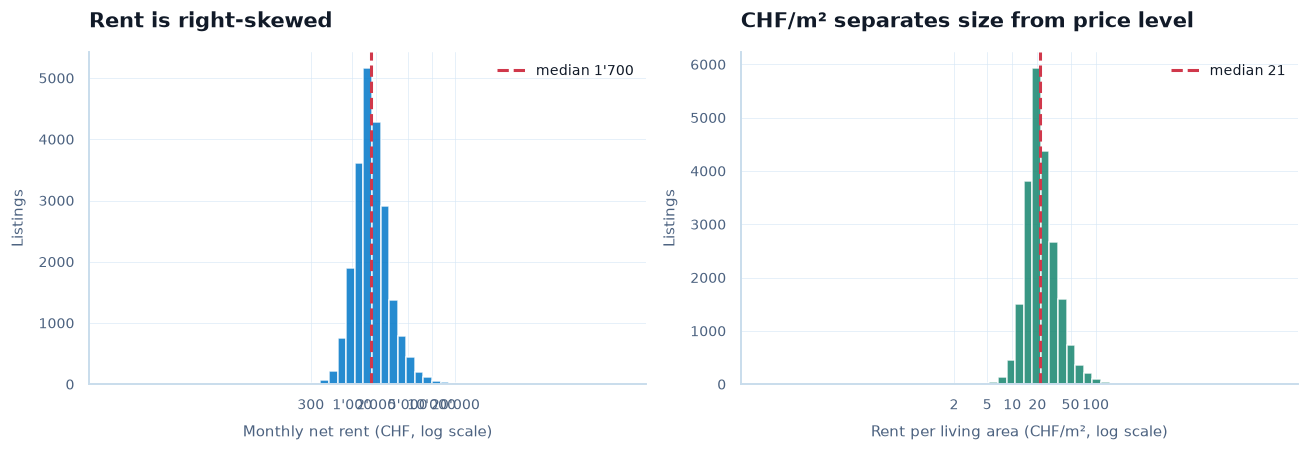

In [6]:
valid = df_raw[(df_raw["price"] > 0) & (df_raw["area"] > 0)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, values, label, color, ticks in [
    (axes[0], valid["price"], "Monthly net rent (CHF, log scale)", COLORS["primary"],
     [300, 1000, 2000, 5000, 10000, 20000]),
    (axes[1], valid["price"] / valid["area"], "Rent per living area (CHF/m², log scale)",
     COLORS["teal"], [2, 5, 10, 20, 50, 100]),
]:
    ax.hist(values, bins=np.logspace(np.log10(values.min()), np.log10(values.max()), 60),
            color=color, alpha=0.85)
    ax.axvline(values.median(), color=COLORS["reference"], ls="--",
               label=f"median {values.median():,.0f}".replace(",", "'"))
    ax.set_xscale("log")
    ax.set_xticks([t for t in ticks if values.min() <= t <= values.max()])
    ax.xaxis.set_major_formatter(chf_formatter())
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set(xlabel=label, ylabel="Listings")
    ax.legend()
axes[0].set_title("Rent is right-skewed")
axes[1].set_title("CHF/m² separates size from price level")
fig.tight_layout()
save_fig(fig, "rent_distribution")
plt.show()

**Reading the audit.** Comparis provides descriptions for practically every listing, so
`HAS_TEXT` is true and the text sections run. If no room count has a half room, the scraper rounded them, so
`rooms_is_integer` is only a missingness indicator and is dropped from the features. On the log
scale the rent is roughly symmetric, which is why all models are trained on `log(price)` and
evaluated in CHF. The CHF/m² tails (parking spaces, placeholders, weekly prices) are what the
outlier filter in section 6 handles.

## 4. Duplicate Audit: From Listings to Rental Objects

The same apartment is often listed several times, here mostly on several partner portals at
once. If copies end up on both sides of a split, the test error is too optimistic, and the
DSPRO1 kNN features could read a listing's own rent from its copy. `comparis_cleaning.ipynb`
linked listings with `data.link_duplicates` (identical anonymised description with equal rooms
and area bucket, exact duplicates, and the same building — enriched EGID, precise coordinates or
address with house number — with equal rooms, area within ±3 m² and rent within ±10 %); linked
listings form one rental object (`object_id`). The audit is reproduced here from the stored links.

In [7]:
object_ids = df_raw["object_id"]
dedup = data.dedup_report(df_raw, object_ids, dup_links)
display(dedup.round(3).to_frame().T)
partners = df_raw.groupby("object_id")["partner"].nunique()
print(f"{len(df_raw):,} listings -> {object_ids.nunique():,} objects; objects on several portals: "
      f"{(partners > 1).sum():,}; listings per object:",
      object_ids.value_counts().value_counts().sort_index().to_dict())
df_obj = df_rent
track("dedup_audit", "data", dedup.to_dict() | {"n_objects": int(object_ids.nunique())},
      params={"area_tol": 3.0, "price_rel_tol": 0.10, "coord_round_m": 5.0,
              "collapse": "median price", "source": "comparis_cleaned.db"})

,rows,unique_objects,duplicate_rows,duplicate_share_pct,objects_with_duplicates,objects_size_2,objects_size_3,objects_size_4plus,max_group_size,median_rel_price_range_dup_objects,links_egid,links_coords,links_address,links_description,links_exact
value,25666.0,23129.0,2537.0,9.885,2103.0,1841.0,182.0,80.0,14.0,0.0,2243.0,2206.0,1887.0,1708.0,1139.0


25,666 listings -> 23,129 objects; objects on several portals: 1,692; listings per object: {1: 21026, 2: 1841, 3: 182, 4: 47, 5: 13, 6: 8, 7: 3, 8: 3, 9: 1, 10: 2, 11: 1, 12: 1, 14: 1}


**Interpretation.** From here on there is **one row per object**: the listing with the smallest
`listing_id`, with the median rent over the object's listings. `object_id` is the group key of
every split and fold. The `rent` table holds only objects that passed the domain rules (area
10–500 m², rent CHF 300–15,000, rooms 1–15), so it has fewer rows than there are objects.

## 5. Geo Hierarchy: Canton > District > Municipality

RQ2 asks whether nested random effects help in **sparsely covered municipalities**, which needs
an official hierarchy for every object. The LV95 coordinates are joined to the municipality
polygons of **swissBOUNDARIES3D** (release 2026-01), which also gives district, canton,
population, land area (without lakes) and the language region. Points in Liechtenstein, Büsingen
or Campione are masked (`admin_match = "none"`).

2,110 municipalities, 144 districts, 26 cantons; admin match: {'within': 19571}
1,634 municipalities have objects (median 4, max 916)


,municipalities,objects,objects share
count,,,
<5,858,1829,0.093
5-20,599,5830,0.298
>20,177,11912,0.609


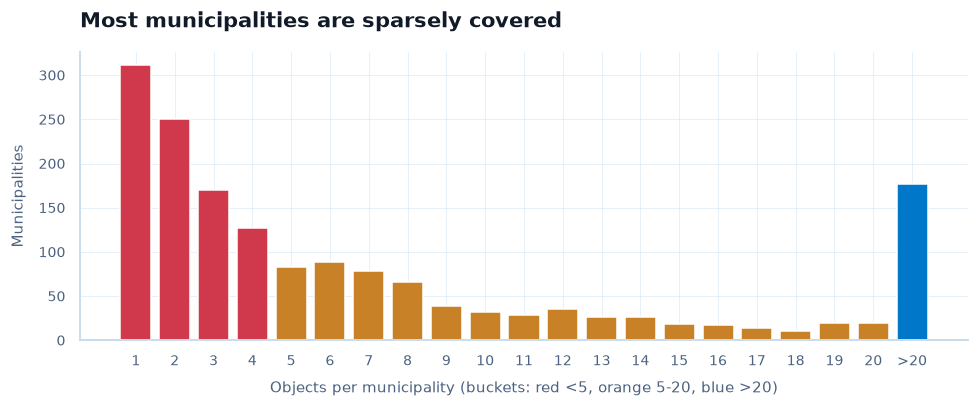

In [8]:
gpkg = geo.download_swissboundaries()  # cached after the first run
admin_units = geo.load_admin_units(gpkg)
df_geo = df_obj.copy()  # admin units assigned in comparis_cleaning.ipynb
df_geo = df_geo.join(geo.nested_group_keys(df_geo))
CANTONS = admin_units[["canton", "geometry"]].dissolve("canton").geometry.simplify_coverage(50)
LAKES = maps.load_lakes(maps.download_lakes())  # BFS lakes, whole polygons in LV95
matched = df_geo[df_geo["admin_match"].ne("none")]
per_muni = matched["municipality_id"].value_counts()
bucket = geo.count_bucket(per_muni)
sparse = pd.DataFrame({"municipalities": bucket.value_counts(sort=False),
                       "objects": per_muni.groupby(bucket, observed=False).sum()})
sparse["objects share"] = (sparse["objects"] / sparse["objects"].sum()).round(3)
print(f"{len(admin_units):,} municipalities, {admin_units['district_id'].nunique()} districts, "
      f"{admin_units['canton'].nunique()} cantons; admin match:",
      df_geo["admin_match"].value_counts().to_dict())
print(f"{per_muni.size:,} municipalities have objects (median {per_muni.median():.0f}, "
      f"max {per_muni.max():,})")
display(sparse)

capped = per_muni.clip(upper=21).value_counts().reindex(range(1, 22), fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar([str(n) for n in capped.index[:-1]] + [">20"], capped.to_numpy(),
       color=[COLORS["reference"] if n < 5 else COLORS["orange"] if n <= 20
              else COLORS["primary"] for n in capped.index])
ax.set(xlabel="Objects per municipality (buckets: red <5, orange 5-20, blue >20)",
       ylabel="Municipalities", title="Most municipalities are sparsely covered")
fig.tight_layout()
save_fig(fig, "objects_per_municipality")
plt.show()

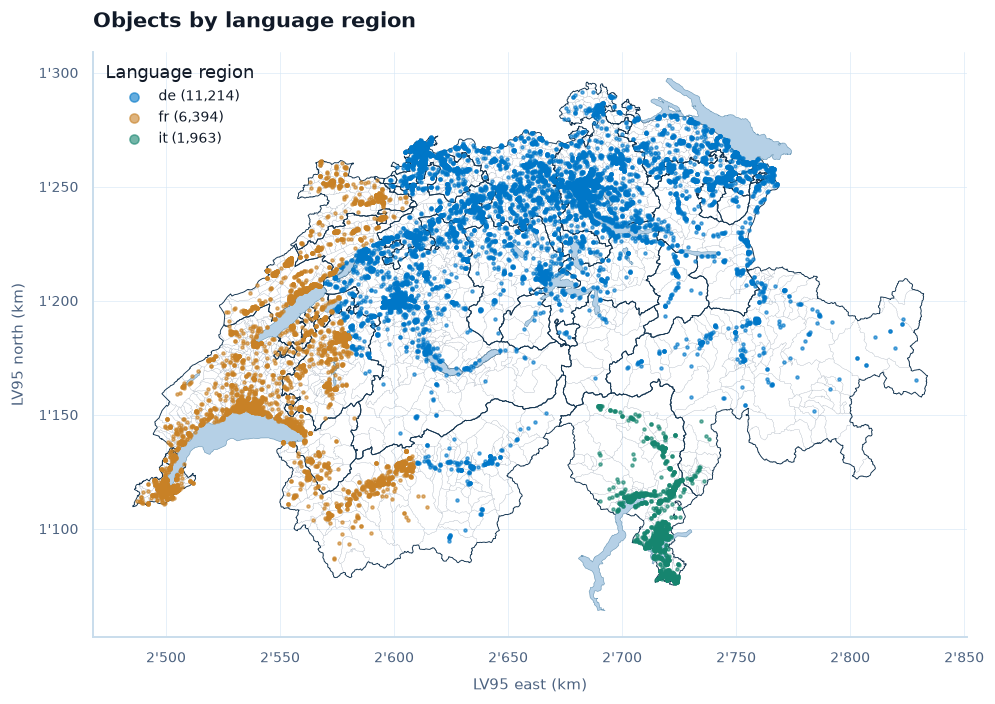

In [9]:
lang_colors = {"de": COLORS["primary"], "fr": COLORS["orange"], "it": COLORS["teal"]}
fig, ax = plt.subplots(figsize=(10, 6.5))
admin_units.geometry.simplify_coverage(50).boundary.plot(ax=ax, color=COLORS["gray"],
                                                       linewidth=0.15,
                                                 alpha=0.5)
CANTONS.boundary.plot(ax=ax, color=COLORS["dark"], linewidth=0.6)
maps.plot_lakes(ax, LAKES)
for lang, part in matched.groupby("lang_region"):
    ax.scatter(part["east"], part["north"], s=4, zorder=3, alpha=0.6, color=lang_colors.get(lang),
               label=f"{lang} ({len(part):,})", rasterized=True)
ax.xaxis.set_major_formatter(KM)
ax.yaxis.set_major_formatter(KM)
ax.set(xlabel="LV95 east (km)", ylabel="LV95 north (km)", aspect="equal",
       title="Objects by language region")
ax.legend(title="Language region", markerscale=3, loc="upper left")
fig.tight_layout()
save_fig(fig, "objects_language_map")
plt.show()

**Interpretation.** The bucket table is the core of RQ2: many municipalities have fewer than 5
objects while most objects sit in the `>20` bucket. A model that treats each municipality on its
own (target encoding) has little to learn from exactly there; nested random effects can borrow
strength from the district and canton. The RQ2 buckets are recomputed in section 10 **from the
training set only**. The language regions later define the Mondrian calibration groups (RQ3); a
thin Italian-speaking region means few calibration objects there.

## 6. Cleaning: Domain Rules and Price-per-m² Outliers

The domain rules ran in `comparis_cleaning.ipynb` (living area 10–500 m², net rent CHF 300–15,000
inclusive, rooms 1–15; this also removes the few "rents" of CHF 100 and less, which are parking
spaces or placeholders). The CHF/m² outliers are **flagged** there (robust z-score of log CHF/m²
within municipality → district → canton → Switzerland, |z| > 3.5) and removed here. The cleaned
objects also feed the map layers (medians only for units with at least `MIN_MAP_CELL` objects).

In [10]:
log = comparis.load_cleaned("cleaning_log")
log = log[log["analysis"].isin(["all", "rent"])].iloc[:5]  # up to the domain rules
df_matched = df_geo[df_geo["admin_match"].ne("none")].copy()
kept = df_matched
ppsqm_flag = kept["ppsqm_outlier"]
df_clean = kept.loc[~ppsqm_flag].copy()
df_ppsqm_outliers = kept.loc[ppsqm_flag].copy()  # never in a split: unfiltered check, section 21

steps = pd.concat([log[["step", "n_rows"]],
                   pd.DataFrame([("price-per-m² outliers", len(df_clean))],
                                columns=["step", "n_rows"])], ignore_index=True)
steps["removed"] = (-steps["n_rows"].diff()).fillna(0).astype(int)
steps["removed_pct"] = 100 * steps["removed"] / steps["n_rows"].shift().fillna(steps["n_rows"])
steps["retained_pct"] = 100 * steps["n_rows"] / steps["n_rows"].iloc[0]
write_table(steps, "cleaning_log", {"removed_pct": ".3g", "retained_pct": ".1f"})
display(steps.round(1))
low = (df_ppsqm_outliers["price"] / df_ppsqm_outliers["area"]
       < (df_clean["price"] / df_clean["area"]).median())
print(f"CHF/m² outliers: {int(low.sum())} low, {int((~low).sum())} high tail, median area "
      f"{df_ppsqm_outliers['area'].median():.0f} m²; area from the GWR: "
      f"{df_clean['area_source'].eq('gwr').sum():,} objects")
map_files = maps.write_map_layers(df_clean, admin_units, out_dir=APP_DIR,
                                 lakes=LAKES)
track("cleaning", "data", {f"n_after_step_{i}": n for i, n in enumerate(steps["n_rows"])},
      params={"z_thresh": data.PPSQM_Z, "min_group": data.PPSQM_MIN_GROUP},
      tables={"cleaning_log": steps})

,step,n_rows,removed,removed_pct,retained_pct
0,raw listings,65552,0,0.0,100.0
1,rentals with monthly price and coordinates,25666,39886,60.8,39.2
2,one row per object (dedup),23129,2537,9.9,35.3
3,admin match in Switzerland,23129,0,0.0,35.3
4,"domain rules (area, rent, rooms)",19571,3558,15.4,29.9
5,price-per-m² outliers,19046,525,2.7,29.1


CHF/m² outliers: 162 low, 363 high tail, median area 28 m²; area from the GWR: 2,179 objects


**Interpretation.** The cleaning log is the audit trail for the report (the steps before the
outlier filter come from `comparis_cleaning.ipynb`). If the CHF/m² filter
removes mostly high-tail objects with a small area, it mainly catches studios or furnished short
stays. Because this filter uses the rent before the split, the flagged objects are kept aside and
scored separately in section 21 as an "unfiltered" robustness check.

---

## Phase 2 — Text, target population and a frozen evaluation design

## 7. Text Preparation: Anonymisation and Language

The description is the new signal of DSPRO2 (RQ1), but it contains **personal data** (revDSG) and
often the **rent itself**, which would let a text model read the target. Every text feature, the
extractor and the LLM therefore only see `description_anon`: contact details and prices become
placeholders, and a leak check measures how many texts still contain a number within ±3 % of
their own rent. The anonymiser is shown on three synthetic listings first.

In [11]:
demo_texts = pd.Series({
    -1: "Schöne 3.5-Zimmer-Wohnung mit Balkon und Seesicht in 8044 Zürich, Baujahr 1995, "
        "renoviert 2021. Mietzins CHF 2'150.– plus Nebenkosten 250.–. Bezug ab 1. Juli 2026. "
        "Kontakt: Frau Anna Muster, Tel. 079 123 45 67, anna.muster@example.ch",
    -2: "Bel appartement de 4 pièces (95 m²) à Lausanne avec ascenseur et balcon, vue sur le "
        "lac. Loyer: 1'980 CHF + charges 180 CHF. Renseignements: M. Jean Dupont, "
        "+41 21 555 12 34, www.regie-exemple.ch",
    -3: "Appartamento di 2.5 locali a Lugano con terrazza e vista lago, 3° piano, ascensore. "
        "Affitto mensile Fr. 1'450.- spese escluse. Contatto: Sig.ra Maria Rossi, "
        "091 987 65 43, maria.rossi@esempio.ch",
}, name="description")
demo_price = pd.Series({-1: 2150.0, -2: 1980.0, -3: 1450.0})
demo_anon = text.anonymize_series(demo_texts)
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame({"language": demo_anon.map(text.detect_language),
                          "before": demo_texts, "after": demo_anon}))
print(f"price leak rate: before {text.price_leak_rate(demo_texts, demo_price):.0%}, "
      f"after {text.price_leak_rate(demo_anon, demo_price):.0%}")

,language,before,after
-1,de,"Schöne 3.5-Zimmer-Wohnung mit Balkon und Seesicht in 8044 Zürich, Baujahr 1995, renoviert 2021. Mietzins CHF 2'150.– plus Nebenkosten 250.–. Bezug ab 1. Juli 2026. Kontakt: Frau Anna Muster, Tel. 079 123 45 67, anna.muster@example.ch","Schöne 3.5-Zimmer-Wohnung mit Balkon und Seesicht in 8044 Zürich, Baujahr 1995, renoviert 2021. Mietzins [PRICE] plus Nebenkosten [PRICE]. Bezug ab 1. Juli 2026. Kontakt: Frau [NAME], Tel. [PHONE], [EMAIL]"
-2,fr,"Bel appartement de 4 pièces (95 m²) à Lausanne avec ascenseur et balcon, vue sur le lac. Loyer: 1'980 CHF + charges 180 CHF. Renseignements: M. Jean Dupont, +41 21 555 12 34, www.regie-exemple.ch","Bel appartement de 4 pièces (95 m²) à Lausanne avec ascenseur et balcon, vue sur le lac. Loyer: [PRICE] + charges [PRICE]. Renseignements: M. [NAME], [PHONE], [URL]"
-3,it,"Appartamento di 2.5 locali a Lugano con terrazza e vista lago, 3° piano, ascensore. Affitto mensile Fr. 1'450.- spese escluse. Contatto: Sig.ra Maria Rossi, 091 987 65 43, maria.rossi@esempio.ch","Appartamento di 2.5 locali a Lugano con terrazza e vista lago, 3° piano, ascensore. Affitto mensile [PRICE] spese escluse. Contatto: Sig.ra [NAME], [PHONE], [EMAIL]"


price leak rate: before 100%, after 0%


price leak rate after anonymisation: 1.79% (target < 1 %); language: {'de': 0.576, 'fr': 0.312, 'it': 0.086, 'unknown': 0.026} | lang_region: {'de': 0.571, 'fr': 0.327, 'it': 0.102}


,kw_balcony,kw_parking,kw_quiet,kw_garage,kw_lift,kw_terrace,kw_own_washer,kw_dishwasher,kw_renovated,kw_furnished,...,kw_new_build,kw_lake_view,kw_temporary,kw_minergie,kw_shared_flat,kw_wheelchair,kw_mountain_view,kw_loft,kw_cooperative,kw_subsidised
prevalence,0.507,0.420,0.366,0.327,0.247,0.244,0.243,0.228,0.197,0.185,...,0.066,0.042,0.033,0.030,0.024,0.022,0.019,0.014,0.003,0.001
ratio,0.951,0.964,0.981,0.956,1.003,1.068,1.061,0.961,1.001,1.125,...,1.154,1.222,1.163,1.117,1.281,1.063,1.095,0.953,0.940,0.879


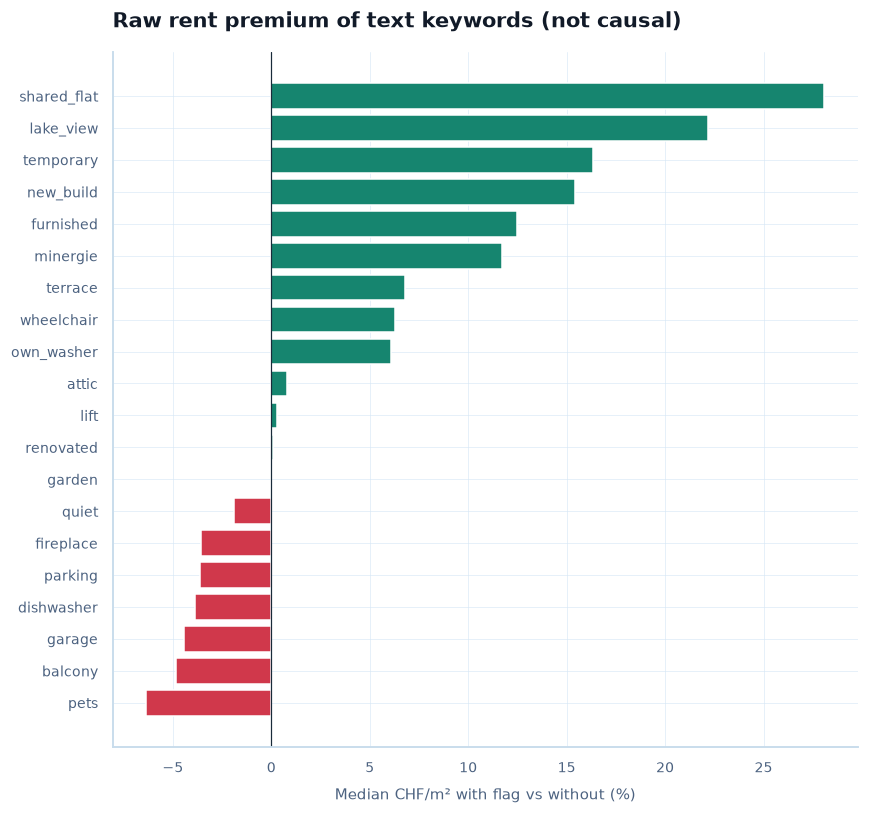

In [12]:
df_text = df_clean.copy()
df_text["description_anon"] = df_text["description"]  # anonymised in comparis_cleaning
df_text["text_lang"] = df_text["description_anon"].map(text.detect_language)
F_TEXT_KW: list[str] = []
if HAS_TEXT:
    LEAK_RATE = text.price_leak_rate(df_text["description_anon"], df_text["price"])
    print(f"price leak rate after anonymisation: {LEAK_RATE:.2%} (target < 1 %); language:",
          df_text["text_lang"].value_counts(normalize=True).round(3).to_dict(),
          "| lang_region:", df_text["lang_region"].value_counts(normalize=True).round(3).to_dict())
    kw = text.keyword_flags(df_text["description_anon"])
    df_text, F_TEXT_KW = df_text.join(kw), list(kw.columns)
    has_desc = df_text["description_anon"].notna()
    ppsqm_text = (df_text["price"] / df_text["area"])[has_desc]
    flags = kw[has_desc].astype(bool)
    kw_table = pd.DataFrame({
        "prevalence": flags.mean(),
        "ratio": flags.apply(lambda f: ppsqm_text[f].median() / ppsqm_text[~f].median()),
    }).sort_values("prevalence", ascending=False)
    display(kw_table.round(3).T)
    shown = kw_table[kw_table["prevalence"] >= 0.02].sort_values("ratio")
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(shown) + 1.5))
    ax.barh(shown.index.str.removeprefix("kw_"), (shown["ratio"] - 1) * 100,
            color=[COLORS["teal"] if r >= 1 else COLORS["reference"] for r in shown["ratio"]])
    ax.axvline(0, color=COLORS["neutral"], lw=0.8)
    ax.set(xlabel="Median CHF/m² with flag vs without (%)",
           title="Raw rent premium of text keywords (not causal)")
    fig.tight_layout()
    save_fig(fig, "keyword_premium")
    plt.show()
else:
    print(f"No descriptions (data source {DATA_USED}): text features skipped.")

**Interpretation.** Names, phone numbers, e-mail addresses, URLs and rent figures become
placeholders, while rooms, area, construction year and postcode stay, because they are legitimate
features. On real data the leak rate should stay below 1 %; a small floor is expected, since years
or postcodes can coincidentally lie within ±3 % of a rent. The keyword premium is descriptive: it
mixes the feature with location and size, so only the ablation in section 17 can say whether the
text improves the model.

## 8. Attribute Extraction and Rent Regime

The proposal asks for **structured attributes** with text evidence (floor, lift, balcony, view,
renovation year, furnished, parking, …) and a **rent-regime label**: cooperative, cost-based or
subsidised rents and rooms in shared flats sit below the market level, so they are removed from
the market-rent target and reported separately.

Two extractors share one schema. The **rules** are free, deterministic and return the verbatim
evidence span. The **LLM extractor** (Claude, structured JSON output, cached per text) runs live
only on a capped, language-stratified sample and is compared with the rules. Once a batch run has
cached **every** description, its labels replace the rules row by row (`ATTR_SOURCE`).

In [13]:
with pd.option_context("display.max_colwidth", 120):
    display(text.extract_frame(demo_anon, text.rule_based_extract, include_evidence=True)
            .drop(columns="extractor").T)
attr_frame = None
ATTR_SOURCE = "none"
if HAS_TEXT:
    attr_frame = text.extract_frame(df_text["description_anon"], text.rule_based_extract,
                                    include_evidence=True)
    ATTR_SOURCE = "rules"
    attr_cols = [c for c in attr_frame if c.startswith("attr_")]
    attr_coverage = attr_frame.loc[df_text["description_anon"].notna(), attr_cols].notna().mean()
    display(attr_coverage.sort_values(ascending=False).round(3).to_frame("found in text").T)


def per_language_sample(frame: pd.DataFrame, n_per_lang: int) -> pd.DataFrame:
    parts = [g.sample(min(len(g), n_per_lang), random_state=RANDOM_STATE)
             for lang, g in frame.groupby("text_lang") if lang in ("de", "fr", "it")]
    return pd.concat(parts) if parts else frame.iloc[0:0]

,-1,-2,-3
attr_floor,NaN,NaN,3.0
attr_has_lift,NaN,1.0,1.0
attr_has_balcony_or_terrace,1.0,1.0,1.0
attr_view,lake,lake,lake
attr_renovation_year,2021.0,NaN,NaN
attr_is_furnished,NaN,NaN,NaN
attr_is_temporary,NaN,NaN,NaN
attr_parking,none,none,none
attr_is_minergie,NaN,NaN,NaN
attr_pets_allowed,NaN,NaN,NaN


,attr_view,attr_parking,attr_has_balcony_or_terrace,attr_rooms,attr_area_sqm,attr_floor,attr_has_own_washer,attr_has_lift,attr_is_furnished,attr_has_garden,attr_is_attic,attr_is_new_build,attr_pets_allowed,attr_renovation_year,attr_is_temporary,attr_is_minergie
found in text,1.0,1.0,0.688,0.677,0.333,0.327,0.289,0.247,0.191,0.177,0.103,0.066,0.062,0.054,0.035,0.03


In [14]:
extractor = None
if HAS_TEXT and RUN_LLM and os.environ.get("ANTHROPIC_API_KEY"):
    from rentml.llm import ClaudeExtractor  # optional "llm" extra

    extractor = ClaudeExtractor(cache_path=CACHE / "extraction.jsonl")
    sample = per_language_sample(df_text.dropna(subset=["description_anon"]), 10 if FAST else 100)
    llm_frame = text.extract_frame(sample["description_anon"], extractor, errors="ignore")
    fields = [f for f in text.ATTRIBUTE_FIELDS if f"attr_{f}" in llm_frame]
    # rules scored against the LLM labels: an agreement check, not an accuracy estimate
    display(text.evaluate_extraction(attr_frame.loc[llm_frame.index], llm_frame, fields)
            .set_index("field").round(3))
    pending = extractor.batch_requests(df_text["description_anon"])
    if pending:
        print(f"LLM cache misses {len(pending):,} descriptions: the rules are used. Fill the "
              "cache with extractor.submit_batch(pending) and extractor.collect_batch(ids).")
    else:  # every description cached: LLM labels without API calls, rules as fallback
        llm_all = text.extract_frame(df_text["description_anon"], extractor, errors="ignore",
                                     include_evidence=True)
        ok = llm_all["extractor"].notna()
        attr_frame = llm_all.where(ok, attr_frame, axis=0)
        ATTR_SOURCE = "llm"

gold_path = INTERIM / "extraction_gold.csv"
if HAS_TEXT and gold_path.is_file():
    gold = pd.read_csv(gold_path, index_col="listing_id")
    fields = [f for f in text.ATTRIBUTE_FIELDS if f in gold or f"attr_{f}" in gold]
    extraction_eval = text.evaluate_extraction(attr_frame, gold, fields, by=df_text["text_lang"])
    write_table(extraction_eval, "extraction_eval_rules", ".3f")
    display(extraction_eval.round(3))
elif HAS_TEXT:
    todo = per_language_sample(df_text.dropna(subset=["description_anon"]), 100)
    template = INTERIM / "extraction_gold_template.csv"
    todo[["text_lang", "description_anon"]].join(
        pd.DataFrame("", index=todo.index, columns=list(text.ATTRIBUTE_FIELDS))).to_csv(template)
    print(f"No gold labels yet: wrote {len(todo)} texts to {template.name} for hand labelling.")
print(f"ATTR_SOURCE = {ATTR_SOURCE!r} (attribute stage S3 and rent-regime filter)")

No gold labels yet: wrote 300 texts to extraction_gold_template.csv for hand labelling.
ATTR_SOURCE = 'rules' (attribute stage S3 and rent-regime filter)


In [15]:
# The rule-based regime and the shared-flat flag (single rooms, portal flag) come from the
# cleaning notebook; complete LLM labels replace the rules, shared flats stay shared flats.
if ATTR_SOURCE == "llm":
    shared = df_text["rent_regime"].eq("shared_flat")
    df_text["rent_regime"] = attr_frame["rent_regime"].fillna("unknown").mask(shared, "shared_flat")
df_market, df_excluded = data.regime_split(df_text)
display(df_text.assign(ppsqm=df_text["price"] / df_text["area"]).groupby("rent_regime")
        .agg(objects=("price", "size"), median_rent=("price", "median"),
             median_chf_per_m2=("ppsqm", "median")).round(1))
print(f"market-rent target: {len(df_market):,} objects; excluded: {len(df_excluded):,}")
if HAS_TEXT:
    track("attribute_extraction", "data",
          {"leak_rate": LEAK_RATE, "n_market": len(df_market), "n_excluded": len(df_excluded)},
          params={"extractor": ATTR_SOURCE},
          tables={"attribute_coverage": attr_coverage.to_frame()})

,objects,median_rent,median_chf_per_m2
rent_regime,,,
cooperative,56,1590.0,19.7
cost_based_or_subsidised,7,2070.0,20.5
market,18681,1710.0,20.9
shared_flat,302,900.0,43.3


market-rent target: 18,681 objects; excluded: 365


**Interpretation.** A field without evidence stays missing instead of being guessed. If
cooperative or subsidised objects have a clearly lower CHF/m² than market objects, removing them
makes the target more homogeneous; without text every object is "unknown" and counts as market
rent, so the target may still contain some non-market rents. The LLM agreement and the
gold-label evaluation show per language whether the cheaper rules are good enough.

## 9. Feature Engineering and Feature Sets

The engineered features are the DSPRO1 ones with a real-estate reading (area per room, building
age, land area per apartment) plus coordinates rotated by 45°, which let axis-aligned splits
follow diagonal price gradients such as lake shores. The feature lists are defined once:

- `F_TAB`: listing, building and location features without coordinates or encodings;
- `F_GEO_LGBM`: `F_TAB` plus LV95 and rotated coordinates (target encodings are added inside CV);
- `GROUP_COLS`: the nested keys canton > district > municipality;
- `F_TEXT_KW`, `F_ATTR`: keyword flags and extracted attributes (empty without text);
- `F_PORTAL`: structured portal fields (floor, renovation year, balconies, house, lift and
  other `has_*`/`is_*` flags stated by at least 1 % of the objects, `area_from_gwr`). They are
  not in `F_TAB`, because the app cannot ask for them yet; section 17 tests them as an
  exploratory stage `P`.

**Schema fix from the text.** Comparis publishes half rooms; the text only fills a missing
room count (or a half room within 0.5 of a whole stored count).

In [16]:
df_base = df_market
F_ATTR: list[str] = []
if attr_frame is not None:
    rooms_fixed, rooms_source = data.recover_rooms_from_text(df_market["rooms"],
                                                             attr_frame["attr_rooms"])
    df_base = df_market.assign(rooms=rooms_fixed)
    ROOMS_INTEGER_ONLY = bool((df_base["rooms"].dropna() % 1 == 0).all())
    print("room counts by source:", rooms_source.value_counts().to_dict())
df_model = data.add_engineered_features(df_base)
df_model["log_price"] = np.log(df_model["price"])
if attr_frame is not None:
    attr_all = [c for c in attr_frame if c.startswith("attr_")]
    df_model = df_model.join(attr_frame[attr_all])
    F_ATTR = [c for c in attr_all if c not in ("attr_area_sqm", "attr_rooms")]  # schema fix only

df_model["is_house"] = df_model["property_category"].eq("house").astype(float)
df_model["area_from_gwr"] = df_model["area_source"].eq("gwr").astype(float)
PORTAL_FLAGS = sorted(c for c in df_model if c.startswith(("has_", "is_"))
                      and c not in ("is_flat_share", "is_house")
                      and df_model[c].mean() >= 0.01)
F_PORTAL = ["floor", "renovation_year", "balcony_count", "is_house", "area_from_gwr",
            *PORTAL_FLAGS]
F_TAB = [c for c in data.BASE + data.BUILDING + data.LOCATION
         if not (c == "rooms_is_integer" and ROOMS_INTEGER_ONLY)]
COORDS = data.COORDS
F_GEO_LGBM = F_TAB + COORDS + data.ROT_COORDS
GROUP_COLS = ["re_canton", "re_district", "re_municipality"]
TE_INPUT = F_GEO_LGBM + GROUP_COLS
assert not [c for c in TE_INPUT + F_TEXT_KW + F_ATTR + F_PORTAL if c not in df_model]
print(f"df_model: {len(df_model):,} objects; F_TAB ({len(F_TAB)}): {F_TAB}")

FEATURE_DESCRIPTIONS = {
    "area": "living area (m²)", "rooms": "number of rooms (NaN if implausible)",
    "area_per_room": "area / rooms (m² per room)",
    "rooms_is_integer": "whole room count (missingness indicator on DSPRO1 data)",
    "year_built": "construction year (GWR, period midpoint, else listing)",
    "building_age": f"{REFERENCE_YEAR} − year built",
    "apartments": "dwellings in the building (GWR)", "land_area": "GWR building area (m²)",
    "land_area_per_apartment": "GWR building area per dwelling (m²)",
    "population": "STATPOP population of the hectare (geo.admin)",
    "oev": "public-transport quality score", "solar": "solar suitability class",
    "elevation": "elevation (m a.s.l.)",
    "muni_density": "inhabitants per km² of municipal land area (lakes excluded)",
    "muni_population": "municipal population (swissBOUNDARIES3D)",
    "east": "LV95 east (m)", "north": "LV95 north (m)",
    "rot45_x": "LV95 rotated by 45° (x)", "rot45_y": "LV95 rotated by 45° (y)",
    "re_canton": "canton key", "re_district": "canton/district key",
    "re_municipality": "canton/district/municipality key",
}  # fmt: skip
feature_table = pd.DataFrame(
    [("tabular", c) for c in F_TAB] + [("coordinates", c) for c in COORDS + data.ROT_COORDS]
    + [("hierarchy (RE / TE)", c) for c in GROUP_COLS]
    + [("text keywords", c) for c in F_TEXT_KW] + [("text attributes", c) for c in F_ATTR]
    + [("portal attributes", c) for c in F_PORTAL],
    columns=["group", "feature"])
feature_table["description"] = feature_table["feature"].map(FEATURE_DESCRIPTIONS).fillna(
    feature_table["feature"].str.replace("_", " "))
feature_table["missing %"] = [round(100 * df_model[c].isna().mean(), 1)
                              for c in feature_table["feature"]]
write_table(feature_table, "feature_table")
feature_table.style.hide(axis="index")

room counts by source: {'table': 17909, 'text_half_room': 674, 'text_missing': 60, 'missing': 38}
df_model: 18,681 objects; F_TAB (15): ['area', 'rooms', 'area_per_room', 'rooms_is_integer', 'year_built', 'building_age', 'apartments', 'land_area', 'land_area_per_apartment', 'population', 'oev', 'solar', 'elevation', 'muni_density', 'muni_population']


group,feature,description,missing %
tabular,area,living area (m²),0.000000
tabular,rooms,number of rooms (NaN if implausible),0.200000
tabular,area_per_room,area / rooms (m² per room),0.200000
tabular,rooms_is_integer,whole room count (missingness indicator on DSPRO1 data),0.200000
tabular,year_built,"construction year (GWR, period midpoint, else listing)",10.900000
tabular,building_age,2026 − year built,10.900000
tabular,apartments,dwellings in the building (GWR),18.600000
tabular,land_area,GWR building area (m²),14.400000
tabular,land_area_per_apartment,GWR building area per dwelling (m²),18.700000
tabular,population,STATPOP population of the hectare (geo.admin),12.400000


**Interpretation.** The building and location features now exist for every object whose
address or precise coordinate led to a GWR building, instead of the DSPRO1-enriched half; the
missing shares in the feature table show what remains (mostly listings with a municipality
centroid and no house number). The tree models handle the gaps natively. `muni_density` and
`muni_population` are complete, so every object has some municipal context.

## 10. Train / Calibration / Test Split and Cross-Validation Folds

The split is made **once**, before any model is compared, and frozen: 60 % train (fitting, tuning,
grouped CV), 20 % calibration (only for the conformal intervals) and 20 % test (only for the final
comparisons). It is grouped by `object_id` and stratified by canton × price quartile, and reused
as long as the set of objects does not change. The listings-per-municipality buckets for RQ2 are
counted **on the training set only**: a test object in a municipality with fewer than 5 training
objects is exactly the sparse case of RQ2.

In [17]:
strata = data.make_strata(df_model)
split_col = data.train_calib_test_split(df_model, strata)
split_file = INTERIM / f"split_v1_{DATA_USED}.parquet"
if split_file.is_file():
    frozen = pd.read_parquet(split_file)["split"]
    if frozen.index.sort_values().equals(df_model.index.sort_values()):
        print(f"reusing frozen {split_file.name}; equal to a fresh split: "
              f"{frozen.reindex(split_col.index).eq(split_col).all()}")
        split_col = frozen
    else:
        print(f"{split_file.name} covers other objects (data changed): writing a new split")
split_col.rename_axis("listing_id").to_frame().to_parquet(split_file)
df_model["split"] = split_col.reindex(df_model.index)
assert df_model.groupby("object_id")["split"].nunique().max() == 1, "object on two sides"

muni_counts_train = df_model.loc[df_model["split"].eq("train"), "municipality_id"].value_counts()
df_model["muni_bucket"] = geo.count_bucket(df_model["municipality_id"].map(muni_counts_train))
train_df, calib_df, test_df = (df_model[df_model["split"].eq(s)]
                               for s in ("train", "calib", "test"))
display(df_model.groupby("split").agg(n=("price", "size"), price_median=("price", "median"),
                                      area_median=("area", "median"),
                                      cantons=("canton", "nunique"))
        .join(pd.crosstab(df_model["split"], df_model["lang_region"], normalize="index")
              .add_prefix("lang_"))
        .join(pd.crosstab(df_model["split"], df_model["muni_bucket"], normalize="index")
              .add_prefix("bucket_")).loc[["train", "calib", "test"]].round(3))

cv_folds = data.grouped_cv_folds(train_df, strata, n_splits=BUDGET["cv_folds"])
spatial_folds = data.spatial_cv_folds(train_df, n_splits=BUDGET["cv_folds"])
munis = train_df["municipality_id"].to_numpy()
assert all(not set(munis[tr]) & set(munis[va]) for tr, va in spatial_folds)
print(f"{len(cv_folds)} grouped and {len(spatial_folds)} spatial folds on {len(train_df):,} "
      "training objects")
track("splits", "data", {"n_train": len(train_df), "n_calib": len(calib_df),
                         "n_test": len(test_df), "n_municipalities_train": len(muni_counts_train)},
      params={"fractions": "0.6/0.2/0.2", "cv_folds": BUDGET["cv_folds"]})

reusing frozen split_v1_comparis.parquet; equal to a fresh split: True


,n,price_median,area_median,cantons,lang_de,lang_fr,lang_it,bucket_<5,bucket_5-20,bucket_>20
split,,,,,,,,,,
train,11208,1710.5,85.0,26,0.570,0.327,0.103,0.156,0.363,0.481
calib,3736,1716.5,85.0,26,0.568,0.329,0.103,0.196,0.328,0.477
test,3737,1710.0,85.0,26,0.572,0.326,0.102,0.202,0.315,0.483


5 grouped and 5 spatial folds on 11,208 training objects


**Interpretation.** Close medians, language and bucket shares across the three sets mean the
stratification worked. The test set has a **larger** `<5` share than the training set suggests,
because buckets are counted on training objects only; this mirrors deployment, where many
municipalities have few observed listings. Grouped folds select and tune models; spatial folds,
which hold out whole municipalities, are the harder robustness check.

## 11. Pre-Registered Evaluation Plan and Minimum Detectable Effect

Before the first comparison, [`docs/EVALUATION_PLAN.md`](../docs/EVALUATION_PLAN.md) fixes the
metric, hypotheses, tests, order of decisions and budgets; the constants live in `rentml.config`.
The open number is the **minimum detectable effect (MDE)**: which MAE difference a paired test on
this test set detects with 80 % power. It is simulated from real out-of-fold errors of a
DSPRO1-like LightGBM (`F_TAB` + coordinates); a LightGBM without coordinates supplies the pairing
(how strongly the errors of two models move together).

| Item | Value |
|---|---|
| primary metric | MAE in CHF on the frozen hold-out test set |
| significance level α | 0.05 |
| paired bootstrap resamples | 2000 |
| multiple testing | Holm across the RQ1 ablation stages |
| split | 60/20/20, grouped by `object_id`, stratified canton × price quartile |
| CV folds / Optuna trials | 5 / 60 |
| interval coverage, quantile levels | 0.80; 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95 |
| min. calibration objects per Mondrian cell | 100 |
| min. objects per published map cell | 20 |
| order of decisions | RQ2 → RQ1 (on the RQ2 winner) → RQ3 (on that model) |

The fast smoke run (`DSPRO2_RUN_MODE=fast`) only lowers the budgets in `BUDGET`.

In [18]:
y_train, y_train_log = train_df["price"].to_numpy(), train_df["log_price"].to_numpy()
y_calib, y_test = calib_df["price"].to_numpy(), test_df["price"].to_numpy()
abs_err_geo = np.abs(y_train - np.exp(models.fit_predict_cv(
    models.make_lgbm, train_df[F_TAB + COORDS], y_train_log, cv_folds)))
abs_err_tab = np.abs(y_train - np.exp(models.fit_predict_cv(
    models.make_lgbm, train_df[F_TAB], y_train_log, cv_folds)))
power = evaluation.power_mde(abs_err_geo, abs_err_tab,
                             test_sizes=sorted({len(test_df), 2000, 3000, 4000, 5000, 6000}),
                             rel_effects=np.round(np.arange(0.005, 0.1005, 0.005), 3),
                             n_sim=BUDGET["power_sims"], seed=RANDOM_STATE)
ERROR_RHO = float(np.corrcoef(abs_err_geo, abs_err_tab)[0, 1])
PAIR_SD_RATIO = float(abs_err_tab.std() / abs_err_geo.std())
mde_table = power.groupby("test_size")[["mde_rel", "mde_chf"]].first()
mde_md = pd.DataFrame({
    "Test-set size": [f"{n:,}".replace(",", "'") + (" (this test set)" if n == len(test_df)
                                                    else "") for n in mde_table.index],
    "MDE (relative MAE reduction)": [f"{r:.1%}" if pd.notna(r) else "> 10 %"
                                     for r in mde_table["mde_rel"]],
    "MDE (CHF)": [f"{c:.0f}" if pd.notna(c) else "–" for c in mde_table["mde_chf"]],
})
write_table(mde_md, "mde_table", note=f"power_mde: n_sim={BUDGET['power_sims']}, "
            f"rho={ERROR_RHO:.2f}, reference CV MAE={abs_err_geo.mean():.0f} CHF, "
            f"data={DATA_USED}, run={RUN_MODE}")
print(f"CV MAE: F_TAB + coordinates {abs_err_geo.mean():,.1f} CHF, F_TAB only "
      f"{abs_err_tab.mean():,.1f} CHF; error correlation rho = {ERROR_RHO:.2f}")
display(mde_md.style.hide(axis="index"))

CV MAE: F_TAB + coordinates 332.5 CHF, F_TAB only 382.2 CHF; error correlation rho = 0.91


Test-set size,MDE (relative MAE reduction),MDE (CHF)
2'000,4.5%,15
3'000,4.0%,13
3'737 (this test set),3.5%,12
4'000,3.5%,12
5'000,3.0%,10
6'000,3.0%,10


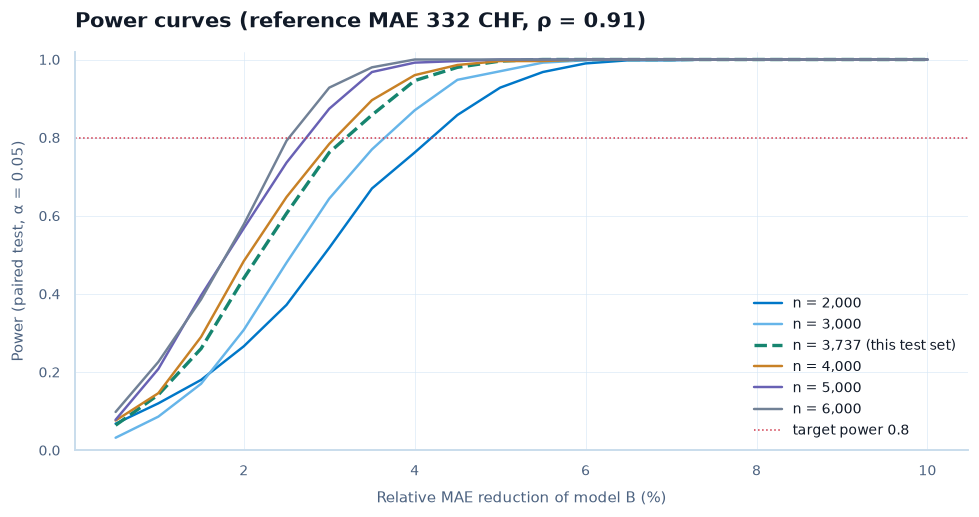

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for color, (n, part) in zip(PALETTE, power.groupby("test_size"), strict=False):
    is_test = n == len(test_df)
    ax.plot(part["rel_effect"] * 100, part["power"], color=color, lw=2.2 if is_test else 1.6,
            ls="--" if is_test else "-", label=f"n = {n:,}" + (" (this test set)" * is_test))
ax.axhline(0.8, color=COLORS["reference"], lw=1, ls=":", label="target power 0.8")
ax.set(xlabel="Relative MAE reduction of model B (%)", ylabel="Power (paired test, α = 0.05)",
       ylim=(0, 1.02),
       title=f"Power curves (reference MAE {abs_err_geo.mean():,.0f} CHF, ρ = {ERROR_RHO:.2f})")
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
save_fig(fig, "power_curves")
plt.show()
track("power_mde", "eval-plan",
      {"cv_mae": abs_err_geo.mean(), "cv_mae_tab": abs_err_tab.mean(), "error_rho": ERROR_RHO,
       "pair_sd_ratio": PAIR_SD_RATIO}
      | {f"mde_rel_{n}": v for n, v in mde_table["mde_rel"].items()},
      params={"n_sim": BUDGET["power_sims"], "reference": "lgbm F_TAB+COORDS",
              "pairing": "lgbm F_TAB"}, tables={"mde_table": mde_table})

**Interpretation.** The MDE is where a curve crosses 0.8. The more strongly two models' errors move
together (higher ρ), the smaller the detectable effect. Pairing with a model without coordinates
is deliberately conservative; the RQ1/RQ2 comparisons are between closer models. A
non-significant result below the MDE is "no detectable difference", not "no difference", and the
per-bucket RQ2 comparisons, with far fewer test objects, are exploratory by design.

**Before tagging `eval-plan-v1`:** run once in full mode on the frozen data source, copy
`docs/results/mde_table.md` into section 4 of `EVALUATION_PLAN.md`, add a changelog line, commit
and tag. Only then are the models below compared.

---

## Phase 3 — Location: baselines, spatial mixed effects and the RQ2 decision

## 12. Baselines: Naive Rate, DSPRO1 Reproduction and Learning Curve

Every model has to beat two references. The **naive baseline** is the landlord's rule of thumb:
median CHF/m² of the municipality times the living area, falling back to district, canton and
Switzerland below 5 training objects. The **DSPRO1 recipe** is LightGBM with the mean and median
rent of the 10 nearest training listings as features. All other models are trained on
`log_price` and evaluated in CHF on the same grouped folds and the same frozen test objects;
`pred_test`, `pred_calib` and `cv_oof` collect the CHF predictions of every model.

In [20]:
BUCKETS = list(geo.COUNT_BUCKET_ORDER)
BUCKET_KEYS = {"<5": "lt5", "5-20": "5_20", ">20": "gt20"}
bucket_test = test_df["muni_bucket"].astype(str).to_numpy()
pred_test: dict[str, np.ndarray] = {}
pred_calib: dict[str, np.ndarray] = {}
cv_oof: dict[str, np.ndarray] = {}


def test_metrics(pred: np.ndarray) -> dict[str, float]:
    out = {f"test_{k.lower()}": v
           for k, v in evaluation.regression_metrics(y_test, pred).items()}
    return out | {f"test_mae_{key}": mae(y_test[bucket_test == b], pred[bucket_test == b])
                  for b, key in BUCKET_KEYS.items()}


def run_metrics(name: str) -> dict[str, float]:
    return {"cv_mae": mae(y_train, cv_oof[name]), "calib_mae": mae(y_calib, pred_calib[name]),
            **test_metrics(pred_test[name])}

In [21]:
naive = models.NaiveMunicipalityBaseline().fit(train_df, y_train)
pred_test["naive"], pred_calib["naive"] = naive.predict(test_df), naive.predict(calib_df)
cv_oof["naive"] = np.exp(models.fit_predict_cv(
    lambda: models.NaiveMunicipalityBaseline(log_target=True), train_df, y_train_log, cv_folds))
track("naive", "baseline", run_metrics("naive"), tags={"model": "naive"},
      params={"levels": "municipality>district>canton>national", "min_count": 5})
m = test_metrics(pred_test["naive"])
print(f"naive: CV MAE {mae(y_train, cv_oof['naive']):,.0f}, test MAE {m['test_mae']:,.0f} CHF "
      f"(R² {m['test_r2']:.3f}); per bucket: "
      + ", ".join(f"{b} {m[f'test_mae_{k}']:,.0f}" for b, k in BUCKET_KEYS.items()))
naive.rate_source(test_df).value_counts(normalize=True).rename("share of test objects").to_frame().T

naive: CV MAE 441, test MAE 429 CHF (R² 0.703); per bucket: <5 439, 5-20 426, >20 427


rate_source,municipality_id,district_id,canton
share of test objects,0.798234,0.200428,0.001338


**Interpretation.** The naive MAE is the floor every model must clearly beat. Every test object
whose rate comes from the district or canton sits in a municipality with fewer than 5 training
objects; the larger that share, the more the result depends on how a model handles sparse
municipalities, which is RQ2.

### 12.1 DSPRO1 reproduction: are leave-one-out kNN rent features leaky?

DSPRO1 computed the kNN features of a training listing **leave-one-out**: the listing itself is
excluded, but a relisting of the same apartment is not, and its rent enters the "neighbourhood"
median. Four protocols with the same LightGBM, features (`F_TAB` + coordinates + kNN mean/median)
and test objects make this measurable:

| | Training rows | kNN features of training rows | CV folds |
|---|---|---|---|
| A | **listings** incl. relistings (as in DSPRO1) | leave-one-out | random K-fold (as in DSPRO1) |
| B | listings incl. relistings | leave-one-out | grouped by object |
| C | **objects** (after the duplicate audit) | leave-one-out | grouped by object |
| D | objects | **out-of-fold** | grouped by object |

A CV score is never exactly the test score (each CV model sees (K−1)/K of the data), so the leak
shows up as **optimism relative to D**: `(test − CV)` of D minus `(test − CV)` of a protocol.

In [22]:
# DSPRO1 trained on listings: expand every training object back to its listings (own rents)
obj_pos = pd.Series(np.arange(len(train_df)), index=train_df["object_id"].to_numpy())
listing_obj = object_ids[object_ids.isin(obj_pos.index)]
listing_obj = listing_obj[df_raw.loc[listing_obj.index, "price"].gt(0).to_numpy()]
lst_pos = obj_pos.loc[listing_obj.to_numpy()].to_numpy()
train_listings = (train_df.iloc[lst_pos].set_axis(listing_obj.index)
                  .assign(price=df_raw.loc[listing_obj.index, "price"].to_numpy()))
folds_listing = [(np.flatnonzero(np.isin(lst_pos, tr)), np.flatnonzero(np.isin(lst_pos, va)))
                 for tr, va in cv_folds]
folds_random = list(KFold(len(cv_folds), shuffle=True, random_state=RANDOM_STATE)
                    .split(train_listings))
F_DSPRO1 = F_TAB + COORDS + ["knn_price_mean", "knn_price_median"]


def dspro1_knn(frame: pd.DataFrame, folds: list, mode: str) -> dict:
    # DSPRO1 recipe: kNN rent features + LightGBM; OOF on `frame`, then refit -> calib/test.
    knn = data.knn_price_features(frame, mode=mode, folds=folds)
    X, y_log = frame[F_TAB + COORDS].join(knn), np.log(frame["price"].to_numpy())
    oof = np.exp(models.fit_predict_cv(models.make_lgbm, X[F_DSPRO1], y_log, folds))
    model = models.make_lgbm().fit(X[F_DSPRO1], y_log)
    out = {"oof": oof, "cv_mae": mae(frame["price"], oof)}
    for split, new in (("calib", calib_df), ("test", test_df)):
        X_new = new[F_TAB + COORDS].join(data.knn_price_features(frame, apply_df=new))
        out[split] = np.exp(model.predict(X_new[F_DSPRO1]))
    return out


PROTOCOLS = {
    "A": ("DSPRO1: listings, LOO kNN, random folds", train_listings, folds_random, "loo"),
    "B": ("listings, LOO kNN, grouped folds", train_listings, folds_listing, "loo"),
    "C": ("objects, LOO kNN, grouped folds", train_df, cv_folds, "loo"),
    "D": ("objects, OOF kNN, grouped folds", train_df, cv_folds, "oof"),
}
knn_runs = {k: dspro1_knn(frame, folds, mode) for k, (_, frame, folds, mode) in PROTOCOLS.items()}
leak_table = pd.DataFrame({
    "key": list(PROTOCOLS), "protocol": [p[0] for p in PROTOCOLS.values()],
    "training rows": [len(p[1]) for p in PROTOCOLS.values()],
    "cv_mae": [r["cv_mae"] for r in knn_runs.values()],
    "test_mae": [mae(y_test, r["test"]) for r in knn_runs.values()],
}).set_index("key", drop=False)
leak_table["test_minus_cv"] = leak_table["test_mae"] - leak_table["cv_mae"]
leak_table["optimism_vs_D"] = leak_table["test_minus_cv"] - leak_table.loc["D", "test_minus_cv"]
write_table(leak_table, "dspro1_knn_leakage", ".1f")
print(f"{len(train_listings):,} training listings for {len(train_df):,} objects")
display(leak_table.set_index("key").round(1))

# DSPRO1 benchmark recipe (B) with object-level OOF (mean over an object's listings), clean D
pred_test["dspro1_knn"], pred_calib["dspro1_knn"] = knn_runs["B"]["test"], knn_runs["B"]["calib"]
cv_oof["dspro1_knn"] = (pd.Series(knn_runs["B"]["oof"]).groupby(lst_pos).mean()
                        .reindex(range(len(train_df))).to_numpy())
pred_test["dspro1_knn_oof"] = knn_runs["D"]["test"]
pred_calib["dspro1_knn_oof"] = knn_runs["D"]["calib"]
cv_oof["dspro1_knn_oof"] = knn_runs["D"]["oof"]
for name, mode, rows in [("dspro1_knn", "loo", "listings"), ("dspro1_knn_oof", "oof", "objects")]:
    track(name, "dspro1", run_metrics(name), tags={"model": name},
          params={"knn_mode": mode, "k": 10, "training_rows": rows,
                  "features": "F_TAB+COORDS+knn"},
          tables={"dspro1_knn_leakage": leak_table} if mode == "loo" else None)

12,544 training listings for 11,208 objects


,protocol,training rows,cv_mae,test_mae,test_minus_cv,optimism_vs_D
key,,,,,,
A,"DSPRO1: listings, LOO kNN, random folds",12544,309.3,320.3,11.0,26.5
B,"listings, LOO kNN, grouped folds",12544,330.6,320.3,-10.3,5.2
C,"objects, LOO kNN, grouped folds",11208,332.5,317.4,-15.2,0.4
D,"objects, OOF kNN, grouped folds",11208,337.5,321.9,-15.5,0.0


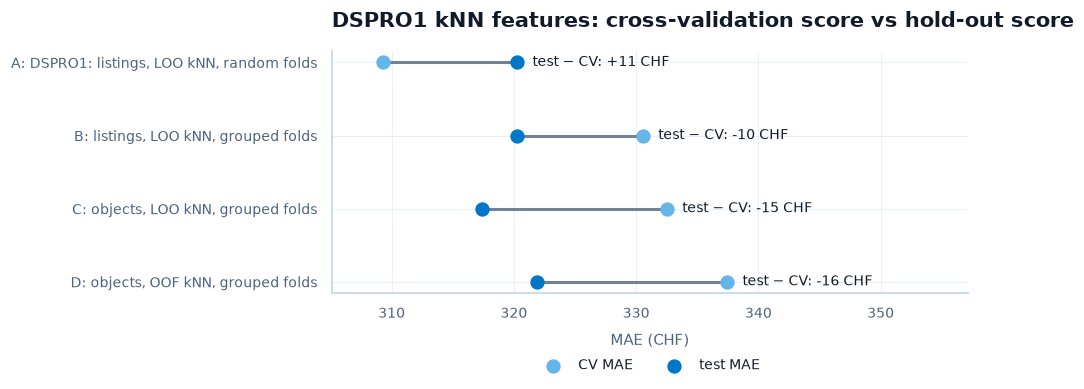

In [23]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ypos = np.arange(len(leak_table))[::-1]
maes = leak_table[["cv_mae", "test_mae"]].to_numpy()
for y, (cv, te) in zip(ypos, maes, strict=True):
    ax.plot([cv, te], [y, y], color=COLORS["gray"], lw=2, zorder=1)
    ax.annotate(f"test − CV: {te - cv:+.0f} CHF", (max(cv, te), y), xytext=(10, 0),
                textcoords="offset points", va="center", fontsize=9)
ax.scatter(maes[:, 0], ypos, s=70, color=COLORS["secondary"], zorder=2, label="CV MAE")
ax.scatter(maes[:, 1], ypos, s=70, color=COLORS["primary"], zorder=2, label="test MAE")
ax.set_yticks(ypos, [f"{k}: {d}" for k, d in leak_table["protocol"].items()])
span = max(maes.max() - maes.min(), 20.0)
ax.set_xlim(maes.min() - 0.15 * span, maes.max() + 0.7 * span)
ax.xaxis.set_major_formatter(chf_formatter())
ax.set(xlabel="MAE (CHF)", title="DSPRO1 kNN features: cross-validation score vs hold-out score")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncols=2, frameon=False)
fig.tight_layout()
save_fig(fig, "dspro1_knn_leakage")
plt.show()

**Interpretation.** A clearly positive optimism for A means the DSPRO1 validation overstated the
model: random folds put relistings on both sides, and the leave-one-out neighbourhood hands a
listing the rent of its own relisting. B isolates the feature leak (grouped split, LOO features),
C shows what is left once the duplicate audit merged the relistings. If the **test** MAEs of LOO
and OOF features are close, the kNN features are not useless, only validated wrongly, and every
tuning decision on their CV score was biased. Even clean kNN features are an in-sample aggregate
without uncertainty: a municipality with two neighbours gets a feature as confident as Zurich.
DSPRO2 therefore replaces them with models that shrink sparse areas explicitly (sections 13–14).
The LOO run is tracked but excluded from the CV-based ablation selection (section 24).

### 12.2 Learning curve: would more data help?

The proposal aims at about 30,000 objects, but only if that volume is needed. LightGBM on
`F_GEO_LGBM` is refitted on nested random subsets (20–100 %) of each fold's training objects and
scored on the full validation fold.

power-law slope -0.082; last step +1.0% lower MAE; doubling the objects projects 307 CHF (-6.1%)


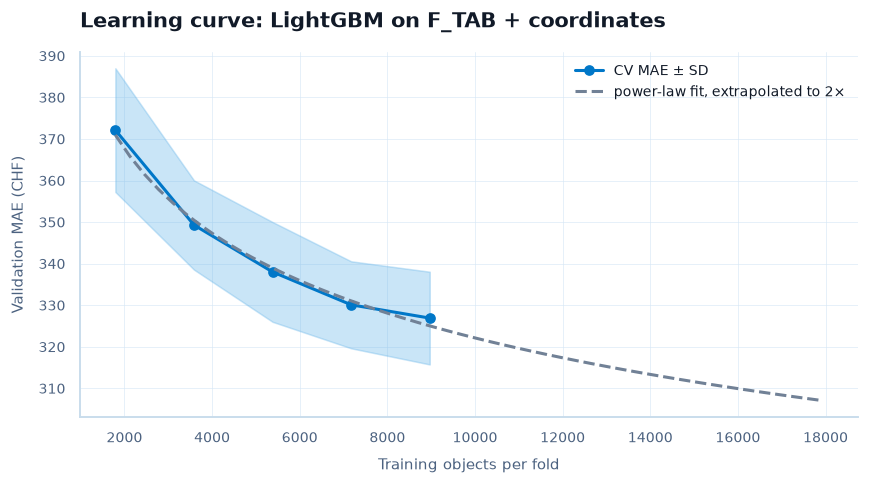

In [24]:
def lgbm_fit_predict(train_pos: np.ndarray, val_pos: np.ndarray) -> np.ndarray:
    X = train_df[F_GEO_LGBM]
    model = models.make_lgbm().fit(X.iloc[train_pos], y_train_log[train_pos])
    return np.exp(model.predict(X.iloc[val_pos]))


lc = evaluation.learning_curve(lgbm_fit_predict, cv_folds, y_train)
slope, intercept = np.polyfit(np.log(lc["n_train_mean"]), np.log(lc["mae_mean"]), 1)
n_max = lc["n_train_mean"].iloc[-1]
gain_last = 1 - lc["mae_mean"].iloc[-1] / lc["mae_mean"].iloc[-2]
mae_double = float(np.exp(intercept) * (2 * n_max) ** slope)
print(f"power-law slope {slope:.3f}; last step {gain_last:+.1%} lower MAE; doubling the "
      f"objects projects {mae_double:,.0f} CHF ({mae_double / lc['mae_mean'].iloc[-1] - 1:+.1%})")
track("learning_curve", "diagnostics", {"lc_slope": slope, "lc_gain_last_step": gain_last,
                                        "lc_mae_projected_2x": mae_double},
      params={"model": "lgbm F_GEO_LGBM"}, tables={"learning_curve": lc})

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(lc["n_train_mean"], lc["mae_mean"] - lc["mae_std"],
                lc["mae_mean"] + lc["mae_std"], color=COLORS["secondary"], alpha=0.35)
ax.plot(lc["n_train_mean"], lc["mae_mean"], "o-", color=COLORS["primary"], label="CV MAE ± SD")
n_grid = np.linspace(lc["n_train_mean"].iloc[0], 2 * n_max, 50)
ax.plot(n_grid, np.exp(intercept) * n_grid**slope, ls="--", color=COLORS["gray"],
        label="power-law fit, extrapolated to 2×")
ax.yaxis.set_major_formatter(chf_formatter())
ax.set(xlabel="Training objects per fold", ylabel="Validation MAE (CHF)",
       title="Learning curve: LightGBM on F_TAB + coordinates")
ax.legend()
fig.tight_layout()
save_fig(fig, "learning_curve")
plt.show()

**Interpretation.** A curve that still falls at 100 % (clearly negative slope, a last-step gain of
several percent) means the model is **data-limited** and collecting more listings pays off. A flat
curve means the remaining error must come from better features (text, RQ1) or better location
handling (RQ2). The extrapolation assumes new listings from the same regions; in practice they
would fill sparse municipalities first, where the gain is likely larger.

## 13. LightGBM with Coordinates and Out-of-Fold Target Encoding (RQ2 Comparator)

The strongest *conventional* way to put location into a tree model:

- **coordinates** (LV95) and the same coordinates **rotated by 45°**;
- **target encoding** of canton, district and municipality (scikit-learn `TargetEncoder`,
  shrunk towards the global mean); training rows get **cross-fitted** encodings, so a row never
  sees its own rent;
- a **monotone constraint** on `area` and `area_per_room` (which moves with the area): at equal
  location, building and rooms, a larger flat never gets a lower estimate. Constraining `area`
  alone left 94 of 1'625 test flats with a lower estimate after enlarging them (changelog of the
  evaluation plan).

Optuna tunes the complete pipeline (`make_te_lgbm`) on the grouped folds, so the encoder is refitted
inside every fold. The fitted encoder (`encoder`) then produces one training matrix on which both
the point model and the quantile models of RQ3 are trained; the app bundle stores that encoder.

60 trials (10 pruned); best CV MAE 321.2 CHF; params {'learning_rate': 0.010648518282201291, 'n_estimators': 1700, 'num_leaves': 83, 'min_child_samples': 5, 'subsample': 0.8634926330477819, 'colsample_bytree': 0.4087491259927068, 'reg_lambda': 0.004692450985414825, 'reg_alpha': 0.005951509622335066}


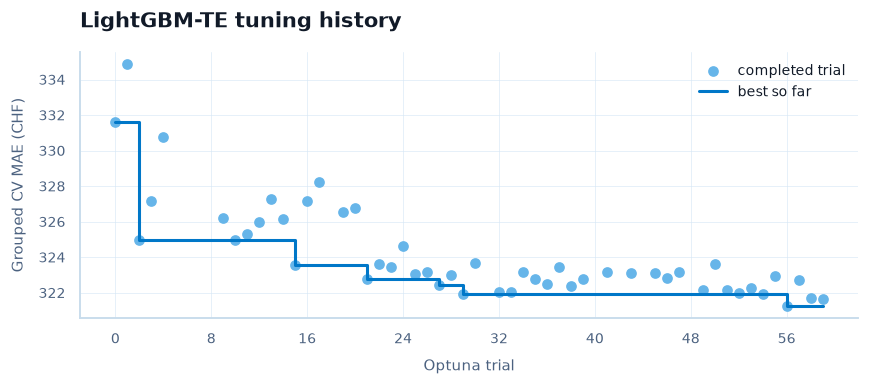

In [25]:
MONOTONE_INCREASING = ("area", "area_per_room")


def te_lgbm(params: dict | None = None) -> object:
    return models.make_te_lgbm(F_GEO_LGBM, GROUP_COLS, params, MONOTONE_INCREASING)


lgb_params, lgb_study = models.tune_lgbm_optuna(
    train_df[TE_INPUT], y_train_log, cv_folds, n_trials=BUDGET["optuna_trials"],
    model_factory=te_lgbm, seed=RANDOM_STATE)
trials = lgb_study.trials_dataframe(attrs=("number", "value", "state"))
done = trials[trials["state"].eq("COMPLETE")]
print(f"{len(trials)} trials ({len(trials) - len(done)} pruned); best CV MAE "
      f"{lgb_study.best_value:,.1f} CHF; params {lgb_params}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(done["number"], done["value"], color=COLORS["secondary"], label="completed trial")
ax.plot(done["number"], done["value"].cummin(), drawstyle="steps-post", color=COLORS["primary"],
        label="best so far")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_formatter(chf_formatter())
ax.set(xlabel="Optuna trial", ylabel="Grouped CV MAE (CHF)", title="LightGBM-TE tuning history")
ax.legend()
fig.tight_layout()
save_fig(fig, "lgbm_te_tuning")
plt.show()

In [26]:
cv_oof["lgbm_te"] = np.exp(models.fit_predict_cv(lambda: te_lgbm(lgb_params), train_df[TE_INPUT],
                                                 y_train_log, cv_folds))
encoder = te_lgbm(lgb_params)[:-1]  # the "encode" step: raw rows -> model matrix
X_train_lgb = encoder.fit_transform(train_df[TE_INPUT], y_train_log)  # cross-fitted encodings
X_calib_lgb, X_test_lgb = encoder.transform(calib_df), encoder.transform(test_df)
F_LGB = list(X_train_lgb.columns)
lgb_point = models.make_lgbm(lgb_params, models.monotone_vector(F_LGB, MONOTONE_INCREASING))
lgb_point.fit(X_train_lgb, y_train_log)
pred_calib["lgbm_te"] = np.exp(lgb_point.predict(X_calib_lgb))
pred_test["lgbm_te"] = np.exp(lgb_point.predict(X_test_lgb))
same = np.allclose(np.log(pred_test["lgbm_te"]),
                   te_lgbm(lgb_params).fit(train_df[TE_INPUT], y_train_log).predict(test_df))
track("lgbm_te", "tabular+geo",
      run_metrics("lgbm_te") | {"optuna_best_cv_mae": lgb_study.best_value},
      tags={"model": "lgbm_te"},
      params={"lgbm": lgb_params, "features": "F_TAB+COORDS+ROT_COORDS+TE",
              "n_features": len(F_LGB), "monotone": ",".join(MONOTONE_INCREASING),
              "optuna_trials": BUDGET["optuna_trials"], "cv_folds": len(cv_folds)})

# ablation stage "tabular": same learner and settings without any location signal
cv_oof["lgbm_tab"] = np.exp(models.fit_predict_cv(
    lambda: models.make_lgbm(lgb_params, models.monotone_vector(F_TAB, MONOTONE_INCREASING)),
    train_df[F_TAB], y_train_log, cv_folds))
lgb_tab = models.make_lgbm(lgb_params, models.monotone_vector(F_TAB, MONOTONE_INCREASING))
lgb_tab.fit(train_df[F_TAB], y_train_log)
pred_calib["lgbm_tab"] = np.exp(lgb_tab.predict(calib_df[F_TAB]))
pred_test["lgbm_tab"] = np.exp(lgb_tab.predict(test_df[F_TAB]))
track("lgbm_tab", "tabular", run_metrics("lgbm_tab"), tags={"model": "lgbm_tab"},
      params={"lgbm": lgb_params, "features": "F_TAB", "monotone": ",".join(MONOTONE_INCREASING)})
print(f"CV MAE: LightGBM-TE {mae(y_train, cv_oof['lgbm_te']):,.1f}, F_TAB only "
      f"{mae(y_train, cv_oof['lgbm_tab']):,.1f}, DSPRO1 with clean kNN "
      f"{mae(y_train, cv_oof['dspro1_knn_oof']):,.1f} CHF; matrices reproduce the pipeline: {same}")

CV MAE: LightGBM-TE 321.2, F_TAB only 368.8, DSPRO1 with clean kNN 337.5 CHF; matrices reproduce the pipeline: True


**Interpretation.** The tuned CV MAE is slightly optimistic (Optuna chose on the same folds);
it only compares CV scores within this phase. The hold-out MAE is logged but read only in
section 15. If LightGBM-TE reaches the CV MAE of the DSPRO1 recipe with clean kNN features, the kNN
features can go: the encoding carries the same location signal with explicit shrinkage. The gap to
`lgbm_tab` (same learner on `F_TAB` only, the "tabular" ablation row) is the value of location.

## 14. GPBoost: Boosting with Nested Random Effects and a Spatial Gaussian Process (RQ2 Candidate)

GPBoost (Sigrist, JMLR 2022, developed at HSLU) models

$$\log(\text{rent}) = F(\mathbf{x}) + b_{\text{canton}} + b_{\text{district}} + b_{\text{municipality}} + g(\mathbf{s}) + \varepsilon,$$

with boosted trees $F$, **nested random intercepts** and a **Gaussian process** $g$ on the LV95
coordinates (Matérn 1.5, Vecchia approximation with 20 neighbours). The shrinkage strength follows
from **estimated variance components** instead of a fixed pseudo-count, and every prediction has a
predictive variance. The trees see only `F_TAB`: location enters **only** through the random
effects and the GP, so any gain over section 13 is attributable to the spatial model.

**Why the fit is two-stage.** gpboost's default re-estimates the covariance parameters in every
round. On this data that took about 12 s per round and converged to a **degenerate solution**: the
error variance collapsed to about $5 \cdot 10^{-7}$, because many listings share GWR building
coordinates and the GP interpolated their rents exactly (training MAE 0, 80 % intervals covering
62 %). The fit therefore (1) estimates the covariance parameters once in a linear mixed model with
data-driven start values and (2) boosts with them fixed, at learning rate 0.01 without line search.
The number of rounds comes from early stopping on one grouped fold inside the training set.

best round 90 of 400 (529s)


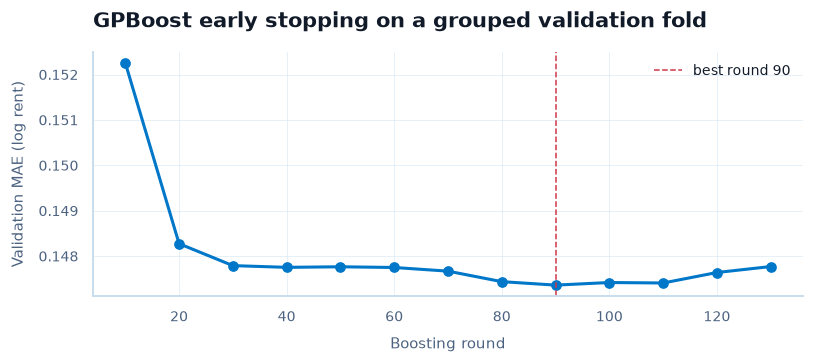

In [27]:
GPB_KW = {"learning_rate": 0.01, "eval_every": 10, "num_threads": 8, "seed": RANDOM_STATE}
fit_part, val_part = train_df.iloc[cv_folds[0][0]], train_df.iloc[cv_folds[0][1]]
gpb_es = models.GPBoostRegressor(num_boost_round=BUDGET["gpb_rounds"], **GPB_KW).fit(
    fit_part[F_TAB], fit_part["log_price"], fit_part[GROUP_COLS], fit_part[COORDS],
    eval_set=(val_part[F_TAB], val_part["log_price"], val_part[GROUP_COLS], val_part[COORDS]),
    early_stopping_rounds=40)
GPB_ROUNDS = int(gpb_es.best_iteration_)
print(f"best round {GPB_ROUNDS} of {BUDGET['gpb_rounds']} ({gpb_es.fit_time_s_:.0f}s)"
      + (" - at the budget limit" if gpb_es.best_iteration_ >= BUDGET["gpb_rounds"] else ""))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(gpb_es.eval_iterations_, gpb_es.evals_result_["valid"]["l1"], "o-",
        color=COLORS["primary"])
ax.axvline(GPB_ROUNDS, color=COLORS["reference"], ls="--", lw=1, label=f"best round {GPB_ROUNDS}")
ax.set(xlabel="Boosting round", ylabel="Validation MAE (log rent)",
       title="GPBoost early stopping on a grouped validation fold")
ax.legend()
fig.tight_layout()
save_fig(fig, "gpboost_early_stopping")
plt.show()

GPBoost: CV MAE 330.1 CHF (LightGBM-TE 321.2); raw 80 % Gaussian coverage on calibration 0.872


component,variance,share
canton,0.03558,34.7%
district,0.0108,10.5%
municipality,0.001964,1.9%
gp_variance,0.01317,12.8%
gp_range,1.177,–
residual,0.04106,40.0%
gp_practical_range,3.223,–


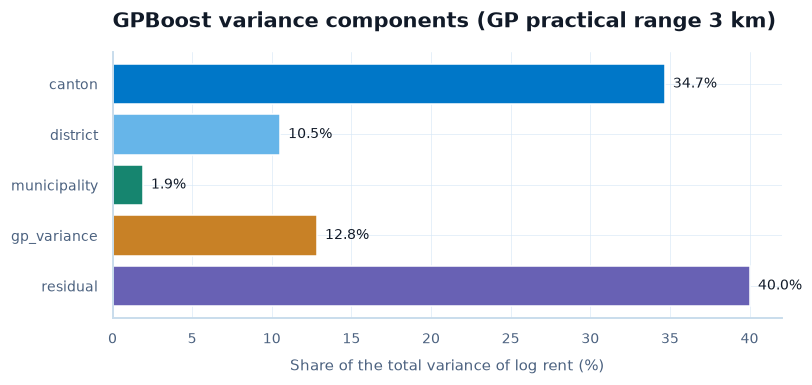

In [28]:
def gpb_part(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    return frame[F_TAB], frame[GROUP_COLS], frame[COORDS]


gpb_model = models.GPBoostRegressor(num_boost_round=GPB_ROUNDS, **GPB_KW).fit(
    train_df[F_TAB], train_df["log_price"], train_df[GROUP_COLS], train_df[COORDS])
mu_calib, gpb_var_calib = gpb_model.predict(*gpb_part(calib_df), return_var=True)
mu_test, gpb_var_test = gpb_model.predict(*gpb_part(test_df), return_var=True)
pred_calib["gpboost"], pred_test["gpboost"] = np.exp(mu_calib), np.exp(mu_test)  # median scale
cover80 = float(np.mean(np.abs(np.log(y_calib) - mu_calib)
                        <= stats.norm.ppf(0.9) * np.sqrt(gpb_var_calib)))


def gpb_fit_predict(train_pos: np.ndarray, val_pos: np.ndarray) -> np.ndarray:
    # fold fit with the train-level covariance parameters (stage 1 is not repeated)
    a, b = train_df.iloc[train_pos], train_df.iloc[val_pos]
    model = models.GPBoostRegressor(num_boost_round=GPB_ROUNDS, **GPB_KW).fit(
        a[F_TAB], a["log_price"], a[GROUP_COLS], a[COORDS], cov_pars=gpb_model.cov_)
    return model.predict(*gpb_part(b))


oof_gpb = np.full(len(train_df), np.nan)
for tr, va in cv_folds:
    oof_gpb[va] = gpb_fit_predict(tr, va)
cv_oof["gpboost"] = np.exp(oof_gpb)
var_comp = gpb_model.variance_components()
track("gpboost", "tabular+geo",
      run_metrics("gpboost") | {"calib_coverage_80_raw": cover80,
                                "fit_time_s": gpb_model.fit_time_s_}
      | {f"var_{c}": v for c, v in var_comp.set_index("component")["variance"].items()},
      tags={"model": "gpboost"},
      params=GPB_KW | {"num_boost_round": GPB_ROUNDS, "fit": "two-stage",
                       "features": "F_TAB (+RE +GP)"},
      tables={"variance_components": var_comp})
write_table(var_comp, "gpboost_variance_components", {"variance": ".4g", "share": ".3f"})
print(f"GPBoost: CV MAE {mae(y_train, cv_oof['gpboost']):,.1f} CHF (LightGBM-TE "
      f"{mae(y_train, cv_oof['lgbm_te']):,.1f}); raw 80 % Gaussian coverage on calibration "
      f"{cover80:.3f}")
display(var_comp.style.format({"variance": "{:.4g}", "share": "{:.1%}"}, na_rep="–")
        .hide(axis="index"))

shares = var_comp.dropna(subset=["share"]).set_index("component")["share"]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(shares.index, shares.to_numpy() * 100, color=PALETTE[: len(shares)])
for y, s in enumerate(shares.to_numpy()):
    ax.text(s * 100 + 0.5, y, f"{s:.1%}", va="center", fontsize=9)
practical = var_comp.set_index("component")["variance"].get("gp_practical_range", np.nan)
ax.set(xlabel="Share of the total variance of log rent (%)",
       title=f"GPBoost variance components (GP practical range {practical:.0f} km)")
ax.invert_yaxis()
fig.tight_layout()
save_fig(fig, "gpboost_variance_components")
plt.show()

The CV reuses the covariance parameters of the full training set and refits only the trees per
fold, a documented approximation that can make the GPBoost CV slightly optimistic but does not
touch the hold-out test. A raw 80 % coverage close to or above 0.80 shows that the error variance
is no longer collapsed.

**Variance components.** A large **canton** share means a regional premium (tax level, labour
market); a large **GP** share with a range of tens of kilometres means rents vary smoothly across
municipality borders (commuting belts). Small district and municipality shares mean their
differences are mostly explained by GP and canton. The **residual** share is what no location
model can remove; it is the target of the text features in RQ1.

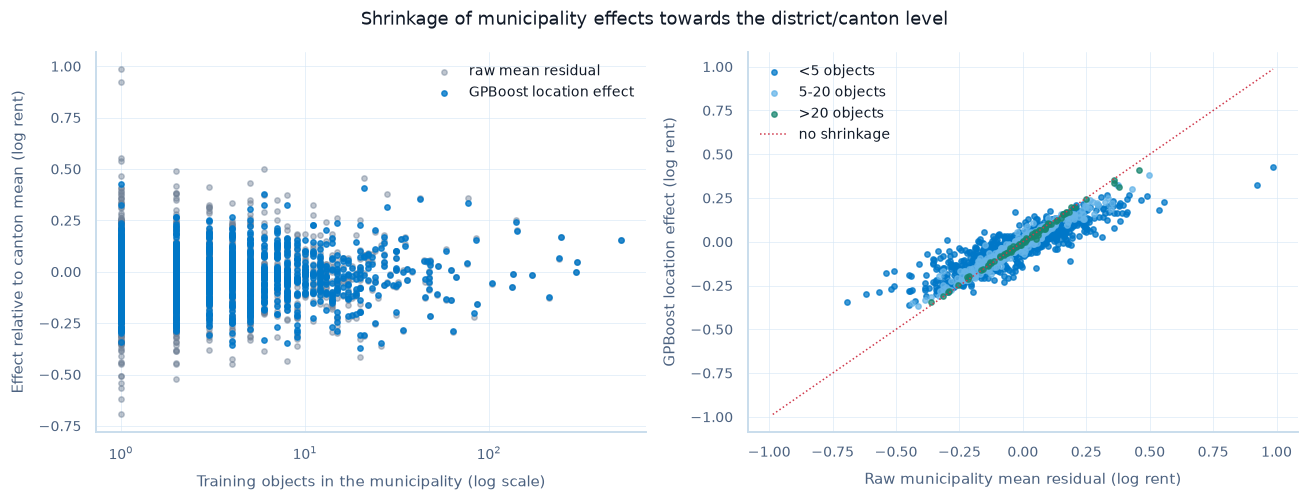

slope of location effect on raw residual: <5 0.55, 5-20 0.82, >20 0.95


In [29]:
fixed_train = gpb_model.predict_fixed_effects(train_df[F_TAB])
shrink = pd.DataFrame({
    "canton": train_df["re_canton"].to_numpy(), "muni": train_df["re_municipality"].to_numpy(),
    "model": gpb_model.predict(*gpb_part(train_df)) - fixed_train,
    "raw": y_train_log - fixed_train,  # unshrunk: plain mean residual of the tree part
})
shrink[["model", "raw"]] -= shrink.groupby("canton")[["model", "raw"]].transform("mean")
muni_eff = shrink.groupby("muni").agg(n=("model", "size"), model=("model", "mean"),
                                      raw=("raw", "mean"))
muni_eff["bucket"] = geo.count_bucket(muni_eff["n"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(muni_eff["n"], muni_eff["raw"], s=12, color=COLORS["gray"], alpha=0.45,
                label="raw mean residual")
axes[0].scatter(muni_eff["n"], muni_eff["model"], s=12, color=COLORS["primary"], alpha=0.8,
                label="GPBoost location effect")
axes[0].set(xscale="log", xlabel="Training objects in the municipality (log scale)",
            ylabel="Effect relative to canton mean (log rent)")
axes[0].legend(fontsize=9)
for color, b in zip(PALETTE, BUCKETS, strict=False):
    part = muni_eff[muni_eff["bucket"].eq(b)]
    axes[1].scatter(part["raw"], part["model"], s=12, color=color, alpha=0.75,
                    label=f"{b} objects")
lim = np.nanmax(np.abs(muni_eff[["raw", "model"]].to_numpy()))
axes[1].plot([-lim, lim], [-lim, lim], color=COLORS["reference"], lw=1, ls=":",
             label="no shrinkage")
axes[1].set(xlabel="Raw municipality mean residual (log rent)",
            ylabel="GPBoost location effect (log rent)")
axes[1].legend(fontsize=9)
fig.suptitle("Shrinkage of municipality effects towards the district/canton level")
fig.tight_layout()
save_fig(fig, "gpboost_shrinkage")
plt.show()
print("slope of location effect on raw residual: " + ", ".join(
    f"{b} {np.polyfit(p['raw'], p['model'], 1)[0]:.2f}"
    for b, p in muni_eff.groupby("bucket", observed=True) if len(p) > 2))

**Interpretation.** Each point is a municipality; without shrinkage it would lie on the diagonal.
A slope well below 1 in the `<5` bucket and closer to 1 in `>20` is the shrinkage RQ2 is about: a
municipality with one or two objects borrows the level of its district, canton and, through the
GP, its neighbours. The target encoding also shrinks, but with a fixed rule and without a spatial
neighbourhood across administrative borders.

## 15. RQ2 Decision: GPBoost vs LightGBM-TE

Pre-registered evidence on the frozen test set (evaluation plan, section 4):

- **H2a:** the paired bootstrap 95 % CI of `MAE(lgbm_te) − MAE(gpboost)` lies above 0 (overall),
  Wilcoxon signed-rank as secondary check;
- **H2b:** the same in the `<5` listings-per-municipality bucket;
- **H2c:** GPBoost has a lower Moran's I of the test log-residuals (k = 8, permutation test of each
  I against 0; the difference is reported descriptively).

**Decision rule.** The RQ2 winner, which carries RQ1 and RQ3, is **GPBoost if H2a holds**,
otherwise LightGBM-TE (the simpler comparator, which already serves the monotone what-if). H2b and
H2c answer the sparse-area and autocorrelation parts but do not change the winner. Because the rule
reads the test set, everything built on `RQ2_WINNER` is conditional on it, and the S0 test MAE in
RQ1 is slightly optimistic when the two models are close (winner's curse); selection within RQ1
and RQ3 uses only CV and calibration data. Spatial CV is a robustness check, not part of the rule.

In [30]:
rq2_segments = {"all": np.ones(len(test_df), dtype=bool)} | {b: bucket_test == b for b in BUCKETS}
rq2_by_segment = {
    seg: evaluation.paired_bootstrap_mae(y_test[m], pred_test["lgbm_te"][m],
                                         pred_test["gpboost"][m], n_boot=BUDGET["n_boot"],
                                         seed=RANDOM_STATE)
    for seg, m in rq2_segments.items()}
rq2_table = (evaluation.comparison_table(rq2_by_segment).drop(columns=["p_holm", "reject"])
             .rename_axis("segment").reset_index())
rq2_table.insert(8, "n", [int(m.sum()) for m in rq2_segments.values()])
rq2_table = rq2_table.astype({c: float for c in rq2_table.columns[1:]})
p_fmt = {"mae_a": ".1f", "mae_b": ".1f", "diff": ".3g", "ci_low": ".1f", "ci_high": ".1f",
         "p_bootstrap": ".3g", "p_wilcoxon": ".3g", "n": ".0f", "rel_diff_pct": ".2f"}
write_table(rq2_table, "rq2_comparison", p_fmt, caption="RQ2: paired bootstrap of "
            "MAE(LightGBM-TE) - MAE(GPBoost) on the test set")
print(f"paired bootstrap ({BUDGET['n_boot']} resamples); diff > 0: GPBoost better")
display(rq2_table.round(3))

paired bootstrap (2000 resamples); diff > 0: GPBoost better


,segment,mae_a,mae_b,diff,ci_low,ci_high,p_bootstrap,p_wilcoxon,n,rel_diff_pct
0,all,308.272,327.275,-19.004,-26.055,-12.393,0.000,0.000,3737.0,-6.165
1,<5,291.534,302.425,-10.890,-24.343,2.499,0.115,0.075,754.0,-3.736
2,5-20,291.446,314.143,-22.697,-38.157,-10.268,0.003,0.000,1179.0,-7.788
3,>20,326.263,346.244,-19.981,-29.590,-11.241,0.000,0.000,1804.0,-6.124


segment,all,<5,5-20,>20
model,,,,
naive,429.2,439.2,425.6,427.3
dspro1_knn,320.3,298.5,303.7,340.2
lgbm_te,308.3,291.5,291.4,326.3
gpboost,327.3,302.4,314.1,346.2


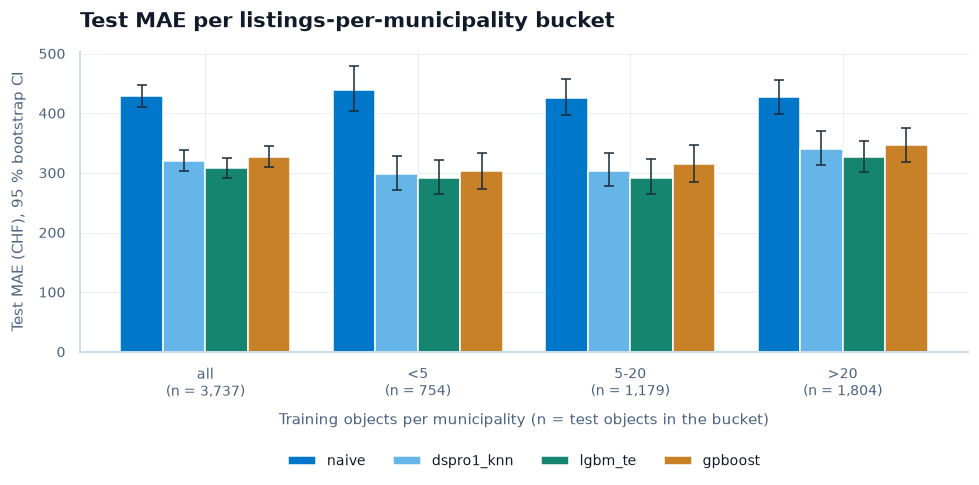

mean bias per bucket (CHF, prediction − truth):


muni_bucket,<5,5-20,>20
naive,128.0,30.0,-21.0
dspro1_knn,-28.0,-57.0,-53.0
lgbm_te,-16.0,-50.0,-55.0
gpboost,-24.0,-50.0,-64.0


In [31]:
RQ2_MODELS = ["naive", "dspro1_knn", "lgbm_te", "gpboost"]
bucket_mae = pd.DataFrame(
    [(name, seg, int(m.sum()), *evaluation.bootstrap_ci(y_test[m], pred_test[name][m], "MAE",
                                                        n_boot=BUDGET["n_boot"]))
     for name in RQ2_MODELS for seg, m in rq2_segments.items()],
    columns=["model", "segment", "n", "MAE", "ci_low", "ci_high"])
display(bucket_mae.pivot(index="model", columns="segment", values="MAE")
        .loc[RQ2_MODELS, list(rq2_segments)].round(1))
fig, ax = plt.subplots(figsize=(9, 4.8))
width = 0.8 / len(RQ2_MODELS)
for i, (color, name) in enumerate(zip(PALETTE, RQ2_MODELS, strict=False)):
    part = bucket_mae[bucket_mae["model"].eq(name)].set_index("segment").loc[list(rq2_segments)]
    ax.bar(np.arange(len(part)) + (i - (len(RQ2_MODELS) - 1) / 2) * width, part["MAE"], width,
           color=color, label=name, capsize=3, error_kw={"lw": 1, "ecolor": COLORS["neutral"]},
           yerr=[part["MAE"] - part["ci_low"], part["ci_high"] - part["MAE"]])
ax.set_xticks(np.arange(len(rq2_segments)),
              [f"{s}\n(n = {int(m.sum()):,})" for s, m in rq2_segments.items()])
ax.yaxis.set_major_formatter(chf_formatter())
ax.set(xlabel="Training objects per municipality (n = test objects in the bucket)",
       ylabel="Test MAE (CHF), 95 % bootstrap CI",
       title="Test MAE per listings-per-municipality bucket")
ax.legend(ncols=len(RQ2_MODELS), fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.3),
          frameon=False)
fig.tight_layout()
save_fig(fig, "rq2_mae_by_bucket")
plt.show()
print("mean bias per bucket (CHF, prediction − truth):")
display(pd.DataFrame({name: evaluation.segment_metrics(y_test, pred_test[name],
                                                       test_df["muni_bucket"])["bias"]
                      for name in RQ2_MODELS}).T.round(0))

In [32]:
coords_test = test_df[COORDS].to_numpy(dtype=float)
moran = {name: evaluation.morans_i(np.log(y_test) - np.log(pred_test[name]), coords_test, k=8,
                                   permutations=BUDGET["permutations"], seed=RANDOM_STATE)
         for name in RQ2_MODELS}
display(pd.DataFrame({n: {"moran_I": r.I, "z": r.z, "p_value": r.p_value}
                      for n, r in moran.items()}).T.round(4))
oof_sp_gpb = np.full(len(train_df), np.nan)
for tr, va in spatial_folds:
    oof_sp_gpb[va] = gpb_fit_predict(tr, va)
spatial_cv = {"lgbm_te": mae(y_train, np.exp(models.fit_predict_cv(
                  lambda: te_lgbm(lgb_params), train_df[TE_INPUT], y_train_log, spatial_folds))),
              "gpboost": mae(y_train, np.exp(oof_sp_gpb))}
print(f"E[I] = {moran['gpboost'].expected:.4f}; spatial CV MAE (whole municipalities held out): "
      + ", ".join(f"{k} {v:,.1f} CHF" for k, v in spatial_cv.items()))

,moran_I,z,p_value
naive,0.0432,5.6825,0.001
dspro1_knn,0.0436,5.8960,0.001
lgbm_te,0.0325,4.4844,0.001
gpboost,0.0424,5.7437,0.001


E[I] = -0.0003; spatial CV MAE (whole municipalities held out): lgbm_te 399.1 CHF, gpboost 388.6 CHF


In [33]:
overall, sparse_res = rq2_by_segment["all"], rq2_by_segment["<5"]
RQ2_WINNER = "gpboost" if overall.ci_low > 0 else "lgbm_te"  # pre-registered rule
decision = pd.DataFrame([
    ("H2a", "overall: 95 % CI of MAE(lgbm_te) − MAE(gpboost) > 0",
     f"{overall.diff:+.1f} CHF [{overall.ci_low:+.1f}, {overall.ci_high:+.1f}], "
     f"Wilcoxon p = {overall.p_wilcoxon:.3g}", overall.ci_low > 0),
    ("H2b", "<5 bucket: 95 % CI > 0",
     f"{sparse_res.diff:+.1f} CHF [{sparse_res.ci_low:+.1f}, {sparse_res.ci_high:+.1f}], "
     f"Wilcoxon p = {sparse_res.p_wilcoxon:.3g}", sparse_res.ci_low > 0),
    ("H2c", "Moran's I(gpboost) < Moran's I(lgbm_te) (descriptive)",
     f"{moran['gpboost'].I:.4f} (p = {moran['gpboost'].p_value:.3g}) vs "
     f"{moran['lgbm_te'].I:.4f} (p = {moran['lgbm_te'].p_value:.3g}); p: I vs 0",
     moran["gpboost"].I < moran["lgbm_te"].I),
], columns=["hypothesis", "criterion", "estimate", "supported"])
display(decision.style.hide(axis="index"))
print(f"RQ2_WINNER = {RQ2_WINNER!r}; CV MAE: untuned LightGBM F_TAB + coordinates "
      f"{abs_err_geo.mean():,.1f} | GPBoost {mae(y_train, cv_oof['gpboost']):,.1f} | tuned "
      f"LightGBM-TE {mae(y_train, cv_oof['lgbm_te']):,.1f} CHF")

rq2_models = pd.DataFrame({n: {"cv_mae": mae(y_train, cv_oof[n]), **test_metrics(pred_test[n]),
                               "moran_I": moran[n].I} for n in RQ2_MODELS}).T
rq2_models["spatial_cv_mae"] = pd.Series(spatial_cv)
write_table(rq2_models.rename_axis("model").reset_index(), "rq2_models",
            {c: ".1f" for c in rq2_models} | {"test_r2": ".3f", "moran_I": ".4f"})
display(rq2_models.round(3))
track("rq2_decision", "rq2",
      {f"{stat}_{'all' if seg == 'all' else BUCKET_KEYS[seg]}": getattr(res, attr)
       for seg, res in rq2_by_segment.items()
       for stat, attr in [("diff", "diff"), ("ci_low", "ci_low"), ("ci_high", "ci_high"),
                          ("p_boot", "p_bootstrap"), ("p_wilcoxon", "p_wilcoxon")]}
      | {f"moran_{k}": r.I for k, r in moran.items()}
      | {f"spatial_cv_mae_{k}": v for k, v in spatial_cv.items()},
      params={"winner": RQ2_WINNER, "rule": "gpboost iff overall CI(diff) > 0",
              "n_boot": BUDGET["n_boot"], "permutations": BUDGET["permutations"]},
      tables={"rq2_comparison": rq2_table, "rq2_models": rq2_models})

hypothesis,criterion,estimate,supported
H2a,overall: 95 % CI of MAE(lgbm_te) − MAE(gpboost) > 0,"-19.0 CHF [-26.1, -12.4], Wilcoxon p = 6.59e-10",False
H2b,<5 bucket: 95 % CI > 0,"-10.9 CHF [-24.3, +2.5], Wilcoxon p = 0.0753",False
H2c,Moran's I(gpboost) < Moran's I(lgbm_te) (descriptive),0.0424 (p = 0.001) vs 0.0325 (p = 0.001); p: I vs 0,False


RQ2_WINNER = 'lgbm_te'; CV MAE: untuned LightGBM F_TAB + coordinates 332.5 | GPBoost 330.1 | tuned LightGBM-TE 321.2 CHF


,cv_mae,test_mae,test_rmse,test_medae,test_mape,test_r2,test_mae_lt5,test_mae_5_20,test_mae_gt20,moran_I,spatial_cv_mae
naive,441.012,429.175,728.806,268.182,20.701,0.703,439.151,425.634,427.320,0.043,NaN
dspro1_knn,332.125,320.275,638.987,180.889,14.462,0.772,298.524,303.666,340.221,0.044,NaN
lgbm_te,321.243,308.272,607.626,172.040,13.986,0.794,291.534,291.446,326.263,0.032,399.051
gpboost,330.121,327.275,660.222,186.084,14.685,0.756,302.425,314.143,346.244,0.042,388.601


**Interpretation.**

- **H2a** is the primary result. A CI above 0 makes GPBoost the point model; a CI containing 0 is
  "no detectable difference at this test-set size" (compare the MDE of section 11); a CI below 0
  means the conventional encoding is better on this data.
- **H2b** has only a few hundred test objects, so its CI is wide. A GPBoost advantage there with
  an overall tie would still make GPBoost the safer choice where listings are rare.
- **H2c.** A residual Moran's I near its expectation means the model absorbed the spatial
  structure. If the naive baseline shows clear autocorrelation and both learned models are near 0,
  the difference between them is accuracy, not missed spatial structure.
- **Spatial CV** simulates municipalities without training objects. If the ranking flips there,
  the random-split result should not be generalised to new regions.
- **Tuning budget.** LightGBM-TE was tuned with Optuna, GPBoost only had its rounds chosen. If
  GPBoost is about as good as the *untuned* LightGBM of section 11, part of the gap is tuning.

Either way, the kNN rent features are no longer needed.

## 16. Deep-Learning Component: Fused Network with Entity Embeddings

An optional, time-boxed extension. `FusedRentRegressor` combines **entity embeddings** for canton,
district and municipality (weight decay pulls rare units towards zero, a neural analogue of random
intercepts), a **numeric MLP** on `F_GEO_LGBM` and, with descriptions, a **text branch** on 32
PCA components of multilingual sentence embeddings. Early stopping uses the grouped fold
`cv_folds[0]` inside the training set. The network is not monotone in the area, so it cannot serve
the what-if view, and the comparison with the RQ2 winner is **exploratory** (not pre-registered).
The section is skipped if PyTorch is not installed.

In [34]:
EMB: dict[str, np.ndarray] | None = None  # 32-dim sentence embeddings per split, NaN = no text
SPLITS = {"train": train_df, "calib": calib_df, "test": test_df}
if HAS_TEXT and HAS_ST:
    texts = {s: f["description_anon"].astype("string").fillna("") for s, f in SPLITS.items()}
    has_desc = {s: (t.str.len() >= 50).to_numpy() for s, t in texts.items()}
    try:
        raw_emb = {s: text.embed_texts(t.tolist(), CACHE / "embeddings", DEVICE)
                   for s, t in texts.items()}
    except (OSError, RuntimeError, ValueError) as exc:  # e.g. model not downloadable offline
        print(f"sentence embeddings failed: {exc}")
    else:  # PCA on training rows with a description only
        _, reduced = text.reduce_embeddings(raw_emb["train"][has_desc["train"]],
                                            list(raw_emb.values()), n_components=32)
        EMB = {s: np.where(has_desc[s][:, None], r, np.nan) for s, r in zip(SPLITS, reduced,
                                                                           strict=True)}
print(f"text embeddings: {'on' if EMB else 'off'} (HAS_TEXT={HAS_TEXT}, "
      f"sentence-transformers={HAS_ST}); PyTorch: {HAS_TORCH}")

text embeddings: on (HAS_TEXT=True, sentence-transformers=True); PyTorch: True


best epoch 64 of 84; CV MAE 334.5 CHF; test MAE 322.2 vs lgbm_te 308.3 CHF; MAE(lgbm_te) − MAE(fused_nn) = -13.9 [-24.2, -3.7], p = 0.009


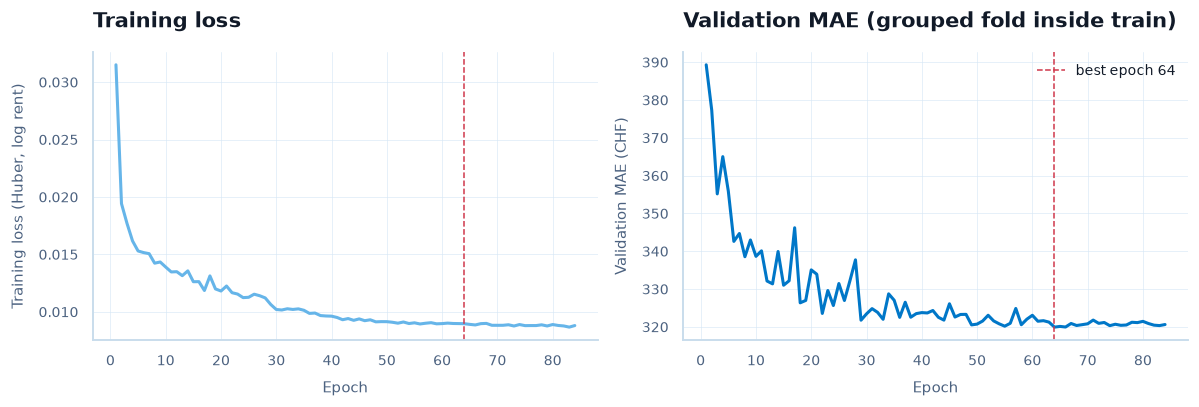

In [35]:
if HAS_TORCH:
    from rentml.nn import UNKNOWN_LABEL, FusedRentRegressor

    NN_LOG1P = ("area", "population", "land_area", "apartments", "land_area_per_apartment",
                "oev", "muni_density", "muni_population")

    def emb_of(split: str, pos: np.ndarray | None = None) -> np.ndarray | None:
        return None if EMB is None else EMB[split] if pos is None else EMB[split][pos]

    def fit_fused(train_pos: np.ndarray, val_pos: np.ndarray) -> FusedRentRegressor:
        a, b = train_df.iloc[train_pos], train_df.iloc[val_pos]
        eval_set = (b[F_GEO_LGBM], b[GROUP_COLS], b["log_price"])
        eval_set += () if EMB is None else (emb_of("train", val_pos),)
        net = FusedRentRegressor(epochs=BUDGET["nn_epochs"], log1p_cols=NN_LOG1P, device=DEVICE)
        return net.fit(a[F_GEO_LGBM], a[GROUP_COLS], a["log_price"],
                       X_text=emb_of("train", train_pos), eval_set=eval_set)

    def predict_fused(net: FusedRentRegressor, frame: pd.DataFrame,
                      emb: np.ndarray | None) -> np.ndarray:
        return np.exp(net.predict(frame[F_GEO_LGBM], frame[GROUP_COLS], emb))

    nn_model = fit_fused(*cv_folds[0])
    pred_calib["fused_nn"] = predict_fused(nn_model, calib_df, emb_of("calib"))
    pred_test["fused_nn"] = predict_fused(nn_model, test_df, emb_of("test"))
    cv_oof["fused_nn"] = np.full(len(train_df), np.nan)
    for tr, va in cv_folds:  # each outer fold gets its own inner grouped early-stopping split
        inner_tr, inner_va = data.grouped_cv_folds(train_df.iloc[tr], strata, len(cv_folds))[0]
        net = fit_fused(tr[inner_tr], tr[inner_va])
        cv_oof["fused_nn"][va] = predict_fused(net, train_df.iloc[va], emb_of("train", va))
    hist = nn_model.history_
    nn_vs_winner = evaluation.paired_bootstrap_mae(y_test, pred_test[RQ2_WINNER],
                                                   pred_test["fused_nn"], n_boot=BUDGET["n_boot"])
    track("fused_nn", "fused",
          run_metrics("fused_nn") | {"best_epoch": nn_model.best_epoch_,
                                     "val_mae": nn_model.best_val_mae_,
                                     "diff_vs_winner": nn_vs_winner.diff,
                                     "p_boot_vs_winner": nn_vs_winner.p_bootstrap},
          tags={"model": "fused_nn", "pre_registered": "false"},
          params={"epochs": BUDGET["nn_epochs"], "text_branch": EMB is not None,
                  "numeric": "F_GEO_LGBM", "categorical": "+".join(GROUP_COLS)},
          tables={"history": hist})
    res = nn_vs_winner
    print(f"best epoch {nn_model.best_epoch_} of {len(hist)}; CV MAE "
          f"{mae(y_train, cv_oof['fused_nn']):,.1f} CHF; test MAE {res.mae_b:,.1f} vs "
          f"{RQ2_WINNER} {res.mae_a:,.1f} CHF; MAE({RQ2_WINNER}) − MAE(fused_nn) = "
          f"{res.diff:+.1f} [{res.ci_low:+.1f}, {res.ci_high:+.1f}], p = {res.p_bootstrap:.3g}")

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
    axes[0].plot(hist["epoch"], hist["train_loss"], color=COLORS["secondary"])
    axes[0].set(ylabel="Training loss (Huber, log rent)", title="Training loss")
    axes[1].plot(hist["epoch"], hist["val_mae"], color=COLORS["primary"])
    axes[1].yaxis.set_major_formatter(chf_formatter())
    axes[1].set(ylabel="Validation MAE (CHF)", title="Validation MAE (grouped fold inside train)")
    for ax in axes:
        ax.axvline(nn_model.best_epoch_, color=COLORS["reference"], ls="--", lw=1,
                   label=f"best epoch {nn_model.best_epoch_}")
        ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    axes[1].legend(loc="upper right")
    fig.tight_layout()
    save_fig(fig, "fused_nn_training_curve")
    plt.show()
else:
    print("PyTorch not installed (optional extra 'dl'): fused network skipped.")

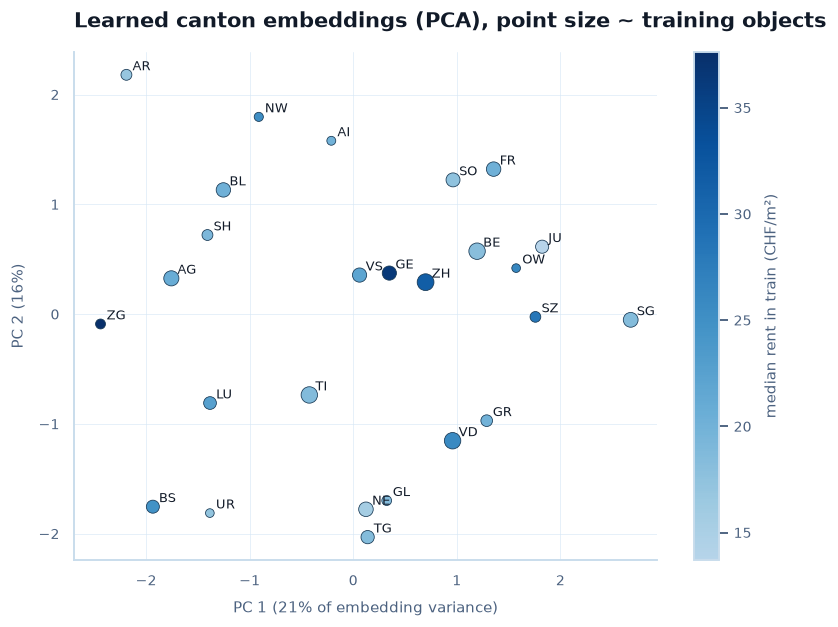

Spearman ρ with CHF/m²: PC1 -0.07, PC2 +0.00


In [36]:
if HAS_TORCH:
    emb_canton = nn_model.embedding_table("re_canton").drop(index=UNKNOWN_LABEL, errors="ignore")
    emb_cols = [c for c in emb_canton if c.startswith("emb_")]
    pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(emb_canton[emb_cols])
    pc = pd.DataFrame(pca.transform(emb_canton[emb_cols]), index=emb_canton.index,
                      columns=["pc1", "pc2"])
    pc["chf_per_m2"] = (train_df["price"] / train_df["area"]).groupby(
        train_df["re_canton"]).median().reindex(pc.index)
    rho = pc[["pc1", "pc2"]].corrwith(pc["chf_per_m2"], method="spearman")
    fig, ax = plt.subplots(figsize=(7.5, 5.8))
    sc = ax.scatter(pc["pc1"], pc["pc2"], c=pc["chf_per_m2"],
                    cmap=ListedColormap(plt.get_cmap("Blues")(np.linspace(0.3, 1.0, 256))),
                    s=25 + 3 * np.sqrt(emb_canton["n_train"]), edgecolor=COLORS["dark"], lw=0.5)
    for label, row in pc.iterrows():
        ax.annotate(label, (row["pc1"], row["pc2"]), xytext=(4, 3), textcoords="offset points",
                    fontsize=8.5)
    fig.colorbar(sc, ax=ax, label="median rent in train (CHF/m²)")
    ax.set(xlabel=f"PC 1 ({pca.explained_variance_ratio_[0]:.0%} of embedding variance)",
           ylabel=f"PC 2 ({pca.explained_variance_ratio_[1]:.0%})",
           title="Learned canton embeddings (PCA), point size ~ training objects")
    fig.tight_layout()
    save_fig(fig, "fused_nn_canton_embeddings")
    plt.show()
    print(f"Spearman ρ with CHF/m²: PC1 {rho['pc1']:+.2f}, PC2 {rho['pc2']:+.2f}")

**Interpretation.** Early stopping worked if the validation MAE reaches its minimum before the last
epoch; a best epoch at the maximum (expected in the fast run) means the network is under-trained.
With a few thousand objects and no text, gradient boosting on tabular data is hard to beat, in line
with the literature; the text branch is the real reason to keep the network. If a principal
component of the canton embeddings correlates strongly with CHF/m² (|ρ| well above 0.5), the
network rebuilt the cantonal rent level from the data. The embeddings are for inspection only.

---

## Phase 4 — Listing text and calibrated uncertainty

## 17. RQ1 Text Ablation: Does the Description Improve the Winning Model?

RQ1 asks whether the description lowers the error **beyond the tabular and location features**.
Following the order of decisions, the ablation runs on the RQ2 winner; each stage adds one kind of
text information:

| Stage | Adds (cumulative) | Fitted on |
|---|---|---|
| S0 tabular + geo | nothing: the RQ2 winner as frozen in section 15 | – |
| S1 + keywords + TF-IDF | keyword flags, 50-dim TF-IDF/SVD (word 1–2- and char 3–5-grams) | training texts |
| S2 + sentence embeddings | 32 PCA components of multilingual sentence embeddings (section 16) | training texts |
| S3 + attributes | extracted attributes of section 8 (`ATTR_SOURCE`) | – |
| S4 fused network | the network of section 16, if it had a text branch (exploratory) | – |
| P + portal attributes | `F_PORTAL` on top of the last text stage (exploratory, not in the Holm family) | – |

**Protocol.** Stages keep the winner's settings (`lgb_params`, or GPBoost's rounds and covariance
parameters); nothing is re-tuned. TF-IDF/SVD and the embedding PCA see only training descriptions,
never a rent. A description under 50 characters counts as "no text" (NaN features, keyword flags
0). **Selection** uses the grouped CV MAE; the **test** set is used once: a paired bootstrap of
`MAE(previous) − MAE(stage)` per stage with a Holm correction across S1–S3. Without descriptions
the section prints a notice and sets `rq1_table = None`.

In [37]:
RQ1_LABELS = {"S0": "tabular + geo (RQ2 winner)", "S1": "+ keywords + TF-IDF-SVD",
              "S2": "+ sentence embeddings", "S3": f"+ structured attributes ({ATTR_SOURCE})",
              "S4": "fused network with text (exploratory)",
              "P": "+ portal attributes (exploratory)"}
rq1_extra = {s: f[[]].copy() for s, f in SPLITS.items()}  # text feature columns per split
RQ1_STAGES: dict[str, list[str]] = {}
rq1_table = None
if HAS_TEXT:
    texts = {s: f["description_anon"].astype("string") for s, f in SPLITS.items()}
    no_text = {s: t.fillna("").str.len().lt(50).to_numpy() for s, t in texts.items()}
    tfidf = text.make_tfidf_svd(50).fit(texts["train"][~no_text["train"]].tolist())
    for s, frame in SPLITS.items():
        short = pd.Series(no_text[s], index=frame.index)
        svd = text.tfidf_features(tfidf, texts[s]).mask(short, axis=0)
        rq1_extra[s] = frame[F_TEXT_KW].mask(short, 0, axis=0).join(svd)
    RQ1_STAGES = {"S0": [], "S1": F_TEXT_KW + list(svd.columns)}
    if EMB is not None:
        emb_cols = [f"emb_{i}" for i in range(EMB["train"].shape[1])]
        for s, frame in SPLITS.items():
            rq1_extra[s] = rq1_extra[s].join(pd.DataFrame(EMB[s], frame.index, emb_cols))
        RQ1_STAGES["S2"] = RQ1_STAGES["S1"] + emb_cols
    if F_ATTR:
        for s, frame in SPLITS.items():
            attrs = frame[F_ATTR].copy()
            for col in attrs.select_dtypes("category"):  # view, parking -> integer codes
                attrs[col] = attrs[col].cat.codes.where(attrs[col].notna()).astype(float)
            rq1_extra[s] = rq1_extra[s].join(attrs.astype(float))
        RQ1_STAGES["S3"] = RQ1_STAGES[list(RQ1_STAGES)[-1]] + F_ATTR
    print("added columns per stage:", {s: len(c) for s, c in RQ1_STAGES.items()})
else:
    print(f"RQ1 skipped: no listing descriptions (data source {DATA_USED!r}).")
RQ1_STAGES = RQ1_STAGES or {"S0": []}
for s, frame in SPLITS.items():  # exploratory stage P: structured portal fields
    rq1_extra[s] = rq1_extra[s].join(frame[F_PORTAL].astype(float))
RQ1_STAGES["P"] = RQ1_STAGES[list(RQ1_STAGES)[-1]] + F_PORTAL


def stage_X(split: str, cols: list[str], rows: np.ndarray | None = None) -> pd.DataFrame:
    base = F_TAB if RQ2_WINNER == "gpboost" else TE_INPUT
    X = SPLITS[split][base].join(rq1_extra[split][cols])
    return X if rows is None else X.iloc[rows]


def fit_stage(cols: list[str], rows: np.ndarray) -> object:
    X, part = stage_X("train", cols, rows), train_df.iloc[rows]
    if RQ2_WINNER == "gpboost":  # rounds and covariance parameters of section 14
        return models.GPBoostRegressor(num_boost_round=GPB_ROUNDS, **GPB_KW).fit(
            X, part["log_price"], part[GROUP_COLS], part[COORDS], cov_pars=gpb_model.cov_)
    return models.make_te_lgbm(F_GEO_LGBM + cols, GROUP_COLS, lgb_params,
                               MONOTONE_INCREASING).fit(X, part["log_price"])


def predict_stage(model: object, split: str, cols: list[str],
                  rows: np.ndarray | None = None) -> np.ndarray:
    X = stage_X(split, cols, rows)
    if RQ2_WINNER != "gpboost":
        return np.exp(model.predict(X))
    frame = SPLITS[split] if rows is None else SPLITS[split].iloc[rows]
    return np.exp(model.predict(X, frame[GROUP_COLS], frame[COORDS]))

added columns per stage: {'S0': 0, 'S1': 74, 'S2': 106, 'S3': 120}


In [38]:
stage_pred: dict[str, np.ndarray] = {}
stage_calib: dict[str, np.ndarray] = {}
rq1_rows = []
for stage, cols in RQ1_STAGES.items():
    if cols:
        model = fit_stage(cols, np.arange(len(train_df)))
        p_calib, p_test = predict_stage(model, "calib", cols), predict_stage(model, "test", cols)
        oof = np.full(len(train_df), np.nan)
        for tr, va in cv_folds:
            oof[va] = predict_stage(fit_stage(cols, tr), "train", cols, va)
    else:  # S0 is the frozen RQ2 winner
        p_calib, p_test, oof = pred_calib[RQ2_WINNER], pred_test[RQ2_WINNER], cv_oof[RQ2_WINNER]
    row = {"stage": stage, "label": RQ1_LABELS[stage], "n_added": len(cols),
           "cv_mae": mae(y_train, oof), "calib_mae": mae(y_calib, p_calib),
           "test_mae": mae(y_test, p_test)}
    if stage_pred:
        prev = list(stage_pred)[-1]
        r = evaluation.paired_bootstrap_mae(y_test, stage_pred[prev], p_test,
                                            n_boot=BUDGET["n_boot"])
        row |= {"vs": prev, "diff": r.diff, "ci_low": r.ci_low, "ci_high": r.ci_high,
                "p_bootstrap": r.p_bootstrap, "p_wilcoxon": r.p_wilcoxon}
    stage_pred[stage], stage_calib[stage] = p_test, p_calib
    rq1_rows.append(row)
if stage_pred and EMB is not None and "fused_nn" in pred_test:  # exploratory S4
    last = list(stage_pred)[-1]
    r = evaluation.paired_bootstrap_mae(y_test, stage_pred[last], pred_test["fused_nn"],
                                        n_boot=BUDGET["n_boot"])
    stage_pred["S4"] = pred_test["fused_nn"]
    rq1_rows.append({"stage": "S4", "label": RQ1_LABELS["S4"], "n_added": np.nan,
                     "cv_mae": mae(y_train, cv_oof["fused_nn"]),
                     "calib_mae": mae(y_calib, pred_calib["fused_nn"]), "test_mae": r.mae_b,
                     "vs": last, "diff": r.diff, "ci_low": r.ci_low, "ci_high": r.ci_high,
                     "p_bootstrap": r.p_bootstrap, "p_wilcoxon": r.p_wilcoxon})

,label,n_added,cv_mae,calib_mae,test_mae,vs,diff,ci_low,ci_high,p_bootstrap,p_wilcoxon,p_holm,reject,supported,selected_by_cv
stage,,,,,,,,,,,,,,,
S0,tabular + geo (RQ2 winner),0.0,321.243,322.570,308.272,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False
S1,+ keywords + TF-IDF-SVD,74.0,287.528,294.297,281.773,S0,26.499,19.133,34.555,0.000,0.000,0.001,True,True,False
S2,+ sentence embeddings,106.0,289.125,297.183,284.071,S1,-2.298,-5.048,0.347,0.102,0.102,0.102,False,False,False
S3,+ structured attributes (rules),120.0,287.337,296.022,281.720,S2,2.350,0.096,4.429,0.031,0.006,0.063,False,False,True
P,+ portal attributes (exploratory),139.0,284.711,294.686,280.115,S3,1.605,-0.950,4.153,0.196,0.108,NaN,NaN,False,False
S4,fused network with text (exploratory),NaN,334.479,347.769,322.165,P,-42.050,-52.874,-32.038,0.000,0.000,NaN,NaN,False,False


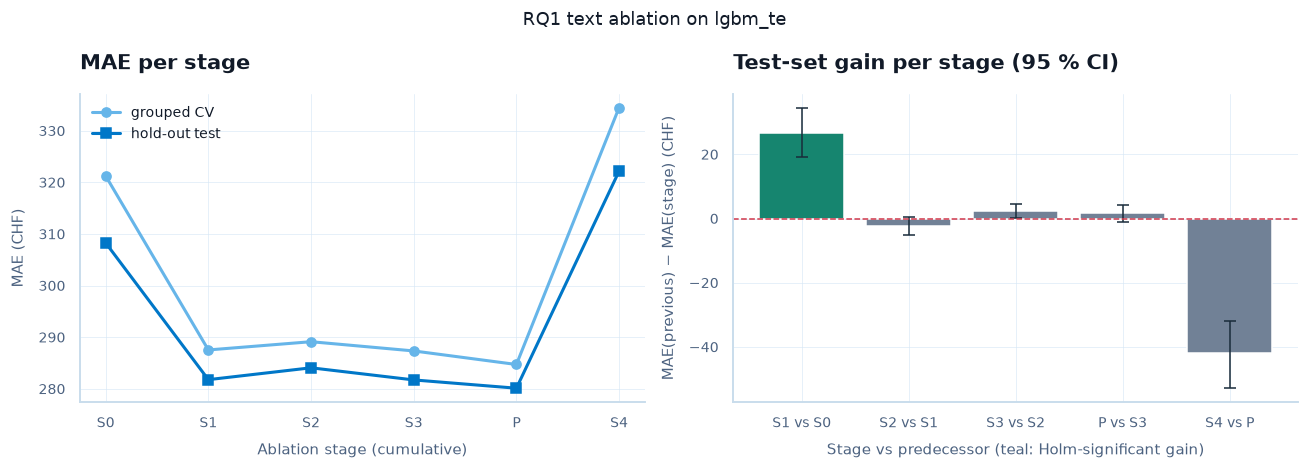

RQ1_SELECTED = 'S3'; RQ3 and the app use the S0 feature set (F_LGB) in this version (text transformers are not yet part of the app bundle).


In [39]:
RQ1_SELECTED = "S0"
if rq1_rows:
    rq1_table = pd.DataFrame(rq1_rows).set_index("stage")
    family = rq1_table.loc[rq1_table.index.isin(["S1", "S2", "S3"]), "p_bootstrap"].dropna()
    rq1_table = rq1_table.join(evaluation.holm_correction(family.to_dict())[["p_holm", "reject"]])
    rq1_table["supported"] = rq1_table["reject"].eq(True) & rq1_table["diff"].gt(0)
    RQ1_SELECTED = str(rq1_table.drop(index=["S4", "P"], errors="ignore")["cv_mae"].idxmin())
    rq1_table["selected_by_cv"] = rq1_table.index == RQ1_SELECTED
    for stage in family.index:
        name, r = f"{RQ2_WINNER}+{stage.lower()}", rq1_table.loc[stage]
        pred_test[name], pred_calib[name] = stage_pred[stage], stage_calib[stage]
        track(name, "attributes" if stage == "S3" else "text",
              {"cv_mae": r["cv_mae"], "calib_mae": r["calib_mae"], **test_metrics(pred_test[name]),
               "diff_vs_prev": r["diff"], "p_boot_vs_prev": r["p_bootstrap"],
               "p_holm": r["p_holm"]},
              tags={"model": RQ2_WINNER, "rq": "RQ1"},
              params={"base_model": RQ2_WINNER, "text_stage": RQ1_LABELS[stage],
                      "n_added_features": int(r["n_added"])})
    if "P" in rq1_table.index:
        r = rq1_table.loc["P"]
        pred_test[f"{RQ2_WINNER}+portal"] = stage_pred["P"]
        pred_calib[f"{RQ2_WINNER}+portal"] = stage_calib["P"]
        track(f"{RQ2_WINNER}+portal", "portal",
              {"cv_mae": r["cv_mae"], "calib_mae": r["calib_mae"],
               **test_metrics(stage_pred["P"]), "diff_vs_prev": r["diff"],
               "p_boot_vs_prev": r["p_bootstrap"]},
              tags={"model": RQ2_WINNER, "rq": "exploratory"},
              params={"base_model": RQ2_WINNER, "text_stage": RQ1_LABELS["P"],
                      "n_added_features": int(r["n_added"])})
    rq1_fmt = {"n_added": ".0f", "cv_mae": ".1f", "calib_mae": ".1f", "test_mae": ".1f",
               "diff": "+.1f", "ci_low": "+.1f", "ci_high": "+.1f", "p_bootstrap": ".3g",
               "p_wilcoxon": ".3g", "p_holm": ".3g"}
    write_table(rq1_table.reset_index(), "rq1_text_ablation", rq1_fmt,
                note=f"base model {RQ2_WINNER}, data {DATA_USED}, run {RUN_MODE}",
                caption=f"RQ1 text ablation on {RQ2_WINNER}: CV and test MAE (CHF), paired "
                        "bootstrap against the previous stage, Holm across S1--S3")
    display(rq1_table.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    x = np.arange(len(rq1_table))
    axes[0].plot(x, rq1_table["cv_mae"], "o-", color=COLORS["secondary"], label="grouped CV")
    axes[0].plot(x, rq1_table["test_mae"], "s-", color=COLORS["primary"], label="hold-out test")
    axes[0].set_xticks(x, rq1_table.index)
    axes[0].yaxis.set_major_formatter(chf_formatter())
    axes[0].set(xlabel="Ablation stage (cumulative)", ylabel="MAE (CHF)", title="MAE per stage")
    axes[0].legend()
    comp = rq1_table.dropna(subset=["diff"])
    axes[1].bar(np.arange(len(comp)), comp["diff"], capsize=4,
                color=[COLORS["teal"] if s else COLORS["gray"] for s in comp["supported"]],
                yerr=[comp["diff"] - comp["ci_low"], comp["ci_high"] - comp["diff"]],
                error_kw={"lw": 1, "ecolor": COLORS["neutral"]})
    axes[1].axhline(0, color=COLORS["reference"], lw=1, ls="--")
    axes[1].set_xticks(np.arange(len(comp)), [f"{s} vs {v}" for s, v in comp["vs"].items()])
    axes[1].set(xlabel="Stage vs predecessor (teal: Holm-significant gain)",
                ylabel="MAE(previous) − MAE(stage) (CHF)",
                title="Test-set gain per stage (95 % CI)")
    fig.suptitle(f"RQ1 text ablation on {RQ2_WINNER}")
    fig.tight_layout()
    save_fig(fig, "rq1_text_ablation")
    plt.show()
print(f"RQ1_SELECTED = {RQ1_SELECTED!r}; RQ3 and the app use the S0 feature set (F_LGB) in this "
      "version (text transformers are not yet part of the app bundle).")

**Interpretation.** With the Comparis descriptions RQ1 is tested for the first time.

- **S1.** A Holm-rejected, positive `MAE(S0) − MAE(S1)` means the wording carries rent information
  the structured features miss (premium and condition words). A CI containing 0 means no gain at
  this test-set resolution (compare the MDE); a rejected *negative* difference means many weak text
  columns dilute the splits.
- **S2** captures paraphrases across languages; if it adds nothing over S1, the cheaper TF-IDF is
  enough. **S3** overlaps with the keywords; a gain must come from values like floor or renovation
  year.
- **Selection vs. confirmation.** `selected_by_cv` (`RQ1_SELECTED`) never uses the test MAE. RQ3 and
  the app keep S0 in this version: serving text features needs the fitted TF-IDF, embedding and
  extraction steps in the bundle (changelog of the evaluation plan). **S4** changes the model
  family and is not part of the Holm family.
- **P** adds the structured portal fields on top of the text. A clear gain means the app
  should ask for floor, lift and similar attributes; it is exploratory (not pre-registered).

## 18. RQ3, Part 1: Monotone Quantile Models

DSPRO1 attached the same ± band to every apartment. A per-apartment interval needs the conditional
distribution, so one LightGBM per quantile level (5, 10, 25, 50, 75, 90, 95 %) is fitted on the log
rent with

- a **custom pinball objective**, because LightGBM's built-in quantile objective rejects monotone
  constraints; every level is monotone in `area` and `area_per_room`;
- a **shifted start**: each level starts at the median model plus the level's quantile of its
  cross-fitted residuals, so its trees only learn how the spread changes. Started from the global
  quantile, cheap flats fall below q10 and expensive flats above q90 far more often than 10 %;
- **rearrangement** (sorting each row), so quantiles never cross;
- the same encoded training matrix as the point model (`X_train_lgb`, the S0 feature set); trees per
  level chosen by the pinball loss on a grouped inner split (20 %), then refitted on all objects.

Learning rate and subsampling come from `lgb_params`; tree size and regularisation keep the
shallow quantile defaults, because a tail level has only 5–10 % of the objects beyond it.

In [40]:
Q_PARAMS = {k: lgb_params[k] for k in ("learning_rate", "subsample", "colsample_bytree")
            if k in lgb_params} | {"n_estimators": 1000}
qmodel = intervals.MonotoneQuantileLGBM(
    levels=QUANTILE_LEVELS, params=Q_PARAMS,
    monotone=models.monotone_vector(F_LGB, MONOTONE_INCREASING), validation_fraction=0.2,
    random_state=RANDOM_STATE,
).fit(X_train_lgb, y_train_log, groups=train_df["object_id"].to_numpy())
LEVELS = qmodel.levels_
Q_NAMES = [f"q{round(100 * a):02d}" for a in LEVELS]
y_calib_log, y_test_log = np.log(y_calib), np.log(y_test)
q_raw_test = qmodel.predict_raw(X_test_lgb)
q_calib, q_test = qmodel.predict(X_calib_lgb), qmodel.predict(X_test_lgb)  # rearranged, log
cross = {"calib raw": intervals.crossing_rate(qmodel.predict_raw(X_calib_lgb)),
         "test raw": intervals.crossing_rate(q_raw_test)}
qcal = {s: intervals.quantile_calibration(y, q, LEVELS) for s, (y, q) in
        {"calib": (y_calib_log, q_calib), "test": (y_test_log, q_test),
         "test_raw": (y_test_log, q_raw_test)}.items()}
quantile_table = pd.DataFrame({
    "quantile": Q_NAMES, "level": LEVELS, "pinball_calib": qcal["calib"]["pinball"],
    "pinball_test": qcal["test"]["pinball"], "pinball_test_raw": qcal["test_raw"]["pinball"],
    "empirical_calib": qcal["calib"]["empirical"], "empirical_test": qcal["test"]["empirical"]})
q10_calib, q90_calib = intervals.quantile_columns(q_calib, LEVELS, (0.1, 0.9)).T
raw_cov_calib = float(np.mean((y_calib_log >= q10_calib) & (y_calib_log <= q90_calib)))
write_table(quantile_table, "quantile_calibration",
            {"level": ".2f"} | {c: ".4f" for c in quantile_table if "pinball" in c}
            | {"empirical_calib": ".3f", "empirical_test": ".3f"},
            note=f"data {DATA_USED}, run {RUN_MODE}, session {SESSION_ID}")
track("quantile_lgbm", "intervals",
      {f"pinball_{s}_{n}": v for s in ("calib", "test")
       for n, v in zip(Q_NAMES, quantile_table[f"pinball_{s}"], strict=True)}
      | {"crossing_rate_calib_raw": cross["calib raw"], "crossing_rate_test_raw": cross["test raw"],
         "calib_coverage_80_raw": raw_cov_calib},
      tags={"model": "quantile_lgbm", "rq": "RQ3"},
      params={"quantile": Q_PARAMS, "levels": ",".join(Q_NAMES), "validation_fraction": 0.2,
              "trees": ",".join(map(str, qmodel.n_trees_.values()))})
print("trees per level:", {f"q{round(100 * k):02d}": v for k, v in sorted(qmodel.n_trees_.items())},
      "| crossing before rearrangement:", {k: f"{v:.2%}" for k, v in cross.items()},
      f"| raw q10-q90 coverage on calibration {raw_cov_calib:.1%}")
display(quantile_table.round(4))

trees per level: {'q05': 999, 'q10': 959, 'q25': 999, 'q50': 1000, 'q75': 999, 'q90': 1000, 'q95': 1000} | crossing before rearrangement: {'calib raw': '0.19%', 'test raw': '0.08%'} | raw q10-q90 coverage on calibration 78.8%


,quantile,level,pinball_calib,pinball_test,pinball_test_raw,empirical_calib,empirical_test
0,q05,0.05,0.0199,0.0201,0.0201,0.0533,0.0586
1,q10,0.10,0.0331,0.0335,0.0335,0.1081,0.1105
2,q25,0.25,0.0592,0.0590,0.0590,0.2546,0.2566
3,q50,0.50,0.0779,0.0762,0.0762,0.4997,0.4972
4,q75,0.75,0.0628,0.0620,0.0620,0.7505,0.7586
5,q90,0.90,0.0370,0.0367,0.0367,0.8961,0.9055
6,q95,0.95,0.0230,0.0229,0.0229,0.9510,0.9534


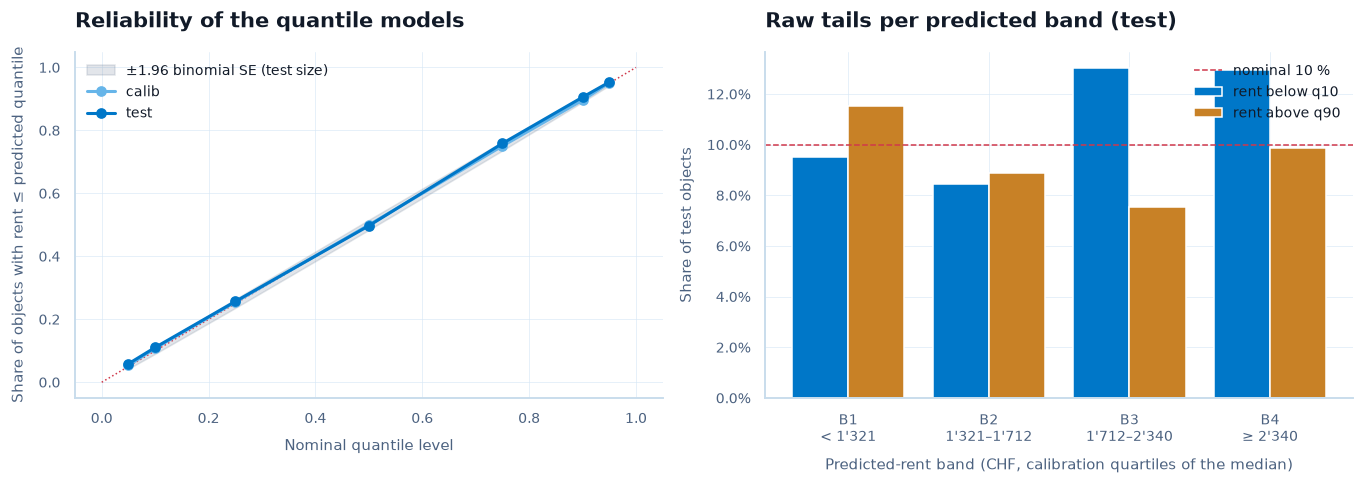

In [41]:
q50_calib = intervals.quantile_columns(q_calib, LEVELS, (0.5,))[:, 0]
q50_test = intervals.quantile_columns(q_test, LEVELS, (0.5,))[:, 0]
band_cutpoints = intervals.fit_band_cutpoints(q50_calib)  # log scale, calibration medians only
BAND_LABELS = [f"B{i + 1}" for i in range(len(band_cutpoints) + 1)]
edges = [f"{v:,.0f}".replace(",", "'") for v in np.exp(band_cutpoints)]
BAND_TEXT = dict(zip(BAND_LABELS, [f"< {edges[0]}", *(f"{a}–{b}" for a, b in
                                                    zip(edges[:-1], edges[1:], strict=True)),
                                   f"≥ {edges[-1]}"], strict=True))
band_test = intervals.assign_band(q50_test, band_cutpoints)
q10_test, q90_test = np.exp(intervals.quantile_columns(q_test, LEVELS, (0.1, 0.9)).T)
raw_band = intervals.coverage_report(y_test, q10_test, q90_test,
                                     pd.Series(band_test, name="band")).drop(index="all")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
se = 1.96 * np.sqrt(LEVELS * (1 - LEVELS) / len(y_test))
axes[0].fill_between(LEVELS, LEVELS - se, LEVELS + se, color=COLORS["gray"], alpha=0.2,
                     label="±1.96 binomial SE (test size)")
axes[0].plot([0, 1], [0, 1], color=COLORS["reference"], ls=":", lw=1)
for split, color in (("calib", COLORS["secondary"]), ("test", COLORS["primary"])):
    axes[0].plot(LEVELS, quantile_table[f"empirical_{split}"], "o-", color=color, label=split)
axes[0].set(xlabel="Nominal quantile level",
            ylabel="Share of objects with rent ≤ predicted quantile",
            title="Reliability of the quantile models")
axes[0].legend()
xb = np.arange(len(raw_band))
axes[1].bar(xb - 0.2, raw_band["below"], 0.4, color=COLORS["primary"], label="rent below q10")
axes[1].bar(xb + 0.2, raw_band["above"], 0.4, color=COLORS["orange"], label="rent above q90")
axes[1].axhline(0.1, color=COLORS["reference"], ls="--", lw=1, label="nominal 10 %")
axes[1].set_xticks(xb, [f"{b}\n{BAND_TEXT[b]}" for b in raw_band.index])
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set(xlabel="Predicted-rent band (CHF, calibration quartiles of the median)",
            ylabel="Share of test objects", title="Raw tails per predicted band (test)")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "quantile_reliability")
plt.show()

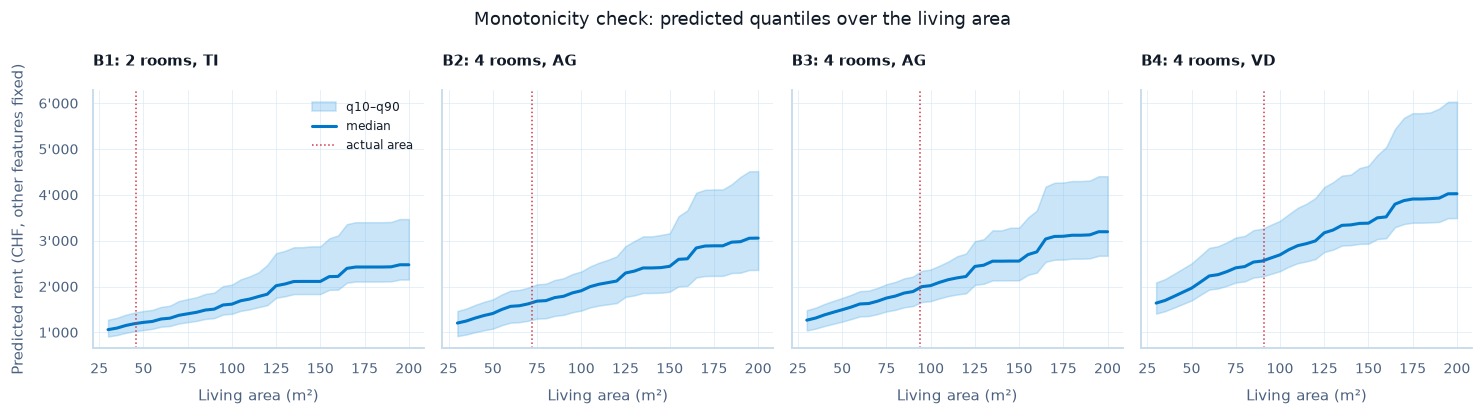

PASS  decreasing quantile steps over the area grid (raw and rearranged): {'area only': 0, 'area_per_room recomputed': 0}


In [42]:
rng = np.random.default_rng(RANDOM_STATE)
picks = [int(rng.choice(np.flatnonzero(band_test == b))) for b in BAND_LABELS
         if (band_test == b).any()]  # one random test object per predicted band
AREA_GRID = np.arange(30.0, 201.0, 5.0)
steps_down = {"area only": 0, "area_per_room recomputed": 0}
fig, axes = plt.subplots(1, len(picks), figsize=(3.4 * len(picks), 3.8), sharey=True)
for ax, pos in zip(axes, picks, strict=True):
    grid = X_test_lgb.iloc[[pos] * len(AREA_GRID)].assign(area=AREA_GRID)
    variants = {"area only": grid, "area_per_room recomputed": data.add_engineered_features(grid)}
    for name, frame in variants.items():
        for q in (qmodel.predict_raw(frame), qmodel.predict(frame)):
            steps_down[name] += int((np.diff(q, axis=0) < -1e-9).sum())
    q_chf = np.exp(intervals.quantile_columns(qmodel.predict(variants["area_per_room recomputed"]),
                                              LEVELS, (0.1, 0.5, 0.9)))
    ax.fill_between(AREA_GRID, q_chf[:, 0], q_chf[:, 2], color=COLORS["secondary"], alpha=0.35,
                    label="q10–q90")
    ax.plot(AREA_GRID, q_chf[:, 1], color=COLORS["primary"], label="median")
    ax.axvline(X_test_lgb["area"].iloc[pos], color=COLORS["reference"], ls=":", lw=1,
               label="actual area")
    ax.set_title(f"{band_test[pos]}: {test_df['rooms'].iloc[pos]:.0f} rooms, "
                 f"{test_df['canton'].iloc[pos]}", fontsize=10)
    ax.set_xlabel("Living area (m²)")
axes[0].set_ylabel("Predicted rent (CHF, other features fixed)")
axes[0].yaxis.set_major_formatter(chf_formatter())
axes[0].legend(fontsize=8)
fig.suptitle("Monotonicity check: predicted quantiles over the living area")
fig.tight_layout()
save_fig(fig, "quantile_monotonicity")
plt.show()
Q_MONOTONE_OK = not any(steps_down.values())
print(f"{'PASS' if Q_MONOTONE_OK else 'FAIL'}  decreasing quantile steps over the area grid "
      f"(raw and rearranged): {steps_down}")

**Interpretation.**

- **Pinball loss** similar on calibration and test means the quantile models generalise.
- **Reliability.** Points inside the grey binomial band mean calibrated quantiles; a curve that is
  too flat means the raw intervals are too narrow, too steep means too wide. Section 19 corrects
  the 80 % interval either way.
- **Tails per predicted band** is the conditional check that marginal coverage hides: bars near
  10 % in every band mean the shifted start works; the Mondrian calibration repairs what is left.
- **Crossing** before rearrangement should be rare; sorting changes only the crossing rows.
- **Monotonicity** must give 0 decreasing steps, also with `area_per_room` recomputed as in the
  app. A FAIL means a constraint was lost (e.g. a renamed feature).

## 19. RQ3, Part 2: Conformal Calibration of the 80 % Intervals

**Split conformal prediction** gives any interval a finite-sample coverage guarantee, using only
the calibration split: the interval is widened, or narrowed, by the empirical quantile of its
errors there.

- **Raw interval of the point model of record.** If LightGBM-TE won RQ2: q10–q90 of the quantile
  models, calibrated with **CQR** (Romano et al. 2019). If GPBoost won: μ ± z·σ, calibrated with
  the **σ-normalised score** |y − μ|/σ. Both are computed; `RQ2_WINNER` picks the primary one.
- **Asymmetric.** Lower and upper ends get separate corrections at 10 % each, so "below" and
  "above" are controlled separately; the fair-rent verdict needs that.
- **Mondrian.** One correction per language region × predicted-rent band (quartiles of the
  calibration *median predictions*, never of the actual rent). Cells with fewer than
  `MIN_MONDRIAN_GROUP` = 100 calibration objects fall back to the region, then to the global cell.
- **Comparisons:** global versions and a constant band ± h in CHF (DSPRO1's single value).

**Hypotheses (tested once on the test set for the primary method):** **H3a** — in every region ×
band cell the upper bound of the exact 95 % Clopper–Pearson interval of the coverage is at least
0.80; **H3b** — the mean width is smaller than that of a constant band tuned *on the test set* to
the same coverage (deliberately optimistic for the constant band). The app always serves the
quantile models with their Mondrian CQR, because the what-if view must be monotone.

In [43]:
ALPHA_IV = round(1 - INTERVAL_COVERAGE, 6)
Z_IV = float(stats.norm.ppf(1 - ALPHA_IV / 2))
IV_SOURCE = "gpboost" if RQ2_WINNER == "gpboost" else "quantile"
PRIMARY_IV = f"mondrian_{IV_SOURCE}"
mu = {"calib": mu_calib, "test": mu_test}
sigma = {"calib": np.sqrt(gpb_var_calib), "test": np.sqrt(gpb_var_test)}
q_split = {"calib": q_calib, "test": q_test}
raw_iv = {}  # (source, split) -> (lo, hi) on the log scale
iv_groups = {}  # (source, split) -> Mondrian groups (lang_region, band)
IV_BAND_CUTS = {"quantile": band_cutpoints,
                "gpboost": intervals.fit_band_cutpoints(mu["calib"])}
for split, frame in SPLITS.items():
    if split == "train":
        continue
    raw_iv["quantile", split] = tuple(intervals.quantile_columns(q_split[split], LEVELS,
                                                                 (0.1, 0.9)).T)
    raw_iv["gpboost", split] = (mu[split] - Z_IV * sigma[split], mu[split] + Z_IV * sigma[split])
    medians = {"quantile": intervals.quantile_columns(q_split[split], LEVELS, (0.5,))[:, 0],
               "gpboost": mu[split]}
    for src, med in medians.items():
        iv_groups[src, split] = pd.DataFrame({
            "lang_region": frame["lang_region"].astype(str).to_numpy(),
            "band": intervals.assign_band(med, IV_BAND_CUTS[src])})
point_iv = {"calib": pred_calib[RQ2_WINNER], "test": pred_test[RQ2_WINNER]}
print(f"RQ2 winner {RQ2_WINNER!r} -> primary method {PRIMARY_IV!r}; raw coverage on calibration: "
      + ", ".join(f"{s} {np.mean((y_calib_log >= lo) & (y_calib_log <= hi)):.1%}"
                  for (s, split), (lo, hi) in raw_iv.items() if split == "calib"))
display(iv_groups[IV_SOURCE, "calib"].value_counts(["lang_region", "band"]).unstack(fill_value=0)
        .style.set_caption(f"calibration objects per cell (< {MIN_MONDRIAN_GROUP}: region "
                           "fallback)"))

RQ2 winner 'lgbm_te' -> primary method 'mondrian_quantile'; raw coverage on calibration: quantile 78.8%, gpboost 87.2%


band,B1,B2,B3,B4
lang_region,,,,
de,402,569,614,536
fr,392,257,246,335
it,140,108,74,63


In [44]:
z_mu = {s: mu[s] / sigma[s] for s in mu}
cqr = {  # name -> (fitted CQR, raw interval per split, groups per split or None)
    "global_quantile": (intervals.CQR(ALPHA_IV).fit(*raw_iv["quantile", "calib"], y_calib_log),
                        lambda s: raw_iv["quantile", s], None),
    "mondrian_quantile": (intervals.CQR(ALPHA_IV, MIN_MONDRIAN_GROUP).fit(
        *raw_iv["quantile", "calib"], y_calib_log, iv_groups["quantile", "calib"]),
        lambda s: raw_iv["quantile", s], "quantile"),
    # sigma-normalised scores as CQR on (mu/sigma, y/sigma); scaled back with sigma below
    "global_gpboost": (intervals.CQR(ALPHA_IV).fit(z_mu["calib"], z_mu["calib"],
                                                   y_calib_log / sigma["calib"]),
                       lambda s: (z_mu[s], z_mu[s]), None),
    "mondrian_gpboost": (intervals.CQR(ALPHA_IV, MIN_MONDRIAN_GROUP).fit(
        z_mu["calib"], z_mu["calib"], y_calib_log / sigma["calib"], iv_groups["gpboost", "calib"]),
        lambda s: (z_mu[s], z_mu[s]), "gpboost"),
}
mondrian = cqr["mondrian_quantile"][0]  # served by the app (section 23)
h_const = intervals.constant_band(y_calib, point_iv["calib"], ALPHA_IV)


def interval_methods(split: str) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    # All candidate 80 % intervals of one split, in CHF.
    out = {"raw_quantile": raw_iv["quantile", split], "raw_gpboost": raw_iv["gpboost", split]}
    for name, (cal, raw, src) in cqr.items():
        lo, hi, _ = cal.predict(*raw(split), None if src is None else iv_groups[src, split])
        scale = sigma[split] if name.endswith("gpboost") else 1.0
        out[name] = (lo * scale, hi * scale)
    out = {name: (np.exp(lo), np.exp(hi)) for name, (lo, hi) in out.items()}
    out["constant_conformal"] = (point_iv[split] - h_const, point_iv[split] + h_const)
    return out


iv_calib, iv_test_all = interval_methods("calib"), interval_methods("test")
prim_cal, _, _ = cqr[PRIMARY_IV]
served = prim_cal.predict(*cqr[PRIMARY_IV][1]("test"), iv_groups[IV_SOURCE, "test"])[2]
print("test objects served per hierarchy level:",
      prim_cal.cells_.loc[served, "level"].value_counts(normalize=True).round(3).to_dict())
display(prim_cal.cells_.round(3))

test objects served per hierarchy level: {'lang_region × band': 0.963, 'lang_region': 0.037}


,level,n,qhat_lo,qhat_hi,calibrated
cell,,,,,
de × B1,lang_region × band,402,-0.004,0.007,True
de × B2,lang_region × band,569,-0.025,0.004,True
de × B3,lang_region × band,614,0.009,-0.004,True
de × B4,lang_region × band,536,0.059,-0.012,True
fr × B1,lang_region × band,392,0.007,0.014,True
fr × B2,lang_region × band,257,-0.027,0.029,True
fr × B3,lang_region × band,246,-0.007,0.042,True
fr × B4,lang_region × band,335,0.018,-0.011,True
it × B1,lang_region × band,140,-0.036,0.018,True


In [45]:
cell_test = {src: pd.Series((g["lang_region"] + " × " + g["band"]).to_numpy(), name="cell")
             for (src, split), g in iv_groups.items() if split == "test"}
IV_DESC = {"raw_quantile": ("quantile", "raw q10-q90"),  # ASCII: also used in LaTeX
           "global_quantile": ("quantile", "CQR, global"),
           "mondrian_quantile": ("quantile", "CQR, Mondrian"),
           "raw_gpboost": ("gpboost", "raw Gaussian mu +/- z sigma"),
           "global_gpboost": ("gpboost", "sigma-normalised, global"),
           "mondrian_gpboost": ("gpboost", "sigma-normalised, Mondrian"),
           "constant_conformal": (RQ2_WINNER, "constant +/- h (conformal)")}
rq3_rows = {}
for name, (src, desc) in IV_DESC.items():
    lo, hi = iv_test_all[name]
    rep = intervals.coverage_report(y_test, lo, hi, cell_test[src if src in cell_test
                                                              else IV_SOURCE])
    overall, cells = rep.loc["all"], rep.drop(index="all")
    const_w = 2 * intervals.constant_band_for_coverage(y_test, point_iv["test"],
                                                       overall["coverage"])
    lo_c, hi_c = iv_calib[name]
    rq3_rows[name] = {
        "source": src, "calibration": desc, "primary": name == PRIMARY_IV,
        "calib_coverage": float(np.mean((y_calib >= lo_c) & (y_calib <= hi_c))),
        **overall[["coverage", "cp_low", "cp_high", "below", "above", "mean_width",
                   "median_width"]].to_dict(),
        "interval_score": intervals.interval_score(y_test, lo, hi, ALPHA_IV),
        "min_cell_coverage": cells["coverage"].min(),
        "cells_below_nominal": int((cells["cp_high"] < INTERVAL_COVERAGE).sum()),
        "n_cells": len(cells), "const_width_same_cov": const_w,
        "width_ratio": overall["mean_width"] / const_w}
rq3_table = pd.DataFrame.from_dict(rq3_rows, orient="index").rename_axis("method").reset_index()
rq3_fmt = {c: ".3f" for c in ("calib_coverage", "coverage", "cp_low", "cp_high", "below", "above",
                              "min_cell_coverage", "width_ratio")} \
    | {c: ".0f" for c in ("mean_width", "median_width", "interval_score", "cells_below_nominal",
                          "n_cells", "const_width_same_cov")}
display(rq3_table.round(3))

,method,source,calibration,primary,calib_coverage,coverage,cp_low,cp_high,below,above,mean_width,median_width,interval_score,min_cell_coverage,cells_below_nominal,n_cells,const_width_same_cov,width_ratio
0,raw_quantile,quantile,raw q10-q90,False,0.788,0.795,0.782,0.808,0.111,0.094,1008.286,730.540,1645.843,0.581,1,12,789.901,1.276
1,global_quantile,quantile,"CQR, global",False,0.801,0.807,0.794,0.819,0.102,0.091,1029.302,749.494,1645.028,0.613,1,12,832.261,1.237
2,mondrian_quantile,quantile,"CQR, Mondrian",True,0.800,0.807,0.794,0.819,0.103,0.090,1034.435,735.525,1639.237,0.629,1,12,832.261,1.243
3,raw_gpboost,gpboost,raw Gaussian mu +/- z sigma,False,0.872,0.879,0.868,0.889,0.058,0.063,1136.248,992.130,1718.006,0.557,1,12,1133.408,1.003
4,global_gpboost,gpboost,"sigma-normalised, global",False,0.801,0.800,0.787,0.813,0.105,0.095,911.864,796.167,1696.367,0.492,5,12,809.055,1.127
5,mondrian_gpboost,gpboost,"sigma-normalised, Mondrian",False,0.801,0.796,0.783,0.809,0.107,0.097,942.272,717.363,1659.262,0.574,1,12,794.971,1.185
6,constant_conformal,lgbm_te,constant +/- h (conformal),False,0.800,0.805,0.792,0.817,0.084,0.112,823.530,823.530,1878.624,0.355,3,12,820.651,1.004


In [46]:
realised = pd.Series(intervals.assign_band(y_test_log, IV_BAND_CUTS[IV_SOURCE]),
                     name="realised band")
compare = [f"raw_{IV_SOURCE}", PRIMARY_IV]
cell_cov = pd.concat({m: intervals.coverage_report(y_test, *iv_test_all[m], cell_test[IV_SOURCE])
                      for m in compare}, names=["method"])
band_cov = pd.concat({m: intervals.coverage_report(y_test, *iv_test_all[m], realised)
                      for m in [*compare, "constant_conformal"]}, names=["method"])
prim = cell_cov.loc[PRIMARY_IV].drop(index="all")
fails = prim[prim["cp_high"] < INTERVAL_COVERAGE]
shown = fails if len(fails) else prim.nsmallest(1, "coverage")
cells_txt = "; ".join(f"{c} {r['coverage']:.1%} (n = {int(r['n'])})" for c, r in shown.iterrows())
r3 = rq3_table.set_index("method").loc[PRIMARY_IV]
decision_rq3 = pd.DataFrame([
    ("H3a", f"every region × band cell: upper 95 % CP bound ≥ {INTERVAL_COVERAGE:.0%}",
     f"{len(prim) - len(fails)} of {len(prim)} cells pass; "
     + ("failing: " if len(fails) else "lowest: ") + cells_txt, fails.empty),
    ("H3b", "mean width < constant band with the same empirical coverage",
     f"{r3['mean_width']:,.0f} vs {r3['const_width_same_cov']:,.0f} CHF (ratio "
     f"{r3['width_ratio']:.2f}) at coverage {r3['coverage']:.1%}", bool(r3["width_ratio"] < 1)),
], columns=["hypothesis", "criterion", "estimate", "supported"])
display(decision_rq3.style.hide(axis="index"))
display(cell_cov.round(3))
display(band_cov.round(3))

hypothesis,criterion,estimate,supported
H3a,every region × band cell: upper 95 % CP bound ≥ 80%,11 of 12 cells pass; failing: it × B4 62.9% (n = 62),False
H3b,mean width < constant band with the same empirical coverage,"1,034 vs 832 CHF (ratio 1.24) at coverage 80.7%",False


n  coverage  below  above  mean_width  \
method            cell                                                
raw_quantile      de × B1   419     0.795  0.110  0.095     501.184   
                  de × B2   549     0.843  0.069  0.087     619.158   
                  de × B3   629     0.789  0.141  0.070     845.782   
                  de × B4   541     0.778  0.137  0.085    1706.779   
                  fr × B1   388     0.765  0.090  0.144     502.461   
                  fr × B2   223     0.803  0.108  0.090     681.521   
                  fr × B3   276     0.808  0.116  0.076     927.865   
                  fr × B4   330     0.797  0.106  0.097    2271.384   
                  it × B1   137     0.839  0.066  0.095     526.052   
                  it × B2   105     0.790  0.114  0.095     779.305   
                  it × B3    78     0.795  0.090  0.115    1133.553   
                  it × B4    62     0.581  0.194  0.226    2706.331   
                  all      3737     0.795  0.111  0.094    1008.286   
mondrian_quantile de × B1   419     0.790  0.119  0.091     506.917   
                  de × B2   549     0.823  0.093  0.084     595.263   
                  de × B3   629     0.803  0.124  0.073     851.300   
                  de × B4   541     0.832  0.076  0.092    1797.458   
                  fr × B1   388     0.791  0.088  0.121     526.972   
                  fr × B2   223     0.780  0.130  0.090     703.172   
                  fr × B3   276     0.822  0.116  0.062    1027.049   
                  fr × B4   330     0.806  0.088  0.106    2268.439   
                  it × B1   137     0.861  0.080  0.058     518.883   
                  it × B2   105     0.771  0.114  0.114     709.183   
                  it × B3    78     0.833  0.090  0.077    1254.814   
                  it × B4    62     0.629  0.161  0.210    2932.981   
                  all      3737     0.807  0.103  0.090    1034.435   

                           median_width  cp_low  cp_high  
method            cell                                    
raw_quantile      de × B1       480.299   0.753    0.832  
                  de × B2       597.436   0.810    0.873  
                  de × B3       808.531   0.755    0.820  
                  de × B4      1537.612   0.741    0.813  
                  fr × B1       475.777   0.720    0.807  
                  fr × B2       611.667   0.744    0.853  
                  fr × B3       882.587   0.756    0.853  
                  fr × B4      1695.234   0.749    0.839  
                  it × B1       512.498   0.767    0.897  
                  it × B2       753.016   0.700    0.864  
                  it × B3      1117.755   0.688    0.878  
                  it × B4      2195.878   0.448    0.705  
                  all           730.540   0.782    0.808  
mondrian_quantile de × B1       486.136   0.748    0.828  
                  de × B2       573.059   0.789    0.854  
                  de × B3       813.504   0.770    0.833  
                  de × B4      1609.293   0.798    0.862  
                  fr × B1       499.998   0.747    0.831  
                  fr × B2       631.373   0.720    0.833  
                  fr × B3       972.524   0.772    0.866  
                  fr × B4      1694.689   0.759    0.847  
                  it × B1       501.542   0.792    0.914  
                  it × B2       688.044   0.679    0.848  
                  it × B3      1236.467   0.732    0.908  
                  it × B4      2383.873   0.497    0.748  
                  all           735.525   0.794    0.819

n  coverage  below  above  mean_width  \
method             realised band                                             
raw_quantile       B1              949     0.788  0.181  0.031     545.444   
                   B2              922     0.803  0.123  0.075     671.988   
                   B3              911     0.818  0.102  0.080     917.634   
                   B4              955     0.773  0.037  0.191    1879.373   
                   all            3737     0.795  0.111  0.094    1008.286   
mondrian_quantile  B1              949     0.781  0.197  0.022     552.496   
                   B2              922     0.809  0.125  0.066     674.596   
                   B3              911     0.851  0.070  0.079     949.782   
                   B4              955     0.788  0.019  0.193    1941.504   
                   all            3737     0.807  0.103  0.090    1034.435   
constant_conformal B1              949     0.943  0.056  0.001     823.530   
                   B2              922     0.919  0.060  0.022     823.530   
                   B3              911     0.852  0.087  0.061     823.530   
                   B4              955     0.512  0.132  0.356     823.530   
                   all            3737     0.805  0.084  0.112     823.530   

                                  median_width  cp_low  cp_high  
method             realised band                                 
raw_quantile       B1                  494.184   0.761    0.814  
                   B2                  609.147   0.775    0.828  
                   B3                  822.357   0.791    0.842  
                   B4                 1522.286   0.745    0.799  
                   all                 730.540   0.782    0.808  
mondrian_quantile  B1                  504.953   0.753    0.807  
                   B2                  606.201   0.782    0.834  
                   B3                  852.896   0.826    0.873  
                   B4                 1584.609   0.761    0.814  
                   all                 735.525   0.794    0.819  
constant_conformal B1                  823.530   0.926    0.957  
                   B2                  823.530   0.899    0.935  
                   B3                  823.530   0.827    0.874  
                   B4                  823.530   0.480    0.544  
                   all                 823.530   0.792    0.817

In [47]:
# How often does H3a fail by chance alone? Calibrated cells with this run's cell sizes:
# calibration n of the serving level (cell, else region, else all) and test n per cell.
g_cal, g_test = iv_groups[IV_SOURCE, "calib"], iv_groups[IV_SOURCE, "test"]
n_cell_cal = g_cal.value_counts(["lang_region", "band"])
n_reg_cal = g_cal["lang_region"].value_counts()
test_cells = g_test.value_counts(["lang_region", "band"])
n_cal = np.array([n_cell_cal.get(c, 0) if n_cell_cal.get(c, 0) >= MIN_MONDRIAN_GROUP
                  else n_reg_cal.get(c[0], 0) if n_reg_cal.get(c[0], 0) >= MIN_MONDRIAN_GROUP
                  else len(g_cal) for c in test_cells.index], dtype=float)
n_te, n_sim = test_cells.to_numpy(), 20 * BUDGET["power_sims"]
sim_rng = np.random.default_rng(RANDOM_STATE)
k_side = np.ceil((n_cal + 1) * (1 - ALPHA_IV / 2))  # conformal rank of each side
miss = [sim_rng.beta(n_cal + 1 - k_side, k_side, size=(n_sim, len(n_cal))) for _ in range(2)]
h3a_null = {}
for noise, cov in {"test noise only": np.full((n_sim, len(n_cal)), INTERVAL_COVERAGE),
                   "test + calibration noise": 1 - miss[0] - miss[1]}.items():
    hits = sim_rng.binomial(n_te, np.clip(cov, 0, 1))
    cp_hi = np.where(hits < n_te, stats.beta.ppf(0.975, hits + 1, np.maximum(n_te - hits, 1)), 1)
    n_fail = (cp_hi < INTERVAL_COVERAGE).sum(axis=1)
    h3a_null[noise] = {"P(>= 1 cell fails)": (n_fail >= 1).mean(),
                       "P(>= 2 cells fail)": (n_fail >= 2).mean()}
print(f"H3a under calibrated cells ({len(n_te)} cells, {n_sim:,} simulations):")
display(pd.DataFrame(h3a_null).T.style.format("{:.1%}"))

H3a under calibrated cells (12 cells, 10,000 simulations):


,P(>= 1 cell fails),P(>= 2 cells fail)
test noise only,22.4%,2.5%
test + calibration noise,52.6%,15.2%


In [48]:
iv_lo, iv_hi = iv_test_all[PRIMARY_IV]
MAP_LEVELS = {"canton": ("canton", "canton"), "district": ("district_id", "district_name"),
              "municipality": ("municipality_id", "municipality_name")}
rel_parts = []
for level, (key, label) in MAP_LEVELS.items():  # drill-down of the app's reliability layer
    rep = intervals.coverage_report(y_test, iv_lo, iv_hi, test_df[key].rename("key"))
    rep = rep.drop(index="all").query("n >= @MIN_MAP_CELL")  # publication rule of the app
    names = test_df.groupby(key)[label].first()
    rel_parts.append(rep.assign(level=level, unit=names.reindex(rep.index).to_numpy())
                     .reset_index())
reliability_map = pd.concat(rel_parts, ignore_index=True)[
    ["level", "key", "unit", "n", "coverage", "cp_low", "cp_high"]]
note = f"RQ2 winner {RQ2_WINNER}, data {DATA_USED}, run {RUN_MODE}, session {SESSION_ID}"
write_table(reliability_map, "rq3_reliability_map",
            {c: ".3f" for c in ("coverage", "cp_low", "cp_high")},
            note=f"{PRIMARY_IV}, cells with >= {MIN_MAP_CELL} test objects, {note}")
write_table(rq3_table, "rq3_intervals", rq3_fmt, note=note,
            caption=f"RQ3: 80 % intervals on the test set (CHF); primary method "
                    f"{PRIMARY_IV.replace('_', ' ')}")
cov_fmt = {c: ".3f" for c in ("coverage", "below", "above", "cp_low", "cp_high")} \
    | {"mean_width": ".0f", "median_width": ".0f"}
write_table(cell_cov.reset_index(), "rq3_coverage_cells", cov_fmt, note=note)
write_table(band_cov.reset_index(), "rq3_coverage_realised_band", cov_fmt, note=note)
for _, r in rq3_table.iterrows():
    track(f"interval_{r['method']}", "intervals",
          {k: r[k] for k in ("coverage", "cp_low", "cp_high", "below", "above", "calib_coverage",
                             "mean_width", "median_width", "interval_score", "min_cell_coverage",
                             "cells_below_nominal", "width_ratio")},
          tags={"rq": "RQ3", "primary": str(r["primary"]).lower()},
          params={"source": r["source"], "calibration": r["calibration"], "alpha": ALPHA_IV,
                  "min_group_size": MIN_MONDRIAN_GROUP, "rq2_winner": RQ2_WINNER},
          tables={"coverage_cells": cell_cov.reset_index(), "rq3_decision": decision_rq3}
          if r["primary"] else None)
print(f"published reliability cells: {reliability_map['level'].value_counts().to_dict()}; "
      "below nominal (CP upper < 80 %): "
      f"{int((reliability_map['cp_high'] < INTERVAL_COVERAGE).sum())}")

published reliability cells: {'district': 61, 'municipality': 26, 'canton': 20}; below nominal (CP upper < 80 %): 3


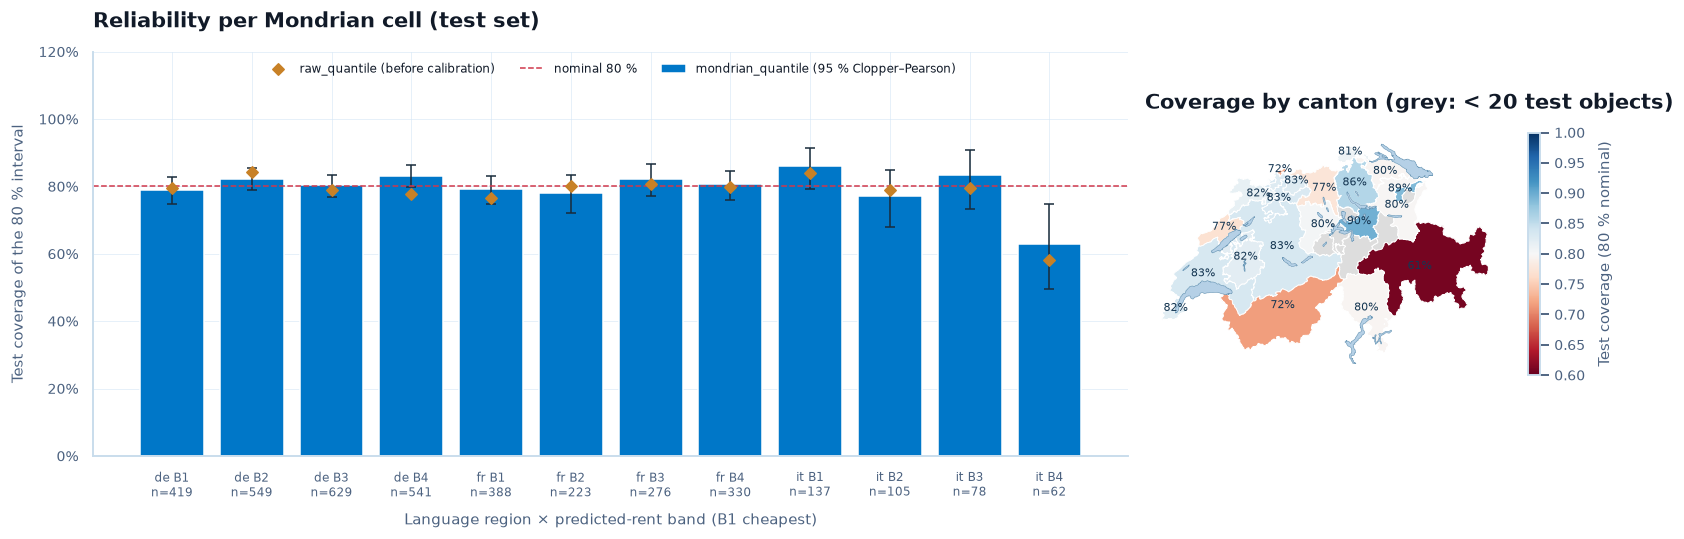

In [49]:
raw_c = cell_cov.loc[f"raw_{IV_SOURCE}"].drop(index="all").reindex(prim.index)
fig, (ax, axm) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.3, 1]})
x = np.arange(len(prim))
ax.bar(x, prim["coverage"], color=COLORS["primary"], label=f"{PRIMARY_IV} (95 % Clopper–Pearson)",
       yerr=[prim["coverage"] - prim["cp_low"], prim["cp_high"] - prim["coverage"]], capsize=3,
       error_kw={"lw": 1, "ecolor": COLORS["neutral"]})
ax.scatter(x, raw_c["coverage"], marker="D", s=28, color=COLORS["orange"], zorder=3,
           label=f"raw_{IV_SOURCE} (before calibration)")
ax.axhline(INTERVAL_COVERAGE, color=COLORS["reference"], ls="--", lw=1, label="nominal 80 %")
ax.set_xticks(x, [f"{c.replace(' × ', ' ')}\nn={int(n)}" for c, n in prim["n"].items()],
              fontsize=8)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(ylim=(0, 1.2), xlabel="Language region × predicted-rent band (B1 cheapest)",
       ylabel="Test coverage of the 80 % interval",
       title="Reliability per Mondrian cell (test set)")
ax.legend(fontsize=8, loc="upper center", ncols=3)
canton_cov = reliability_map[reliability_map["level"].eq("canton")].set_index("key")["coverage"]
cmap, cnorm = plt.get_cmap("RdBu"), TwoSlopeNorm(vmin=0.6, vcenter=INTERVAL_COVERAGE, vmax=1.0)
CANTONS.plot(ax=axm, edgecolor="white", linewidth=0.6,
             color=[cmap(cnorm(canton_cov[c])) if c in canton_cov.index else to_rgba("#dddddd")
                    for c in CANTONS.index])
maps.plot_lakes(axm, LAKES)
for c, pt in CANTONS.representative_point().items():
    if c in canton_cov.index:
        axm.annotate(f"{canton_cov[c]:.0%}", (pt.x, pt.y), ha="center", fontsize=7,
                     color=COLORS["dark"])
fig.colorbar(plt.cm.ScalarMappable(norm=cnorm, cmap=cmap), ax=axm, shrink=0.6,
             label="Test coverage (80 % nominal)")
axm.set_axis_off()
axm.set_title(f"Coverage by canton (grey: < {MIN_MAP_CELL} test objects)")
fig.tight_layout()
save_fig(fig, "rq3_reliability")
plt.show()

**Interpretation.**

- **Raw vs. calibrated.** Orange diamonds below 80 % in the cheap or expensive bands are the tail
  bias of section 18; above 80 % the raw interval was too wide and calibration *narrows* it
  (negative corrections in the cell table).
- **H3a.** A pass in a small cell (Ticino has only a few dozen test objects) means "not detectably
  below nominal". Conformal calibration guarantees 80 % only on average over calibration draws, so
  calibration and test noise together move a cell by several points while the CP interval covers
  only the test noise, and the cells are tested without multiplicity correction (as
  pre-registered). The simulation gives the chance of at least one or two failing cells for
  perfectly calibrated cells of this size: a single failure within that range is a finding for that
  segment, not evidence of a systematic defect; more failures, or a failure repeated across runs,
  would be. Cells served by a fallback need more calibration data, not a smaller
  `MIN_MONDRIAN_GROUP`.
- **H3b.** A width ratio below 1 is conservative evidence for per-apartment intervals. Above 1 does
  not make the constant band better: log-scale intervals are very wide in CHF for the most expensive
  flats, which dominate the mean width, while the constant band reaches the same overall coverage
  only by failing where rents are high (see the realised-band table). Median width and interval
  score weigh both aspects.
- **Realised band** is diagnostic only: objects with an unusual actual rent are by construction far
  from their prediction, and the actual rent is unknown when the interval is issued.
- **Reliability map.** Cantons, districts and municipalities whose CP upper bound stays below 80 %
  are where the app should warn that its interval is too narrow.

---

## Phase 5 — Explain, check and deliver

## 20. Explainability: What Drives an Estimate?

A rent estimate is only useful in the Fair-Rent Check if a tenant can see *why* the model arrives
at it. We explain the monotone LightGBM point model `lgb_point`, which serves the app whatever
model won RQ2. TreeSHAP gives exact Shapley values; on the log scale they are additive, on the rent
multiplicative: +0.10 means about +10.5 % relative to the base rent. These are associations learned
from asking rents, not causal effects. Up to `BUDGET["shap_rows"]` test objects are explained.

In [50]:
shap_expl = models.tree_shap(lgb_point, X_test_lgb, max_rows=BUDGET["shap_rows"],
                             seed=RANDOM_STATE)
shap_importance = models.global_importance(shap_expl)
shap_ids = list(shap_expl.instance_names)
print(f"TreeSHAP for {len(shap_ids):,} test objects; base value "
      f"{np.exp(shap_expl.base_values[0]):,.0f} CHF (about the geometric mean training rent)")
display(shap_importance.head(10).round(3))

TreeSHAP for 2,000 test objects; base value 1,807 CHF (about the geometric mean training rent)


,feature,mean_abs_shap,mean_shap,share,approx_pct
0,area,0.150,-0.000,0.230,16.186
1,re_district,0.088,0.003,0.134,9.170
2,rooms,0.074,0.001,0.114,7.710
3,re_municipality,0.052,0.001,0.080,5.367
4,re_canton,0.032,-0.000,0.049,3.248
5,area_per_room,0.031,-0.001,0.047,3.147
6,year_built,0.030,0.001,0.046,3.025
7,muni_density,0.028,-0.000,0.042,2.813
8,muni_population,0.020,-0.000,0.031,2.063
9,land_area_per_apartment,0.018,-0.001,0.027,1.785


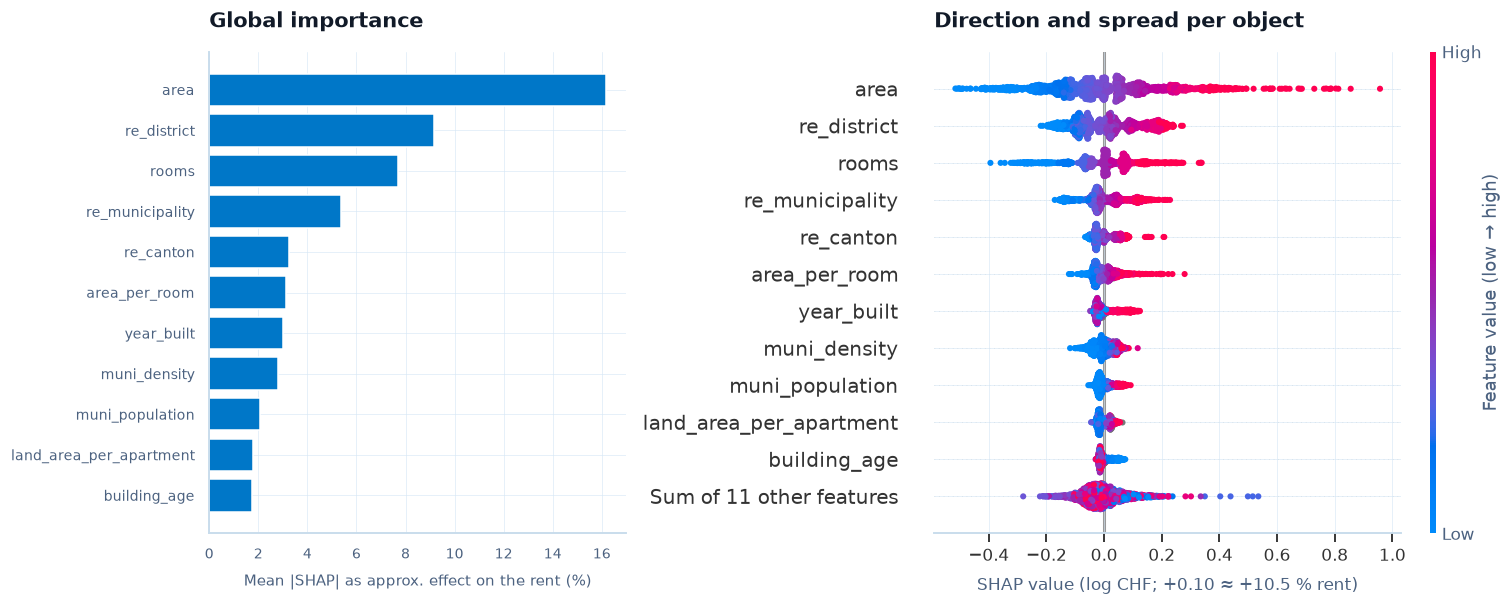

In [51]:
top = shap_importance.head(11).iloc[::-1]  # the beeswarm shows the same 11 plus "all others"
fig, (ax_bar, ax_bee) = plt.subplots(1, 2, figsize=(14, 5.6),
                                     gridspec_kw={"width_ratios": [1, 1.4]})
ax_bar.barh(top["feature"], top["approx_pct"], color=COLORS["primary"])
ax_bar.set(xlabel="Mean |SHAP| as approx. effect on the rent (%)", title="Global importance")
shap.plots.beeswarm(shap_expl, max_display=12, show=False, ax=ax_bee, plot_size=None,
                    color_bar_label="Feature value (low → high)")
ax_bee.set_xlabel("SHAP value (log CHF; +0.10 ≈ +10.5 % rent)", fontsize=11)
ax_bee.set_title("Direction and spread per object")
fig.tight_layout()
shap_png, _ = save_fig(fig, "shap_importance_beeswarm")
plt.show()

In [52]:
pred_shap = np.exp(shap_expl.base_values + shap_expl.values.sum(axis=1))
EXAMPLES = {label: int(np.argmin(np.abs(pred_shap - np.quantile(pred_shap, q))))
            for label, q in [("cheap", 0.10), ("median", 0.50), ("expensive", 0.90)]}
example_drivers = pd.concat(
    [models.top_drivers(shap_expl, pos, k=3).assign(
        example=label, estimate=pred_shap[pos], area=test_df.loc[shap_ids[pos], "area"],
        canton=test_df.loc[shap_ids[pos], "canton"]) for label, pos in EXAMPLES.items()],
    ignore_index=True)
display(example_drivers[["example", "estimate", "area", "canton", "feature", "value",
                         "approx_pct"]].round(1).style.hide(axis="index"))

example,estimate,area,canton,feature,value,approx_pct
cheap,1075.800000,68.000000,AR,area,68.000000,-11.200000
cheap,1075.800000,68.000000,AR,re_district,7.205374,-9.800000
cheap,1075.800000,68.000000,AR,rooms,2.500000,-7.000000
median,1745.300000,93.000000,SG,area,93.000000,4.400000
median,1745.300000,93.000000,SG,year_built,2013.000000,2.700000
median,1745.300000,93.000000,SG,re_canton,7.340307,-2.300000
expensive,3126.700000,94.000000,AG,oev,23676.000000,10.600000
expensive,3126.700000,94.000000,AG,area_per_room,37.600000,8.400000
expensive,3126.700000,94.000000,AG,re_district,7.576590,6.600000


In [53]:
pred_point_test = pred_test["lgbm_te"]  # lgb_point on X_test_lgb
grid_rows = X_test_lgb.sample(n=min(200, len(X_test_lgb)), random_state=RANDOM_STATE)
AREA_GRID = np.arange(30.0, 201.0, 10.0)
grid = grid_rows.loc[grid_rows.index.repeat(len(AREA_GRID))].assign(
    area=np.tile(AREA_GRID, len(grid_rows)))
sanity = {
    "no NaN, positive": bool(np.isfinite(pred_point_test).all() and (pred_point_test > 0).all()),
    "plausible 50-20'000 CHF": bool(pred_point_test.min() >= 50 and pred_point_test.max() <= 20e3),
    "not collapsed (std > 50 CHF)": bool(pred_point_test.std() > 50),
}
for label, frame in [("area only", grid),
                     ("area_per_room recomputed", data.add_engineered_features(grid))]:
    curves = lgb_point.predict(frame[F_LGB]).reshape(len(grid_rows), len(AREA_GRID))
    sanity[f"monotone in area ({label})"] = bool((np.diff(curves, axis=1) >= -1e-12).all())
display(pd.Series(sanity, name="passed").to_frame().T)
track("shap_lgb_point", "diagnostics",
      {"sanity_passed": sum(sanity.values()), "sanity_total": len(sanity),
       "top_feature_share": shap_importance["share"].iloc[0]},
      params={"model": "lgb_point", "shap_rows": len(shap_ids)},
      tables={"shap_importance": shap_importance}, artifacts=[shap_png])

,"no NaN, positive",plausible 50-20'000 CHF,not collapsed (std > 50 CHF),monotone in area (area only),monotone in area (area_per_room recomputed)
passed,True,True,True,True,True


**Interpretation.** If area and the location signals (target encodings, coordinates, public
transport) dominate, the model learned the familiar hedonic structure: size sets the scale,
location the price level per m². In the beeswarm, red points on the right mean "higher value,
higher rent"; mixed colours mean interactions (building age: new builds and renovated old
buildings can both be expensive). The example drivers read the way the Fair-Rent Check presents
them and explain the *model*, not the market. The monotonicity tests check 200 objects over a whole
area grid; the second also recomputes `area_per_room` as the app does, which is only guaranteed
because that feature is constrained too.

## 21. Error Analysis: Where Does the Model Fail?

The evaluation plan fixes the segments: language region, predicted and realised price band,
urban/rural and listings per municipality, for the RQ2 winner. Bands apply `band_cutpoints`
(calibration set) to the quantile median (predicted band) or to the actual rent (realised band,
diagnostic only). Urban/rural is a documented proxy until the BFS typology is joined: tertiles of
municipal population density, cutpoints from the training objects.

In [54]:
ERR_MODEL = RQ2_WINNER
p_err = pred_test[ERR_MODEL]
DENSITY_CUTS = train_df["muni_density"].quantile([1 / 3, 2 / 3]).to_numpy()
DENSITY_LABELS = ["rural", "intermediate", "urban"]
band_cat = pd.CategoricalDtype(BAND_LABELS, ordered=True)
segments = {
    "language region": test_df["lang_region"].to_numpy(),
    "predicted band": pd.Categorical(band_test, dtype=band_cat),
    "realised band": pd.Categorical(intervals.assign_band(y_test_log, band_cutpoints),
                                    dtype=band_cat),
    "urban/rural": pd.cut(test_df["muni_density"].to_numpy(dtype=float),
                          [-np.inf, *DENSITY_CUTS, np.inf], labels=DENSITY_LABELS),
    "listings per municipality": test_df["muni_bucket"].array,
}
seg_table = pd.concat({name: evaluation.segment_metrics(y_test, p_err,
                                                        pd.Series(seg, name="segment"))
                       for name, seg in segments.items()}, names=["dimension"])
write_table(seg_table.reset_index(), "error_segments",
            {"MAE": ".0f", "RMSE": ".0f", "MAPE": ".1f", "bias": ".0f"},
            note=f"model {ERR_MODEL}, data {DATA_USED}, run {RUN_MODE}, session {SESSION_ID}")
print(f"model {ERR_MODEL}; band cutpoints (CHF): {' / '.join(edges)}; density tertiles "
      f"{DENSITY_CUTS[0]:,.0f} / {DENSITY_CUTS[1]:,.0f} inhabitants per km²")
display(seg_table.round(1))

model lgbm_te; band cutpoints (CHF): 1'321 / 1'712 / 2'340; density tertiles 499 / 1,548 inhabitants per km²


n    MAE    RMSE  MAPE   bias
dimension                 segment                                       
language region           de            2138  272.8   461.1  13.2  -25.1
                          fr            1217  354.6   738.8  14.7  -56.4
                          it             382  359.3   826.3  16.1 -125.4
predicted band            B1             944  151.0   208.7  14.3  -14.3
                          B2             877  195.3   312.4  12.6  -25.6
                          B3             983  254.3   395.4  12.3  -23.6
                          B4             933  630.4  1085.5  16.8 -119.1
realised band             B1             949  156.9   218.1  16.4   94.2
                          B2             922  181.9   249.2  12.0   42.4
                          B3             911  227.1   317.1  11.4   17.6
                          B4             955  658.1  1114.3  16.0 -329.6
urban/rural               rural         1272  302.9   626.7  15.1  -36.8
                          intermediate  1224  276.1   548.4  13.2  -39.6
                          urban         1241  345.6   642.3  13.6  -60.5
listings per municipality <5             754  291.5   499.1  14.9  -16.4
                          5-20          1179  291.4   576.7  12.8  -50.3
                          >20           1804  326.3   665.9  14.4  -54.7

In [55]:
# DSPRO1 notebook, section 24.1: LightGBM on the engineered features, 840 eval listings,
# expensive quartile = actual rent >= 2'132 CHF
DSPRO1_EXPENSIVE = {"threshold_chf": 2132.0, "n": 210, "mean_error_chf": 278.6,
                    "mae_chf": 445.3, "mean_rel_error_pct": 14.7}
q4 = y_test >= np.quantile(y_test, 0.75)
err = y_test - p_err  # DSPRO1 sign convention: > 0 means under-estimated
dspro2_expensive = {"threshold_chf": float(np.quantile(y_test, 0.75)), "n": int(q4.sum()),
                    "mean_error_chf": float(err[q4].mean()),
                    "mae_chf": float(np.abs(err[q4]).mean()),
                    "mean_rel_error_pct": float(100 * np.mean(np.abs(err[q4]) / y_test[q4]))}
display(pd.DataFrame({"DSPRO1 (eval listings, LightGBM)": DSPRO1_EXPENSIVE,
                      f"DSPRO2 (test objects, {ERR_MODEL})": dspro2_expensive}).round(1))
covered = (y_test >= iv_lo) & (y_test <= iv_hi)
q4_cov = float(covered[q4].mean())
print(f"{PRIMARY_IV} covers {q4_cov:.1%} of the expensive quartile (below: "
      f"{(y_test[q4] < iv_lo[q4]).mean():.1%}, above: {(y_test[q4] > iv_hi[q4]).mean():.1%})")

worst = np.argsort(-np.abs(err))[:10]  # no rents shown: listing-level prices stay private
display(test_df.iloc[worst][["area", "rooms", "year_built", "canton", "muni_bucket"]].assign(
    pct_error=np.round(100 * (p_err[worst] / y_test[worst] - 1)), covered=covered[worst],
    band=band_test[worst]).style.hide(axis="index"))
print(f"worst 10: {int((err[worst] > 0).sum())} under-estimated, {int(covered[worst].sum())} "
      f"inside their interval, {int(q4[worst].sum())} in the expensive quartile")

,"DSPRO1 (eval listings, LightGBM)","DSPRO2 (test objects, lgbm_te)"
threshold_chf,2132.0,2350.0
n,210.0,953.0
mean_error_chf,278.6,330.8
mae_chf,445.3,658.8
mean_rel_error_pct,14.7,16.0


mondrian_quantile covers 78.8% of the expensive quartile (below: 1.9%, above: 19.3%)


area,rooms,year_built,canton,muni_bucket,pct_error,covered,band
165.000000,nan,nan,TI,>20,-64.000000,False,B4
200.000000,5.500000,2003.000000,VS,>20,-56.000000,False,B4
200.000000,8.000000,1966.000000,GE,5-20,-52.000000,False,B4
182.000000,5.000000,nan,GE,>20,-47.000000,False,B4
250.000000,5.500000,nan,TI,>20,-41.000000,False,B4
136.000000,4.500000,2012.000000,VD,5-20,-63.000000,False,B4
208.000000,6.500000,2012.000000,TI,>20,-47.000000,False,B4
149.000000,4.500000,2024.000000,ZH,<5,-49.000000,False,B4
90.000000,3.500000,2008.000000,ZH,>20,-61.000000,False,B4
100.000000,4.000000,1966.000000,VS,>20,77.000000,True,B4


worst 10: 9 under-estimated, 1 inside their interval, 10 in the expensive quartile


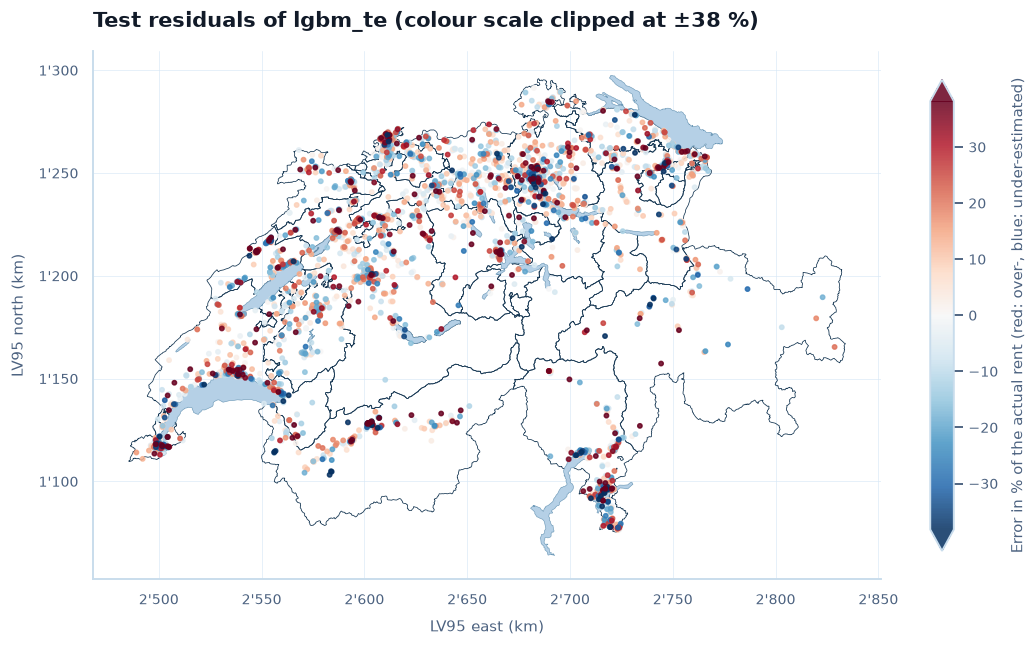

,MAE,RMSE,MedAE,MAPE,R2,n
test (filtered),308.272,607.626,172.040,13.986,0.794,3737
CHF/m² outliers,802.323,1259.368,417.048,60.979,-0.056,525
test + outliers (unfiltered),369.130,720.484,192.631,19.775,0.711,4262


In [56]:
pct_err = 100 * (p_err / y_test - 1)  # > 0 over-, < 0 under-estimated
lim = float(np.quantile(np.abs(pct_err), 0.95))
order = np.argsort(np.abs(pct_err))  # largest errors drawn on top
fig, ax = plt.subplots(figsize=(10, 6.5))
CANTONS.boundary.plot(ax=ax, color=COLORS["dark"], linewidth=0.5)
maps.plot_lakes(ax, LAKES)
sc = ax.scatter(test_df["east"].to_numpy()[order], test_df["north"].to_numpy()[order], zorder=3,
                c=pct_err[order], cmap="RdBu_r", vmin=-lim, vmax=lim, s=8, alpha=0.85,
                rasterized=True)
fig.colorbar(sc, ax=ax, shrink=0.7, extend="both",
             label="Error in % of the actual rent (red: over-, blue: under-estimated)")
ax.xaxis.set_major_formatter(KM)
ax.yaxis.set_major_formatter(KM)
ax.set(xlabel="LV95 east (km)", ylabel="LV95 north (km)", aspect="equal",
       title=f"Test residuals of {ERR_MODEL} (colour scale clipped at ±{lim:.0f} %)")
fig.tight_layout()
resid_png, _ = save_fig(fig, "residual_map")
plt.show()

# Robustness: the CHF/m² outliers of section 6 are in no split. Score the point model on them
# and on test + outliers, i.e. without the target-based filter ("unfiltered").
outl = data.add_engineered_features(df_ppsqm_outliers)
y_out = outl["price"].to_numpy(dtype=float)
p_out = np.exp(lgb_point.predict(encoder.transform(outl)))
robust = pd.DataFrame({
    "test (filtered)": evaluation.regression_metrics(y_test, pred_point_test),
    "CHF/m² outliers": evaluation.regression_metrics(y_out, p_out),
    "test + outliers (unfiltered)": evaluation.regression_metrics(
        np.r_[y_test, y_out], np.r_[pred_point_test, p_out]),
}).T.assign(n=[len(y_test), len(y_out), len(y_test) + len(y_out)])
display(robust.round(3))
track(f"error_analysis_{ERR_MODEL}", "diagnostics",
      {f"test_mae_{BUCKET_KEYS[k]}": v
       for k, v in seg_table.loc["listings per municipality", "MAE"].items()}
      | {"test_mae_q4": dspro2_expensive["mae_chf"],
         "test_mean_error_q4": dspro2_expensive["mean_error_chf"], "coverage_80_q4": q4_cov,
         "outlier_mae": robust["MAE"].iloc[1], "unfiltered_test_mae": robust["MAE"].iloc[2]},
      params={"model": ERR_MODEL, "urban_rural": "muni_density tertiles (train)"},
      tables={"error_segments": seg_table.reset_index()}, artifacts=[resid_png])

**Interpretation.** Read the segments through `bias` (prediction minus actual). Bias falling from
positive in realised band B1 to negative in B4 is regression towards the mean, partly unavoidable
because the realised band selects on the target; in the **predicted** band, the fair comparison,
the bias should be near zero everywhere. MAPE compares bands better than MAE, which grows with the
rent. Segments with small `n` (Italian-speaking region, `<5` bucket) are noisy.

For the expensive quartile, a mean error and mean relative error below DSPRO1's +279 CHF and
14.7 % mean the new pipeline reduced the underestimation; the remaining gap is information the
tabular features lack (view, standard, renovation), which the text (RQ1) is meant to add. The two
rows come from different evaluation sets, so the comparison is indicative. Interval coverage near
80 % in that quartile means the price bands widen the intervals where the point estimate is
weakest.

The worst predictions usually fall into the DSPRO1 categories: implausible targets that survived
cleaning, special objects (penthouses, furnished flats) and ordinary-looking objects the features
cannot explain; their rents are not shown (data licence). The outliers are by construction far
from their municipality's CHF/m², so their large MAE is expected; the relevant number is how much
the test MAE rises once they are added. Coloured clusters in the residual map would mean remaining
location effects (quantified by Moran's I in RQ2).

## 22. Quality-of-Life Index (RQ4): A First Prototype

RQ4 asks whether a valid quality-of-life index can be built without ground truth. Following the
OECD/JRC *Handbook on Constructing Composite Indicators*: directed indicators, winsorised min–max
normalisation to 0–100, equal weights within and user weights across dimensions, linear
aggregation. Validity can only be checked indirectly: rank stability under random weights
(Dirichlet) and convergent validity with independent municipal indicators. This prototype uses the
indicators already attached to the objects; the full index with noise, air and green space is built
in `dspro2_qoli.ipynb`.

| Dimension | Indicator | Source | Status |
|---|---|---|---|
| transport | public-transport accessibility `oev` (log1p) | ARE, DSPRO1 enrichment | enriched objects only |
| sunshine | roof solar suitability class 1–5 `solar` | BFE sonnendach.ch, DSPRO1 enrichment | enriched objects only |
| amenities | OSM accessibility with distance decay `acc_total` | OpenStreetMap (ODbL) | with an OSM cache or `FETCH_OSM=1` |

Population density is **context, not quality** (better access, but also more noise); it is shown
next to the index but not aggregated into it.

In [57]:
OSM_CACHE = CACHE / "osm_amenities.parquet"
osm = qoli_data.fetch_osm_amenities(OSM_CACHE) if FETCH_OSM or OSM_CACHE.is_file() else None
qoli_frame = df_model[["oev", "solar", "east", "north"]].copy()
QOLI_INDICATORS = [
    qoli.Indicator("oev", "transport", True, "ARE public-transport accessibility",
                   transform="log1p"),
    qoli.Indicator("solar", "sunshine", True, "BFE roof solar suitability class 1-5"),
]
if osm is not None:
    qoli_frame = qoli_frame.join(qoli_data.accessibility(qoli_frame, qoli_data.amenity_arrays(osm)))
    QOLI_INDICATORS.append(qoli.Indicator("acc_total", "amenities", True,
                                          "OSM accessibility, cosine decay 400-2400 m"))
QOLI_WEIGHTS = {ind.dimension: 1.0 for ind in QOLI_INDICATORS}  # app sliders; equal by default
qoli_norm = qoli.minmax_normalize(qoli_frame, QOLI_INDICATORS)
qoli_score, qoli_dims = qoli.aggregate(qoli_norm, QOLI_INDICATORS, QOLI_WEIGHTS)
has_qoli = qoli_score.notna()
print(f"dimensions {list(QOLI_WEIGHTS)}; QoLI for {has_qoli.mean():.0%} of "
      f"{len(qoli_score):,} objects (the others miss a weighted dimension)")
density_class = pd.cut(df_model["muni_density"], [-np.inf, *DENSITY_CUTS, np.inf],
                       labels=DENSITY_LABELS)
context = qoli_dims.assign(qoli=qoli_score)[has_qoli].groupby(density_class[has_qoli],
                                                              observed=True)
display(context.median().round(1).assign(n=context.size()).rename_axis("density (context)"))

dimensions ['transport', 'sunshine', 'amenities']; QoLI for 76% of 18,681 objects (the others miss a weighted dimension)


,transport,sunshine,amenities,qoli,n
density (context),,,,,
rural,40.7,50.0,60.3,49.4,4444
intermediate,63.7,50.0,90.2,68.2,4715
urban,77.7,50.0,98.8,75.5,4954


In [58]:
muni_qoli = qoli_score[has_qoli].groupby(df_model["municipality_id"]).agg(["median", "size"])
muni_published = muni_qoli[muni_qoli["size"] >= MIN_MAP_CELL]
muni_dims = qoli_dims[has_qoli].groupby(df_model.loc[has_qoli, "municipality_id"]).median()
sens_rows = {}
for unit, dims in {"objects": qoli_dims[has_qoli],
                   "municipalities": muni_dims.loc[muni_published.index]}.items():
    sens = qoli.weight_sensitivity(dims, n_draws=BUDGET["sensitivity_draws"], seed=RANDOM_STATE,
                                   base_weights=QOLI_WEIGHTS)
    sens_rows[unit] = {"units": len(dims), "spearman_median": sens["spearman"].median(),
                       "spearman_p05": sens["spearman"].quantile(0.05),
                       "top_decile_retention": sens["top_decile_retention"].mean(),
                       "mean_abs_rank_shift_pct": sens["mean_abs_rank_shift_pct"].mean()}
qoli_sensitivity = pd.DataFrame(sens_rows).T.rename_axis("unit").reset_index()
write_table(qoli_sensitivity, "qoli_sensitivity", ".3f",
            note=f"{BUDGET['sensitivity_draws']} Dirichlet draws, session {SESSION_ID}")
print(f"{len(muni_published)} of {len(muni_qoli):,} municipalities have >= {MIN_MAP_CELL} objects "
      "with a QoLI and are published")
display(qoli_sensitivity.round(3))

ppsqm = df_model["price"] / df_model["area"]
value_scores = pd.concat([qoli.value_score(qoli_score.loc[idx], ppsqm.loc[idx])  # peers: language
                          for idx in df_model.groupby("lang_region").groups.values()])
rho_price = qoli_score[has_qoli].corr(ppsqm[has_qoli], method="spearman")
muni_value = muni_published.assign(
    municipality=df_model.groupby("municipality_id")["municipality_name"].first(),
    chf_per_m2=ppsqm.groupby(df_model["municipality_id"]).median(),
    value=value_scores.groupby(df_model["municipality_id"]).median()).sort_values("value")
print(f"Spearman(QoLI, CHF/m²) = {rho_price:+.2f}; published municipalities with the lowest and "
      "highest median value score (within the language region):")
display(pd.concat([muni_value.head(3), muni_value.tail(3)])[
    ["municipality", "size", "median", "chf_per_m2", "value"]].round(1))

EXTERNAL_FILE = EXTERNAL / "bfs_city_statistics.csv"  # municipality_id + numeric indicators
convergent = {}
if EXTERNAL_FILE.is_file():
    external = pd.read_csv(EXTERNAL_FILE, index_col="municipality_id")
    convergent = {col: qoli.convergent_validity(muni_published["median"], external[col])
                  for col in external.select_dtypes("number")}
    display(pd.DataFrame(convergent).T.round(3))
else:
    print(f"No external benchmark at {EXTERNAL_FILE.name}: convergent validity is not assessed "
          "here (see dspro2_qoli.ipynb).")

122 of 1,495 municipalities have >= 20 objects with a QoLI and are published


,unit,units,spearman_median,spearman_p05,top_decile_retention,mean_abs_rank_shift_pct
0,objects,14113.0,0.974,0.848,0.854,5.622
1,municipalities,122.0,0.972,0.881,0.770,5.354


Spearman(QoLI, CHF/m²) = +0.29; published municipalities with the lowest and highest median value score (within the language region):


,municipality,size,median,chf_per_m2,value
municipality_id,,,,,
6240,Lens,44,56.5,42.5,18.4
6253,Crans-Montana,78,60.7,35.2,25.8
295,Horgen,26,65.3,31.7,31.5
6421,La Chaux-de-Fonds,313,69.9,13.7,72.5
5250,Chiasso,78,76.7,14.1,73.9
5242,Balerna,20,77.8,13.1,79.4


No external benchmark at bfs_city_statistics.csv: convergent validity is not assessed here (see dspro2_qoli.ipynb).


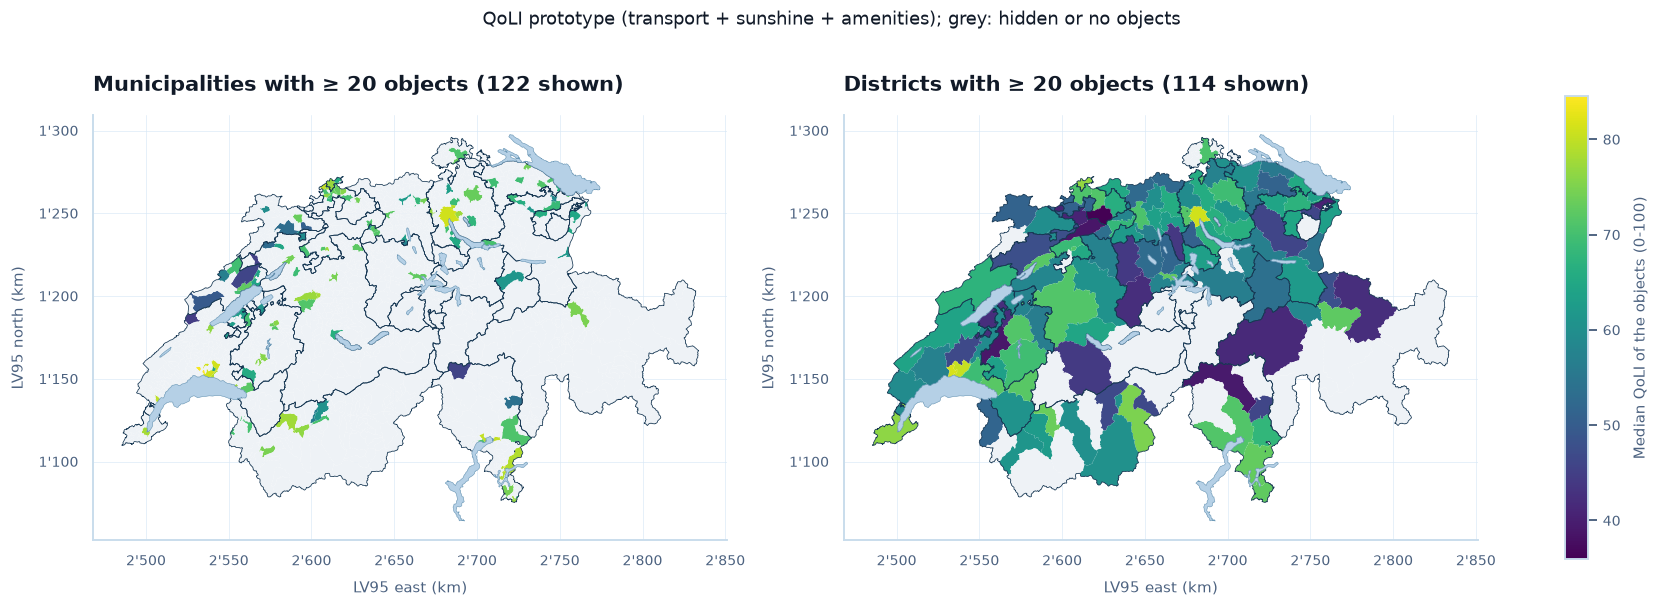

In [59]:
dist_qoli = qoli_score[has_qoli].groupby(df_model["district_id"]).agg(["median", "size"])
dist_published = dist_qoli[dist_qoli["size"] >= MIN_MAP_CELL]
layers = {"municipalities": (admin_units.set_index("municipality_id").geometry, muni_published),
          "districts": (admin_units.dissolve("district_id").geometry, dist_published)}
published = pd.concat([muni_published["median"], dist_published["median"]])
vmin, vmax = published.min(), published.max()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), layout="constrained")
for ax, (unit, (shapes, unit_stats)) in zip(axes, layers.items(), strict=True):
    frame = shapes.simplify_coverage(50).to_frame("geometry")
    frame["qoli"] = unit_stats["median"].reindex(frame.index).to_numpy()
    frame.plot(ax=ax, column="qoli", cmap="viridis", vmin=vmin, vmax=vmax, linewidth=0,
               missing_kwds={"color": "#EEF2F6"})
    CANTONS.boundary.plot(ax=ax, color=COLORS["dark"], linewidth=0.5)
    maps.plot_lakes(ax, LAKES)
    ax.xaxis.set_major_formatter(KM)
    ax.yaxis.set_major_formatter(KM)
    ax.set(xlabel="LV95 east (km)", ylabel="LV95 north (km)", aspect="equal",
           title=f"{unit.capitalize()} with ≥ {MIN_MAP_CELL} objects ({len(unit_stats)} shown)")
fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(vmin, vmax), "viridis"), ax=axes, shrink=0.8,
             label="Median QoLI of the objects (0-100)")
fig.suptitle(f"QoLI prototype ({' + '.join(QOLI_WEIGHTS)}); grey: hidden or no objects")
qoli_png, _ = save_fig(fig, "qoli_map")
plt.show()
track("qoli_prototype", "qoli",
      {"qoli_coverage": has_qoli.mean(), "n_munis_published": len(muni_published),
       "n_districts_published": len(dist_published), "spearman_qoli_ppsqm": rho_price}
      | {f"{r['unit']}_{k}": r[k] for _, r in qoli_sensitivity.iterrows()
         for k in ("spearman_median", "top_decile_retention")}
      | {f"convergent_rho_{k}": v["rho"] for k, v in convergent.items()},
      params={"indicators": ",".join(i.name for i in QOLI_INDICATORS), "winsor": "0.01/0.99",
              "min_map_cell": MIN_MAP_CELL, "osm": osm is not None},
      tables={"qoli_municipalities": muni_published, "qoli_districts": dist_published},
      artifacts=[qoli_png])

**Missing dimensions: how noise will enter.** The noise dimension samples the BAFU sonBASE rasters
(road and rail, L<sub>r,Tag</sub> 06–22 h and L<sub>r,Nacht</sub> 22–06 h) at the building and
compares them with the LSV impact thresholds (sensitivity level II: 60 dB(A) day, 50 dB(A) night),
road and rail separately. `lsv_exceedance` on four **made-up** points (`<NA>` where unknown):

In [60]:
noise_demo = pd.DataFrame({"road_day_db": [55.0, 62.5, 58.0, np.nan],
                           "road_night_db": [45.0, 49.0, 53.5, 47.0]},
                          index=pd.Index(["A", "B", "C", "D"], name="illustrative point"))
noise_demo.join(qoli.lsv_exceedance(noise_demo["road_day_db"], noise_demo["road_night_db"]))

,road_day_db,road_night_db,day_excess_db,exceeds_day,night_excess_db,exceeds_night,exceeds_any
illustrative point,,,,,,,
A,55.0,45.0,0.0,False,0.0,False,False
B,62.5,49.0,2.5,True,0.0,False,True
C,58.0,53.5,0.0,False,3.5,True,True
D,NaN,47.0,NaN,<NA>,0.0,False,<NA>


**Interpretation.** With two or three dimensions this prototype answers "how well connected and
how sunny", not "how good a place to live".

- **Coverage.** The index exists only for objects with DSPRO1 enrichment, because `oev` and
  `solar` come from that step; a direct spatial join of the ARE and BFE layers removes this gap.
- **Rank stability.** A median Spearman above about 0.9 and a high top-decile retention mean the
  ranking does not hinge on the exact weights, which users need when they move the sliders.
- **Convergent validity** cannot be claimed without an external benchmark; RQ4 stays open here.
- **Value score** ("more QoLI per CHF/m² than peers in the same language region") is descriptive;
  a positive QoLI–CHF/m² correlation means part of the quality is priced in.

The map applies the app's publication rule (at least `MIN_MAP_CELL` objects per unit); few
municipalities pass it, so the district panel is the more complete picture.

## 23. Fair-Rent Check and What-If: The App Contract

The Dash app must not retrain anything. It loads one `RentModelBundle` from
`models/rent_bundle_v2.joblib` (start the app with
`RENTML_MODEL_BUNDLE=models/rent_bundle_v2.joblib` to serve it):

| Field | Content |
|---|---|
| `encoder` | the fitted target-encoding step of section 13: raw rows (with `re_*` keys) → model matrix |
| `point_model` | `lgb_point`, monotone LightGBM on the log rent (estimate and what-if) |
| `quantile_model` | `qmodel`, monotone quantile LightGBM, trained on the same encoded matrix |
| `calibrator` | `mondrian`, the Mondrian CQR of section 19 (language region × predicted band) |
| `band_cutpoints` | log-scale cutpoints of the predicted-rent band (calibration set) |
| `metadata` | interval levels, data source, session, metrics, disclaimer |

`predict_frame`, `fair_rent_check` and `what_if` take raw rows; engineered features are recomputed
with `data.add_engineered_features`, exactly as in training.

**What "fair" means here.** The verdict compares an asking rent with current asking rents of
comparable apartments. It is **not** the legal notion of a non-abusive rent (Art. 269 ff. OR), and
the app gives no legal assessment. Tenants who consider contesting an initial rent (Art. 270 OR)
are referred to the Federal Office for Housing (BWO, www.bwo.admin.ch) and the tenant associations
(www.mieterverband.ch). The app does not store its inputs.

In [61]:
point_metrics = evaluation.regression_metrics(y_test, pred_point_test)
bundle = intervals.RentModelBundle(
    encoder=encoder, point_model=lgb_point, quantile_model=qmodel, calibrator=mondrian,
    band_cutpoints=band_cutpoints,
    metadata={
        "version": "rent_bundle_v2", "created": pd.Timestamp.now().isoformat(timespec="seconds"),
        "session": SESSION_ID, "run_mode": RUN_MODE, "data_source": DATA_USED,
        "snapshot_date": OBSERVED, "reference_year": REFERENCE_YEAR,
        "feature_cols": F_LGB, "group_cols": GROUP_COLS, "interval_levels": mondrian.levels,
        "coverage": INTERVAL_COVERAGE, "rq2_winner": RQ2_WINNER,
        "monotone_increasing": list(MONOTONE_INCREASING),
        "test_metrics_point": point_metrics,
        "disclaimer": "Estimate of current asking rents for comparable apartments; "
                      "not a legal assessment (Art. 269 ff. OR).",
    })
bundle_test = intervals.predict_frame(bundle, test_df)
bundle_calib = intervals.predict_frame(bundle, calib_df)
lo_q, hi_q = iv_test_all["mondrian_quantile"]
same_as_rq3 = np.allclose(bundle_test["lo"], lo_q) and np.allclose(bundle_test["hi"], hi_q)
bundle_cov = pd.concat({
    "calibration": intervals.coverage_report(y_calib, bundle_calib["lo"], bundle_calib["hi"]),
    "test": intervals.coverage_report(y_test, bundle_test["lo"], bundle_test["hi"]),
}).droplevel(1)
bundle.metadata["interval_metrics"] = bundle_cov.round(4).to_dict(orient="index")
bundle.save(BUNDLE_PATH)
bundle = intervals.RentModelBundle.load(BUNDLE_PATH)  # from here on: the app's view
reloaded = intervals.predict_frame(bundle, test_df.iloc[:50])
cols = ["expected", "lo", "hi"]
assert np.allclose(reloaded[cols], bundle_test.iloc[:50][cols])
print(f"saved {BUNDLE_PATH.name} ({BUNDLE_PATH.stat().st_size / 1e6:.1f} MB); reload identical; "
      f"reproduces the mondrian_quantile test intervals: {same_as_rq3}")
display(bundle_cov.round(3))
track("rent_bundle_v2", "app",
      {"test_mae": point_metrics["MAE"], "test_rmse": point_metrics["RMSE"],
       "coverage_80": bundle_cov.loc["test", "coverage"],
       "mean_width": bundle_cov.loc["test", "mean_width"],
       "calib_coverage_80": bundle_cov.loc["calibration", "coverage"]},
      params={"point_model": "lgb_point", "n_features": len(F_LGB), "rq2_winner": RQ2_WINNER},
      artifacts=[BUNDLE_PATH])

saved rent_bundle_v2.joblib (7.1 MB); reload identical; reproduces the mondrian_quantile test intervals: True


,n,coverage,below,above,mean_width,median_width,cp_low,cp_high
calibration,3736,0.800,0.100,0.10,1048.255,732.320,0.787,0.813
test,3737,0.807,0.103,0.09,1034.435,735.525,0.794,0.819


In [62]:
check_ids = [shap_ids[EXAMPLES["median"]], shap_ids[EXAMPLES["expensive"]]]
rent_checks = []
for lid in check_ids:  # asking rents relative to the estimate: no actual rent is shown
    row = test_df.loc[[lid]]
    expected = float(intervals.predict_frame(bundle, row)["expected"].iloc[0])
    explanation = models.tree_shap(bundle.point_model, bundle.encoder.transform(row))
    drivers = models.top_drivers(explanation, 0, k=3)  # the app's SHAP call
    for label, factor in [("estimate", 1.0), ("-15 %", 0.85), ("+15 %", 1.15)]:
        res = intervals.fair_rent_check(bundle, row, round(expected * factor))
        rent_checks.append({"object": f"{row['area'].iloc[0]:.0f} m², {row['canton'].iloc[0]}",
                            "asking": label, "asking_chf": res.asking, "lo_chf": res.lo,
                            "hi_chf": res.hi, "verdict": res.verdict,
                            "percentile": res.percentile, "cell": res.cell})
    print(f"{rent_checks[-3]['object']}: drivers " + "; ".join(
        f"{d.feature} {d.approx_pct:+.0f} %" for d in drivers.itertuples()))
display(pd.DataFrame(rent_checks).round(2).style.hide(axis="index"))

# The estimate is the point model; interval and percentile come from the separately fitted
# quantile grid. How consistent are the two on the test set?
pct_of_point = intervals.market_percentiles(qmodel.predict(X_test_lgb), LEVELS,
                                            np.log(bundle_test["expected"].to_numpy()))
point_vs_q50 = bundle_test["expected"] / bundle_test["q50"] - 1
outside = ((bundle_test["expected"] < bundle_test["lo"])
           | (bundle_test["expected"] > bundle_test["hi"]))
print(f"point estimate outside its 80 % interval: {outside.mean():.1%}; outside the 40th-60th "
      f"percentile of its grid: {np.mean((pct_of_point < 0.4) | (pct_of_point > 0.6)):.1%}; "
      "point / q50 - 1 (5 / 50 / 95 %): "
      + " / ".join(f"{point_vs_q50.quantile(a):+.1%}" for a in (0.05, 0.5, 0.95)))

93 m², SG: drivers area +4 %; year_built +3 %; re_canton -2 %


94 m², AG: drivers oev +11 %; area_per_room +8 %; re_district +7 %


object,asking,asking_chf,lo_chf,hi_chf,verdict,percentile,cell
"93 m², SG",estimate,1745,1635.950000,2136.530000,within,0.330000,de × B3
"93 m², SG",-15 %,1483,1635.950000,2136.530000,below,0.020000,de × B3
"93 m², SG",+15 %,2007,1635.950000,2136.530000,within,0.800000,de × B3
"94 m², AG",estimate,3127,1675.570000,2744.500000,above,0.990000,de × B3
"94 m², AG",-15 %,2658,1675.570000,2744.500000,within,0.860000,de × B3
"94 m², AG",+15 %,3596,1675.570000,2744.500000,above,0.990000,de × B3


point estimate outside its 80 % interval: 0.4%; outside the 40th-60th percentile of its grid: 42.3%; point / q50 - 1 (5 / 50 / 95 %): -10.6% / +0.4% / +15.9%


In [63]:
what_if_table = pd.concat(
    [intervals.what_if(bundle, test_df.loc[[lid]], area_grid=[test_df.loc[lid, "area"] + 10,
                                                              test_df.loc[lid, "area"] + 20])
     .assign(object=f"{test_df.loc[lid, 'area']:.0f} m²") for lid in check_ids], ignore_index=True)
display(what_if_table[["object", "feature", "value", "expected", "lo", "hi", "q25", "q75",
                       "delta", "delta_pct"]].round(1).style.hide(axis="index"))
# the same +10 / +20 m² what-if for every test object, with area_per_room recomputed as in the app
wi_all = np.column_stack([lgb_point.predict(encoder.transform(data.add_engineered_features(
    test_df.assign(area=test_df["area"] + step)))) for step in (0, 10, 20)])
WHAT_IF_MONOTONE = bool((np.diff(wi_all, axis=1) >= -1e-12).all()
                        and (what_if_table.groupby("object")["delta"].diff().dropna() >= 0).all())
print(f"{'PASS' if WHAT_IF_MONOTONE else 'FAIL'}  estimate never decreases when the area grows by "
      f"10 or 20 m² ({len(test_df):,} test objects)")

object,feature,value,expected,lo,hi,q25,q75,delta,delta_pct
93 m²,baseline,nan,1745.300000,1636.000000,2136.500000,1701.600000,1950.500000,0.000000,0.000000
93 m²,area,103.000000,1783.100000,1685.700000,2203.600000,1753.300000,2012.700000,37.900000,2.200000
93 m²,area,113.000000,1947.600000,1791.800000,2402.900000,1863.800000,2158.300000,202.300000,11.600000
94 m²,baseline,nan,3126.700000,1675.600000,2744.500000,1865.100000,2384.800000,0.000000,0.000000
94 m²,area,104.000000,3181.100000,1763.800000,2937.600000,1964.700000,2607.500000,54.400000,1.700000
94 m²,area,114.000000,3257.600000,1871.000000,3153.700000,2085.100000,2850.900000,130.900000,4.200000


PASS  estimate never decreases when the area grows by 10 or 20 m² (3,737 test objects)


**Interpretation.** An asking rent equal to the estimate is usually *within*; ±15 % pushes it
towards or beyond the interval edges, and the market percentile moves with it. Where the model is
less certain (relatively wide interval) the same change flips the verdict less often, so the check
is more cautious exactly there. *Above* is a prompt to look closer, not a finding of an abusive
rent.

**Estimate vs. percentile.** The estimate is `lgb_point` (it drives the monotone what-if); interval,
landlord band (q25–q75) and percentile come from the separately fitted quantile models. If the
consistency shares are small, the two tell the same story; if not, the app should show q50 next to
the estimate. The verdict always comes from the calibrated interval. The bundle checks guard the
hand-over: calibration coverage at least nominal by construction, identical predictions after
reload, the RQ3 intervals reproduced, and `delta` never negative for a larger area.

## 24. Reporting: Ablation Table and Model Card

No number in the report is typed by hand. The ablation table is rendered from the tracked runs of
this session; within a stage, the run is chosen by its CV MAE, never by a test metric. The LOO kNN
reproduction is excluded from the selection (its CV MAE is optimistic by construction, section
12.1), and the `tabular+geo` row is always the RQ2 winner, because RQ1 builds on it. The `dspro1`
row has its own location features, so the `tabular` row, which drops all location information,
has a negative gain by design; the pre-registered chain starts at `tabular`.

In [64]:
runs = evaluation.load_runs(EXPERIMENT)
session_runs = runs[runs["tags.session"].eq(SESSION_ID)]
candidates = session_runs[session_runs["params.knn_mode"].ne("loo")
                          & (session_runs["tags.stage"].ne("tabular+geo")
                             | session_runs["tags.mlflow.runName"].eq(RQ2_WINNER))]
ABLATION_STAGES = ["baseline", "dspro1", "tabular", "tabular+geo", "text", "attributes", "fused",
                   "portal"]
ablation = evaluation.ablation_table(
    candidates, ABLATION_STAGES, ["cv_mae", "test_mae", "test_rmse", "test_mape", "test_r2",
                                  "test_mae_lt5"])
ablation["runs_in_stage"] = candidates["tags.stage"].value_counts().reindex(ablation.index)
ablation[["mae_ci_low", "mae_ci_high", "gain_vs_prev", "p_vs_prev"]] = np.nan
prev = None
for stage, name in ablation["run_name"].items():
    _, lo, hi = evaluation.bootstrap_ci(y_test, pred_test[name], "MAE", n_boot=BUDGET["n_boot"])
    ablation.loc[stage, ["mae_ci_low", "mae_ci_high"]] = [lo, hi]
    if prev is not None:  # MAE(previous stage) - MAE(this stage): > 0 means this stage helps
        cmp = evaluation.paired_bootstrap_mae(y_test, pred_test[prev], pred_test[name],
                                              n_boot=BUDGET["n_boot"])
        ablation.loc[stage, ["gain_vs_prev", "p_vs_prev"]] = [cmp.diff, cmp.p_bootstrap]
    prev = name
abl_fmt = {"cv_mae": ".0f", "test_mae": ".0f", "test_rmse": ".0f", "test_mape": ".1f",
           "test_r2": ".3f", "test_mae_lt5": ".0f", "runs_in_stage": ".0f", "mae_ci_low": ".0f",
           "mae_ci_high": ".0f", "gain_vs_prev": "+.1f", "p_vs_prev": ".3g"}
write_table(ablation.reset_index(), "ablation", abl_fmt,
            note=f"session {SESSION_ID}, data {DATA_USED}, run {RUN_MODE}; one run per stage "
                 f"chosen by cv_mae; CI: bootstrap ({BUDGET['n_boot']} draws); p_vs_prev "
                 "unadjusted (Holm-adjusted RQ1 tests: section 17)",
            caption="Ablation by stage: one run per stage chosen by cross-validation MAE; test "
                    "metrics on the frozen hold-out set (CHF) with 95 % bootstrap CI of the MAE "
                    "and the paired MAE gain over the previous stage.")
print(f"{len(session_runs)} runs in session {SESSION_ID}")
display(ablation.round(3))

30 runs in session 20261108-193155


,run_name,cv_mae,test_mae,test_rmse,test_mape,test_r2,test_mae_lt5,runs_in_stage,mae_ci_low,mae_ci_high,gain_vs_prev,p_vs_prev
stage,,,,,,,,,,,,
baseline,naive,441.012,429.175,728.806,20.701,0.703,439.151,1,411.084,447.328,NaN,NaN
dspro1,dspro1_knn_oof,337.454,321.917,640.231,14.537,0.771,301.458,1,304.302,339.672,107.258,0.000
tabular,lgbm_tab,368.777,355.215,680.742,16.107,0.741,367.358,1,337.204,373.941,-33.298,0.000
tabular+geo,lgbm_te,321.243,308.272,607.626,13.986,0.794,291.534,1,291.228,324.845,46.943,0.000
text,lgbm_te+s1,287.528,281.773,568.339,12.738,0.819,273.397,2,265.966,298.222,26.499,0.000
attributes,lgbm_te+s3,287.337,281.720,577.045,12.666,0.814,270.552,1,265.725,298.906,0.052,0.973
fused,fused_nn,334.479,322.165,616.928,14.554,0.787,332.648,1,305.862,339.054,-40.445,0.000
portal,lgbm_te+portal,284.711,280.115,576.324,12.589,0.814,266.899,1,263.978,297.002,42.050,0.000


In [65]:
mae_point, mae_lo, mae_hi = evaluation.bootstrap_ci(y_test, p_err, "MAE", n_boot=BUDGET["n_boot"])
card_metrics = pd.DataFrame({name: evaluation.regression_metrics(y_test, p) for name, p in
                             {ERR_MODEL: p_err, "lgb_point (app)": pred_point_test,
                              "naive baseline": pred_test["naive"]}.items()}).T
card_metrics["MAE 95 % CI"] = [f"{mae_lo:,.0f}–{mae_hi:,.0f}", "", ""]
test_cov = float(bundle_cov.loc["test", "coverage"])
const_half = intervals.constant_band_for_coverage(y_test, pred_point_test, test_cov)
app_cells = intervals.coverage_report(y_test, bundle_test["lo"], bundle_test["hi"],
                                      bundle_test["cell"].rename("cell")).drop(index="all")
worst_cell = app_cells["coverage"].idxmin()
git_commit = subprocess.run(["git", "rev-parse", "--short=10", "HEAD"], capture_output=True,
                            text=True, check=False).stdout.strip() or "unknown"
fmt_row = " / ".join
card = [
    "# Model card: DSPRO2 rent model (`rent_bundle_v2`, Comparis data)", "",
    f"*Generated by `dspro2_ml_pipeline_comparis.ipynb` on {pd.Timestamp.now():%Y-%m-%d}; session "
    f"`{SESSION_ID}`, run mode `{RUN_MODE}`, data source `{DATA_USED}`, git `{git_commit}`.*",
    "", "## Model",
    f"- Point model for the app and the what-if: LightGBM on the log rent, monotone increasing in "
    f"{list(MONOTONE_INCREASING)}; {len(F_LGB)} features (tabular, LV95 coordinates, target "
    "encodings of canton, district and municipality).",
    f"- Model of record for RQ2: `{RQ2_WINNER}`.",
    f"- Intervals: monotone quantile LightGBM (levels {', '.join(f'{q:g}' for q in LEVELS)}) "
    f"with asymmetric Mondrian CQR by language region × predicted band, nominal "
    f"{INTERVAL_COVERAGE:.0%}.",
    "- Artefact: `models/rent_bundle_v2.joblib` (joblib pickle: load trusted files only).",
    "", "## Intended use",
    "- Informational estimate of the current **asking** net rent of a Swiss apartment with a "
    f"calibrated {INTERVAL_COVERAGE:.0%} interval, a verdict (below / within / above), a market "
    "percentile and the main drivers (Fair-Rent Check, landlord price band and what-if).",
    "- Market analysis and teaching; maps publish only cells with at least "
    f"{MIN_MAP_CELL} objects.",
    "", "## Out of scope",
    "- Legal assessment of a rent (non-abusive rent, Art. 269 ff. OR; contesting the initial rent, "
    "Art. 270 OR). The app links to the BWO and the tenant associations instead.",
    "- Decisions about individuals: tenant screening, credit or insurance decisions, automated "
    "approval or rejection of applications.",
    "- Sitting-tenant rents, cooperative or subsidised rents, commercial property, locations "
    "outside Switzerland, street-level price maps. Furnished and temporary rentals are part of "
    "the training data (flagged only when text is available); estimates for them are less "
    "reliable.",
    "", "## Data",
    f"- Listings: Comparis scrape ({OBSERVED}), all partner portals, one row per rental "
    f"object after the duplicate audit: {len(train_df):,} train / {len(calib_df):,} calibration / "
    f"{len(test_df):,} test objects, grouped by object, stratified by canton × price quartile.",
    "- Enrichment: GWR building data (BFS MADD) and ARE/BFE/swisstopo location indicators for "
    f"{df_model['egid'].notna().mean():.0%} of the objects (EGID found), living area from the GWR "
    f"for {df_model['area_from_gwr'].mean():.1%}; swissBOUNDARIES3D {SB3D_VERSION} hierarchy.",
    "- Listing text: " + ("anonymised descriptions." if HAS_TEXT
                          else f"not available in this run (data source {DATA_USED})."),
    "- Licence: listings are used for training and evaluation only; no listing text, price or "
    "address is redistributed.",
    "", f"## Metrics (frozen hold-out test set, {len(test_df):,} objects, CHF)", "",
    card_metrics.reset_index(names="").to_markdown(
        index=False, floatfmt=("", ".0f", ".0f", ".0f", ".1f", ".3f", "")),
    f"- MAE by listings per municipality ({ERR_MODEL}): "
    + fmt_row(f"{k} {v:,.0f}" for k, v in seg_table.loc["listings per municipality", "MAE"].items())
    + "; by language region: "
    + fmt_row(f"{k} {v:,.0f}" for k, v in seg_table.loc["language region", "MAE"].items()) + ".",
    f"- Expensive quartile (actual ≥ {dspro2_expensive['threshold_chf']:,.0f} CHF): mean error "
    f"(actual − prediction) {dspro2_expensive['mean_error_chf']:+,.0f} CHF, mean relative error "
    f"{dspro2_expensive['mean_rel_error_pct']:.1f} % (DSPRO1: +279 CHF, 14.7 %).",
    "", "## Intervals",
    f"- Test coverage {test_cov:.1%} (nominal {INTERVAL_COVERAGE:.0%}), mean width "
    f"{bundle_cov.loc['test', 'mean_width']:,.0f} CHF; a constant band with the same coverage is "
    f"{2 * const_half:,.0f} CHF wide.",
    f"- Lowest coverage among the served Mondrian cells: {worst_cell} "
    f"{app_cells.loc[worst_cell, 'coverage']:.1%} (n = {int(app_cells.loc[worst_cell, 'n'])}).",
    "", "## Limitations",
    "- Asking rents, not contract rents; one snapshot, so no temporal drift test yet: retrain and "
    "recalibrate before use on later data.",
    "- Larger errors and wider intervals for expensive and unusual objects; municipalities with "
    "few listings lean on district and canton encodings.",
    f"- Location indicators (public transport, solar) are missing for {1 - has_qoli.mean():.0%} of "
    f"the objects; the QoLI prototype here covers {len(QOLI_WEIGHTS)} dimensions.",
    "- " + (f"The served model uses the S0 feature set without text (CV selected {RQ1_SELECTED} "
            "in RQ1); text features enter the app in a later version." if HAS_TEXT else
            "This run had no listing text: RQ1 is untested and the model cannot see view, "
            "standard or renovation."),
    "", "## Regulation and privacy",
    "- revDSG (Swiss Federal Act on Data Protection, in force since 1 September 2023): no personal "
    "data are model features; descriptions are anonymised before storage or LLM use; the app does "
    f"not store inputs; aggregates need at least {MIN_MAP_CELL} objects.",
    "- EU AI Act (Regulation (EU) 2024/1689): relevant only if the app is offered in the EU. As an "
    "informational tool that does not decide on access to housing, credit or services, it is not "
    "expected to fall under the high-risk use cases of Annex III. Users are told that the estimate "
    "comes from a statistical model, with its interval and drivers. Use for tenant screening would "
    "change this assessment and is out of scope.",
]
(RESULTS_DIR / "model_card.md").write_text("\n".join(card) + "\n")
track("report_tables", "reporting", {}, artifacts=[RESULTS_DIR / f for f in (
    "ablation.md", "ablation.tex", "model_card.md", "error_segments.md", "qoli_sensitivity.md")])
print(f"MAE {ERR_MODEL}: {mae_point:,.0f} CHF (95 % CI {mae_lo:,.0f}–{mae_hi:,.0f}); test coverage "
      f"{test_cov:.1%}; wrote ablation.md/.tex and model_card.md")

MAE lgbm_te: 308 CHF (95 % CI 291–325); test coverage 80.7%; wrote ablation.md/.tex and model_card.md


**Interpretation.** Each ablation row is the run a user would have chosen without looking at the
test set. If CV and test MAE fall together from stage to stage, the improvements generalise; if
their orderings disagree, the differences are within noise and the paired tests of RQ1/RQ2 decide.
Stages that did not run (text stages without descriptions) are absent. The model card is
regenerated on every run; copy it into the report only from a full run on the frozen data source.

## 25. Summary: Decisions, Limits and Next Steps

The decisions are printed from the variables of this run, in the pre-registered order (RQ2 → RQ1 →
RQ3), followed by RQ4. They are final only after a full run on the frozen data source with the
evaluation plan tagged as `eval-plan-v1`.

In [66]:
rq2 = rq2_by_segment["all"]
better = "gpboost" if rq2.ci_low > 0 else "lgbm_te" if rq2.ci_high < 0 else None
print(f"RQ2  winner {RQ2_WINNER}: MAE lgbm_te {rq2.mae_a:,.0f} vs gpboost {rq2.mae_b:,.0f} CHF, "
      f"difference {rq2.diff:+,.1f} (95 % CI {rq2.ci_low:+,.1f} to {rq2.ci_high:+,.1f}, "
      f"Wilcoxon p = {rq2.p_wilcoxon:.3g}) -> "
      + ("no detectable difference" if better is None else f"{better} significantly better")
      + f"; H2a {'supported' if better == 'gpboost' else 'not supported'}")
print("RQ1  " + ("not tested: no listing text in this run" if rq1_table is None else
                 f"selected by CV: {RQ1_SELECTED}; supported stages: "
                 f"{list(rq1_table.index[rq1_table['supported']]) or 'none'}"))
print(f"RQ3  {PRIMARY_IV}: coverage {r3['coverage']:.1%}; H3a "
      f"{'supported' if decision_rq3.loc[0, 'supported'] else 'not supported'} "
      f"({decision_rq3.loc[0, 'estimate']}); H3b "
      f"{'supported' if decision_rq3.loc[1, 'supported'] else 'not supported'} "
      f"(width ratio {r3['width_ratio']:.2f})")
print(f"RQ4  QoLI prototype on {len(QOLI_WEIGHTS)} dimensions for {has_qoli.mean():.0%} of the "
      "objects; median rank Spearman under weight perturbation "
      + ", ".join(f"{u} {s:.2f}" for u, s in zip(qoli_sensitivity["unit"],
                                                  qoli_sensitivity["spearman_median"], strict=True))
      + f"; convergent validity {'assessed' if convergent else 'open here'}")
limitations = [
    "living area filled from the GWR for "
    f"{df_model['area_from_gwr'].mean():.1%} of the objects (proxy, flagged)",
    "single snapshot (one observed_at date): no temporal drift test",
    f"QoLI prototype on {len(QOLI_WEIGHTS)} dimensions; noise, air and green in dspro2_qoli.ipynb",
    f"test set of {len(test_df):,} objects is below the planned 2,000: per-segment comparisons "
    "are exploratory" if len(test_df) < 2000 else None,
    "fast mode: reduced budgets (folds, trials, bootstrap draws); rerun in full" if FAST else None,
]
print("Limitations:\n" + "\n".join(f"  - {item}" for item in limitations if item))

RQ2  winner lgbm_te: MAE lgbm_te 308 vs gpboost 327 CHF, difference -19.0 (95 % CI -26.1 to -12.4, Wilcoxon p = 6.59e-10) -> lgbm_te significantly better; H2a not supported
RQ1  selected by CV: S3; supported stages: ['S1']
RQ3  mondrian_quantile: coverage 80.7%; H3a not supported (11 of 12 cells pass; failing: it × B4 62.9% (n = 62)); H3b not supported (width ratio 1.24)
RQ4  QoLI prototype on 3 dimensions for 76% of the objects; median rank Spearman under weight perturbation objects 0.97, municipalities 0.97; convergent validity open here
Limitations:
  - living area filled from the GWR for 11.6% of the objects (proxy, flagged)
  - single snapshot (one observed_at date): no temporal drift test
  - QoLI prototype on 3 dimensions; noise, air and green in dspro2_qoli.ipynb


**Conclusion.** The notebook tells the DSPRO2 story end to end: a deduplicated object table with an
official geo hierarchy, a frozen split and pre-registered plan, a spatial comparison (RQ2) decided
by a paired bootstrap, calibrated per-apartment intervals (RQ3), explanations, an error analysis
against the DSPRO1 weak spots, a QoLI prototype and a model bundle that the app serves without
retraining. Where a decision reads "no detectable difference" or "not supported", that is the
result, bounded by the MDE of section 11.

**Next steps**

1. **Compare with the DSPRO1-snapshot run** (`docs/results/` vs `docs/results/comparis/`): MAE,
   coverage and the RQ decisions on far more objects, with text.
2. **Tag `eval-plan-v1`** after one full run on the frozen Comparis data (MDE table into the plan).
3. **Serve `rent_bundle_v2`** in the app (`RENTML_MODEL_BUNDLE`) and copy the map layers from
   `data/app/comparis/` if the Comparis maps should replace the DSPRO1 ones.
4. **Text and portal features in the app bundle** if RQ1 or stage P show a clear gain.
5. **Temporal check** on listings collected after the data freeze (drift test set of the proposal).